# Risco de dengue grave ou óbito por perfil de comorbidades — SINAN/DataSUS 2022–2024

**Notebook `modelo_risco_dengue.ipynb`** — gerado por `notebooks/build_modelo_risco_dengue.py` a
partir do código testado de `src/dengue_sinan/`. Não edite as células de código copiadas: edite o
módulo e regere.

> **Projeto acadêmico.** Este material não é ferramenta clínica, não substitui a avaliação médica nem
> os protocolos oficiais do Ministério da Saúde (MS), e **nenhuma associação aqui é causal**.

## 1. Contextualização e objetivos

Fonte única do objetivo: `specs/goal.md`. Em resumo, para um **caso confirmado de dengue no Brasil**
(SINAN/DataSUS, 2022–2024), estimar a probabilidade de evoluir para **dengue grave ou óbito pelo
agravo**.

| Eixo | Pergunta | Instrumento principal |
|---|---|---|
| **Principal — associação** | Quais comorbidades e combinações se associam a maior risco, ajustando por idade e sexo? | Logística **sem penalização** com interações (E1): OR, RERI/AP, IC 95%, Benjamini-Hochberg |
| **Secundário — predição** | Qual o risco individual **no primeiro atendimento**? | Candidatos M1 (elastic net, Random Forest, gradiente boosting), validação leave-one-region-out, calibração |
| **Comparação** | O ML acrescenta algo à regra do MS? | Regra do grupo B do protocolo (B2) nos **mesmos pacientes e desfechos**; curva de decisão, reclassificação |

**Definições (spec §3.6)**

- *População:* `CLASSI_FIN` ∈ {10, 11, 12} **e** rótulo conhecido (12 com qualquer evolução; 10/11 só
  com `EVOLUCAO` ∈ {1, 2}) **e** idade válida em [0, 120] (com *fallback* por `ANO_NASC`).
- *Desfecho:* `y = 1` se `CLASSI_FIN = 12` (dengue grave) **ou** `EVOLUCAO = 2` (óbito pelo agravo).
- *Momento da predição:* notificação (primeiro atendimento). Nada posterior entra como variável.
- *Divisão:* desenvolvimento 2022–2023 (validação **leave-one-region-out**); teste **2024**, congelado
  e usado **uma única vez** (lacre).

### Decisões e conflitos entre o enunciado da tarefa e os artefatos do projeto

Pela regra de precedência (constituição > spec > roteiro > arquitetura > boas práticas), valeu o
projeto. Os conflitos relevantes e a decisão tomada:

| # | Enunciado pede | Projeto determina | Decisão |
|---|---|---|---|
| 1 | Tratar o desbalanceamento nos dados de treino | **R3/D-38: nenhuma correção** (sem pesos de classe, SMOTE, subamostragem); recall via limiar; calibração depois | **Segue o projeto.** Prevalência natural (~0,2%) preservada; limiar escolhido pelo F2 em predições fora da dobra |
| 2 | Validação temporal, cruzada e teste independente | Desenvolvimento 2022–23 com leave-one-region-out; teste 2024 | **Segue o projeto**, que já cumpre os três |
| 3 | Modelos "como Random Forest e Gradient Boosting" | Seis candidatos obrigatórios (inclui CatBoost, MLP, TabFM) | **Parcial.** Aqui: elastic net, RF e gradient boosting (XGBoost; HistGradientBoosting se ausente). CatBoost, MLP e TabFM exigem dependências/GPU ainda não aprovadas (tarefa T-2.0) e **ficam pendentes** |
| 4 | AUROC e AUPRC | PR-AUC é a métrica primária (D-09) | Reporta-se **ambas**; seleção por PR-AUC |
| 5 | "Outras condições disponíveis" | Só as 7 comorbidades da ficha; asma, DPOC e obesidade (que o protocolo cita) **não existem** na ficha | Limitação registrada |
| 6 | Otimizar hiperparâmetros | Espaço de busca é a pergunta aberta **Q-08**, reservada ao Programador; Optuna/MLflow não estão instalados | **Grade pequena e declarada** (`[ASSUMPTION]`, configurável), critério PR-AUC média nas dobras. **Precisa de aprovação** |
| 7 | Dependências | Adicionar ao `pyproject.toml` exige aprovação (T-2.0) | **`pyproject.toml` não foi alterado.** A célula de configuração instala o que faltar com `pip` |

Marcadores do projeto: `[ASSUMPTION]` = inferência a confirmar; `[VERIFY]` = fato a conferir nos dados.

## 2. Configuração e dependências

- **Local:** `jupyter nbconvert --to notebook --execute --inplace notebooks/modelo_risco_dengue.ipynb`
  (ou abra no Jupyter) a partir da raiz do repositório.
- **Colab:** *Ambiente de execução → Executar tudo*. O Drive é montado e tudo fica em
  `MyDrive/dengue-comorbidity-risk/` (dados em `data/`, saídas em `reports/modelo_risco_dengue/`).
- **Dados:** os microdados **não** vão no repositório (NFR-03). Se `data/parquet/dengue_{ano}.parquet`
  não existir, o notebook baixa do FTP oficial do DataSUS (D-05) e grava o manifesto com SHA-256.
- **Variáveis de ambiente opcionais:** `DENGUE_DATA_DIR`, `DENGUE_OUT_DIR`, `DENGUE_BASE`;
  `DENGUE_SMOKE=1` reduz orçamentos (**só** para o teste de fumaça com dados sintéticos).
- **Tempo:** o desenvolvimento usa ~2,45 milhões de linhas. O elastic net (saga) e o Random Forest
  são os mais lentos; os orçamentos de tempo por modelo estão em `CONFIG["ORCAMENTO_S"]`.
  `[VERIFY]` o tempo real em dados reais ainda não foi medido.

In [1]:
import importlib.util
import os
import subprocess
import sys
import warnings

PACOTES = {"sklearn": "scikit-learn", "statsmodels": "statsmodels", "pyarrow": "pyarrow",
           "matplotlib": "matplotlib", "scipy": "scipy", "patsy": "patsy", "joblib": "joblib",
           "pyreaddbc": "pyreaddbc==2.0.4", "dbfread": "dbfread==2.0.7"}
OPCIONAIS = {"xgboost": "xgboost", "shap": "shap"}  # sem eles há alternativas (ver seções 14 e 16)


def _faltam(pacotes):
    return [pip for mod, pip in pacotes.items() if importlib.util.find_spec(mod) is None]


if _faltam(PACOTES):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_faltam(PACOTES)])
if _faltam(OPCIONAIS):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_faltam(OPCIONAIS)])
    except subprocess.CalledProcessError:
        print("Aviso: pacote opcional não instalado:", _faltam(OPCIONAIS))

warnings.filterwarnings("ignore", category=RuntimeWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import hashlib
import json
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("DENGUE_SMOKE") == "1"

if IN_COLAB and not os.environ.get("DENGUE_DATA_DIR"):
    from google.colab import drive

    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/dengue-comorbidity-risk")
else:
    _aqui = Path.cwd()
    BASE = Path(os.environ.get("DENGUE_BASE", _aqui.parent if _aqui.name == "notebooks" else _aqui))
DATA_DIR = Path(os.environ.get("DENGUE_DATA_DIR", BASE / "data"))
OUT_DIR = Path(os.environ.get("DENGUE_OUT_DIR", BASE / "reports" / "modelo_risco_dengue"))
for sub in ("tabelas", "figuras", "cache", "artefatos"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

CONFIG = {
    "SEED": 20261103,                  # semente única (R8)
    "ANOS_DEV": [2022, 2023],
    "ANO_TESTE": 2024,
    "BAIXAR_SE_AUSENTE": True,
    "MIN_CELULA": 10,                  # supressão de célula pequena (NFR-03, SC-05)
    "MIN_EVENTOS_SUBGRUPO": 100,       # abaixo disso: aviso de IC largo (§3.8)
    "VALIDACAO_INTERNA_FRAC": 0.10,    # early stopping só aqui (R6)
    "PACIENCIA_BOOSTING": 50,
    "MAX_ITER_BOOSTING": 1000,
    "BOOT": 1000,                      # reamostras bootstrap (métricas e diferenças pareadas)
    "BOOT_SUBGRUPO": 200,
    "DCA_LIMIARES": (0.001, 0.05, 50),  # faixa de risco plausível para triagem [ASSUMPTION]
    "SHAP_AMOSTRA": 50_000,
    "SHAP_INTERACAO_AMOSTRA": 3_000,
    "ORCAMENTO_S": {"elastic_net": 1800, "random_forest": 2400, "xgboost": 1800},
    "EN_MAX_ITER": 300,
    "RF_MAX_AMOSTRAS": 0.25,
    "DEVICE": "cpu",                   # "cuda" acelera o XGBoost no Colab com GPU
    "N_JOBS": -1,
    "IDADE_REF": None,                 # None = idade mediana dos eventos (referência de RERI/ranking)
    "SENSIBILIDADE_DUPLICATAS": True,
}
if SMOKE:  # só no teste de fumaça com dados sintéticos
    CONFIG.update(BOOT=60, BOOT_SUBGRUPO=30, SHAP_AMOSTRA=2_000, SHAP_INTERACAO_AMOSTRA=300,
                  ORCAMENTO_S={"elastic_net": 60, "random_forest": 60, "xgboost": 60}, EN_MAX_ITER=100,
                  MAX_ITER_BOOSTING=200, N_JOBS=1)

_rf = CONFIG["RF_MAX_AMOSTRAS"]
_rf_n = 40 if SMOKE else 200
# Grades pequenas e DECLARADAS (Q-08 pendente: [ASSUMPTION], a aprovar pelo Programador).
# A 1ª configuração de cada modelo é a de referência e sempre roda.
GRADES = {
    "elastic_net": [{"C": 1.0, "l1_ratio": 0.5}, {"C": 0.1, "l1_ratio": 0.5},
                    {"C": 0.01, "l1_ratio": 0.5}, {"C": 0.1, "l1_ratio": 0.1}],
    "random_forest": [
        {"n_estimators": _rf_n, "min_samples_leaf": 100, "max_features": "sqrt", "max_samples": _rf},
        {"n_estimators": _rf_n, "min_samples_leaf": 30, "max_features": "sqrt", "max_samples": _rf},
        {"n_estimators": _rf_n, "min_samples_leaf": 300, "max_features": "sqrt", "max_samples": _rf},
        {"n_estimators": _rf_n, "min_samples_leaf": 100, "max_features": 0.5, "max_samples": _rf}],
    "xgboost": [
        {"max_depth": 4, "learning_rate": 0.05, "min_child_weight": 5, "subsample": 0.8,
         "colsample_bytree": 0.8, "reg_lambda": 1.0},
        {"max_depth": 3, "learning_rate": 0.05, "min_child_weight": 5, "subsample": 0.8,
         "colsample_bytree": 0.8, "reg_lambda": 1.0},
        {"max_depth": 6, "learning_rate": 0.05, "min_child_weight": 20, "subsample": 0.8,
         "colsample_bytree": 0.8, "reg_lambda": 1.0},
        {"max_depth": 4, "learning_rate": 0.05, "min_child_weight": 50, "subsample": 0.8,
         "colsample_bytree": 0.8, "reg_lambda": 10.0}],
}
if SMOKE:
    GRADES = {k: v[:2] for k, v in GRADES.items()}
np.random.seed(CONFIG["SEED"])
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Base:", BASE, "| dados:", DATA_DIR, "| saídas:", OUT_DIR)
if SMOKE:
    print("*** MODO DE FUMAÇA (DENGUE_SMOKE=1): orçamentos reduzidos. Se os dados forem sintéticos, "
          "NENHUM número deste notebook tem valor científico. ***")

Base: c:\Users\GABRIEL\Pictures\dengue-comorbidity-risk-main-20261105T051209Z-1-001\dengue-comorbidity-risk-main | dados: c:\Users\GABRIEL\Pictures\dengue-comorbidity-risk-main-20261105T051209Z-1-001\dengue-comorbidity-risk-main\data | saídas: c:\Users\GABRIEL\Pictures\dengue-comorbidity-risk-main-20261105T051209Z-1-001\dengue-comorbidity-risk-main\reports\modelo_risco_dengue


### Código do projeto (copiado de `src/dengue_sinan/`)

Módulos reaproveitados do Marco 1 (`features`, `download`, `profiling`) e módulos novos deste notebook (`guard`, `dataset`, `folds`, `metrics`, `descriptive`, `explain`, `modelos`), todos com testes em `tests/`.

In [3]:
# Copiado de src/dengue_sinan/features.py — não edite aqui; edite o módulo e regere.
"""Transformações de campos do SINAN em variáveis analisáveis."""

import numpy as np
import pandas as pd

# NU_IDADE_N: 1º dígito = unidade, 3 dígitos seguintes = valor (dicionário NINDIN, §3.7 do spec).
_AGE_UNIT_TO_YEARS = {
    1: 1 / 24 / 365.25,  # horas
    2: 1 / 365.25,  # dias
    3: 1 / 12,  # meses
    4: 1.0,  # anos
}

# 1º dígito do código IBGE de UF/município → macrorregião.
_IBGE_REGION = {
    "1": "Norte",
    "2": "Nordeste",
    "3": "Sudeste",
    "4": "Sul",
    "5": "Centro-Oeste",
}


def _as_code_string(series: pd.Series) -> pd.Series:
    """Normaliza códigos que chegam como int, float ("4018.0") ou texto."""
    text = series.astype("string").str.strip()
    return text.str.replace(r"\.0$", "", regex=True)


def decode_age_years(nu_idade_n: pd.Series) -> pd.Series:
    """Converte NU_IDADE_N para anos fracionários; códigos inválidos viram NaN."""
    code = _as_code_string(nu_idade_n)
    valid = code.str.fullmatch(r"[1-4]\d{3}").fillna(False).astype(bool)
    unit = pd.to_numeric(code.where(valid).str[0], errors="coerce")
    value = pd.to_numeric(code.where(valid).str[1:], errors="coerce")
    factor = unit.map(_AGE_UNIT_TO_YEARS)
    return (value * factor).astype("float64").where(valid, np.nan)


def age_years_with_fallback(nu_idade_n: pd.Series, ano_nasc: pd.Series,
                            dt_sin_pri: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Idade em anos: NU_IDADE_N quando válido; senão, ano dos sintomas − ANO_NASC (D-50).

    O ES em 2022 grava a idade em anos simples ("33"), fora do padrão unidade + valor. A conta
    pelo ano de nascimento erra até 1 ano (não há dia e mês) e concordou 100% com o código
    válido no profiling. Devolve a idade e uma flag de quais vieram do ANO_NASC.
    """
    decoded = decode_age_years(nu_idade_n)
    decoded = decoded.where(decoded.between(0, 120))
    onset_year = pd.to_numeric(_as_code_string(dt_sin_pri).str[:4], errors="coerce")
    birth_year = pd.to_numeric(_as_code_string(ano_nasc), errors="coerce")
    from_birth = (onset_year - birth_year).astype("float64")
    from_birth = from_birth.where(from_birth.between(0, 120))
    use_fallback = decoded.isna() & from_birth.notna()
    return decoded.fillna(from_birth), use_fallback


def region_from_ibge(code: pd.Series) -> pd.Series:
    """Macrorregião a partir do código IBGE de UF (2 dígitos) ou município (6–7 dígitos)."""
    text = _as_code_string(code)
    well_formed = text.str.fullmatch(r"[1-5]\d(\d{4,5})?").fillna(False).astype(bool)
    return text.where(well_formed).str[0].map(_IBGE_REGION)

In [4]:
# Copiado de src/dengue_sinan/download.py — não edite aqui; edite o módulo e regere.
"""Download dos microdados SINAN-Dengue direto do FTP do DataSUS (D-05)."""

import datetime as dt
import ftplib
import hashlib
import json
import platform
import tempfile
from importlib import metadata
from pathlib import Path

import numpy as np
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import pyreaddbc
from dbfread import DBF

FTP_HOST = "ftp.datasus.gov.br"
# Ordem de busca: arquivo final primeiro; preliminar só se o final não existir.
FTP_DIRS = {
    "final": "/dissemin/publicos/SINAN/DADOS/FINAIS",
    "preliminar": "/dissemin/publicos/SINAN/DADOS/PRELIM",
}
DBF_ENCODING = "iso-8859-1"
CHUNK_ROWS = 200_000


def remote_name(year: int) -> str:
    """Nome do arquivo anual de dengue no FTP (ex.: 2022 → DENGBR22.dbc)."""
    return f"DENGBR{year % 100:02d}.dbc"


def sha256_file(path: Path, block_size: int = 1 << 20) -> str:
    """SHA-256 lendo o arquivo em blocos, sem carregá-lo inteiro na memória."""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(block_size):
            digest.update(block)
    return digest.hexdigest()


def _locate(ftp: ftplib.FTP, name: str) -> tuple[str, str, int, str]:
    """Acha o arquivo em FINAIS ou PRELIM; devolve (status, dir, tamanho, data de revisão)."""
    for status, directory in FTP_DIRS.items():
        try:
            size = ftp.size(f"{directory}/{name}")
        except ftplib.error_perm:
            continue
        mdtm = ftp.sendcmd(f"MDTM {directory}/{name}").split()[1]
        modified = dt.datetime.strptime(mdtm[:14], "%Y%m%d%H%M%S").replace(tzinfo=dt.UTC)
        return status, directory, size, modified.isoformat()
    raise FileNotFoundError(f"{name} não encontrado em {list(FTP_DIRS.values())}")


def download_dbc(year: int, dest_dir: Path) -> dict:
    """Baixa o .dbc de um ano e devolve os metadados de procedência."""
    name = remote_name(year)
    dest_dir.mkdir(parents=True, exist_ok=True)
    target = dest_dir / name
    with ftplib.FTP(FTP_HOST, timeout=120) as ftp:
        ftp.login()
        ftp.voidcmd("TYPE I")
        status, directory, size, modified = _locate(ftp, name)
        if not (target.exists() and target.stat().st_size == size):
            partial = target.with_suffix(".part")
            with open(partial, "wb") as f:
                ftp.retrbinary(f"RETR {directory}/{name}", f.write, blocksize=1 << 20)
            partial.replace(target)
    if target.stat().st_size != size:
        raise OSError(f"{name}: tamanho local {target.stat().st_size} ≠ remoto {size}")
    return {
        "ano": year,
        "arquivo": name,
        "url": f"ftp://{FTP_HOST}{directory}/{name}",
        "status_datasus": status,
        "revisao_datasus_utc": modified,
        "baixado_em_utc": dt.datetime.now(dt.UTC).isoformat(timespec="seconds"),
        "tamanho_dbc_bytes": size,
        "sha256_dbc": sha256_file(target),
    }


def _column_to_arrow(raw: np.ndarray, length: int) -> pa.Array:
    """Bytes de largura fixa → texto sem espaços nas pontas; vazio vira nulo.

    Caminho rápido para colunas só ASCII (quase todas no SINAN): os bytes viram um array Arrow
    sem cópia, e ASCII é UTF-8 válido. Com algum byte ≥ 0x80, decodifica latin-1 em Python.
    """
    raw = np.ascontiguousarray(raw)
    if (raw.view(np.uint8) < 0x80).all():
        fixed = pa.FixedSizeBinaryArray.from_buffers(
            pa.binary(length), len(raw), [None, pa.py_buffer(raw.view(np.uint8))])
        text = pc.utf8_trim_whitespace(pc.cast(pc.cast(fixed, pa.binary()), pa.string()))
    else:
        text = pa.array([v.decode(DBF_ENCODING).strip() for v in raw.tolist()], type=pa.string())
    return pc.if_else(pc.equal(text, ""), pa.scalar(None, pa.string()), text)


def iter_dbf_tables(dbf_path: Path, chunk_rows: int = CHUNK_ROWS):
    """Lê o DBF em blocos de registros de tamanho fixo (numpy), como tabelas Arrow de texto.

    Equivalente a `dbfread.DBF(raw=True)` (pula registros apagados), mas vetorizado: o
    `dbfread` monta um dict por registro em Python e leva ~6 min só para 2022. Saída conferida
    célula a célula contra o `dbfread` no arquivo de 2022 (1,4 mi linhas × 121 colunas).
    """
    table = DBF(str(dbf_path), raw=True, encoding=DBF_ENCODING)
    header = table.header
    fields = [(f.name, f.length) for f in table.fields]
    dtype = np.dtype([("_deleted", "S1")] + [(name, f"S{length}") for name, length in fields])
    if dtype.itemsize != header.recordlen:
        raise ValueError(f"registro de {header.recordlen} bytes, campos somam {dtype.itemsize}")
    with open(dbf_path, "rb") as f:
        f.seek(header.headerlen)
        remaining = header.numrecords
        while remaining > 0:
            block = np.fromfile(f, dtype=dtype, count=min(chunk_rows, remaining))
            if len(block) == 0:
                raise OSError(f"DBF terminou antes do esperado: faltam {remaining} registros")
            remaining -= len(block)
            block = block[block["_deleted"] != b"*"]
            yield pa.table({name: _column_to_arrow(block[name], length) for name, length in fields})


def dbc_to_parquet(dbc_path: Path, parquet_path: Path, chunk_rows: int = CHUNK_ROWS) -> dict:
    """Converte .dbc → Parquet, todas as colunas como texto (valores crus, sem reinterpretação).

    Grava em blocos, para caber na RAM do Colab mesmo com 2024.
    """
    with tempfile.TemporaryDirectory() as tmp:
        dbf_path = Path(tmp) / dbc_path.with_suffix(".dbf").name
        pyreaddbc.dbc2dbf(str(dbc_path), str(dbf_path))
        header_rows = DBF(str(dbf_path), raw=True).header.numrecords
        parquet_path.parent.mkdir(parents=True, exist_ok=True)
        rows, writer = 0, None
        try:
            for chunk in iter_dbf_tables(dbf_path, chunk_rows):
                if writer is None:
                    writer = pq.ParquetWriter(parquet_path, chunk.schema, compression="zstd")
                    fields = chunk.schema.names
                writer.write_table(chunk)
                rows += chunk.num_rows
        finally:
            if writer is not None:
                writer.close()
    return {
        "linhas": rows,
        "linhas_no_cabecalho_dbf": header_rows,
        "colunas": len(fields),
        "nomes_colunas": fields,
        "sha256_parquet": sha256_file(parquet_path),
    }


def environment_info() -> dict:
    """Versões que entram no manifesto (NFR-02)."""
    packages = ["pyreaddbc", "dbfread", "pyarrow", "pandas"]
    return {
        "python": platform.python_version(),
        **{pkg: metadata.version(pkg) for pkg in packages},
    }


def fetch_year(year: int, data_dir: Path) -> dict:
    """Baixa, converte e registra um ano. Reaproveita o Parquet se o .dbc não mudou."""
    raw_dir, parquet_dir = data_dir / "raw", data_dir / "parquet"
    manifest_path = data_dir / "manifest.json"
    manifest = json.loads(manifest_path.read_text("utf-8")) if manifest_path.exists() else {}

    entry = download_dbc(year, raw_dir)
    parquet_path = parquet_dir / f"dengue_{year}.parquet"
    previous = manifest.get(str(year), {})
    reusable = (
        parquet_path.exists()
        and previous.get("sha256_dbc") == entry["sha256_dbc"]
        and previous.get("sha256_parquet") == sha256_file(parquet_path)
    )
    if reusable:
        entry.update({k: previous[k] for k in ("linhas", "linhas_no_cabecalho_dbf", "colunas",
                                               "nomes_colunas", "sha256_parquet")})
    else:
        entry.update(dbc_to_parquet(raw_dir / entry["arquivo"], parquet_path))
    entry["parquet"] = parquet_path.relative_to(data_dir).as_posix()
    entry["ambiente"] = environment_info()

    manifest[str(year)] = entry
    manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), "utf-8")
    return entry

In [5]:
# Copiado de src/dengue_sinan/profiling.py — não edite aqui; edite o módulo e regere.
"""Cálculos do roteiro de profiling (profiling/ROTEIRO.md). Funções puras sobre DataFrames.

Convenção: os campos chegam como texto cru do DBF; branco = NaN.
"""

import numpy as np
import pandas as pd


COMORBIDADES = ["DIABETES", "HEMATOLOG", "HEPATOPAT", "RENAL", "HIPERTENSA", "ACIDO_PEPT",
                "AUTO_IMUNE"]
SINAIS = ["FEBRE", "MIALGIA", "CEFALEIA", "EXANTEMA", "VOMITO", "NAUSEA", "DOR_COSTAS",
          "CONJUNTVIT", "ARTRITE", "ARTRALGIA", "PETEQUIA_N", "LEUCOPENIA", "LACO", "DOR_RETRO"]
CAMPOS_ALVO = ["CLASSI_FIN", "EVOLUCAO", "CRITERIO"]
CLASSI_DENGUE = {"10", "11", "12"}
EVOLUCAO_CONHECIDA = {"1", "2"}
GESTANTE_SIM = {"1", "2", "3", "4"}
FAIXAS = [0, 5, 15, 40, 60, 80, np.inf]
FAIXAS_ROTULOS = ["0–4", "5–14", "15–39", "40–59", "60–79", "80+"]
MIN_EVENTOS = 100
BRANCO = "<branco>"


def code(series: pd.Series) -> pd.Series:
    """Texto normalizado: sem espaços e sem sufixo ".0" de números lidos como float."""
    text = series.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    return text.mask(text == "")


def optional(df: pd.DataFrame, column: str) -> pd.Series:
    """Coluna que pode não existir nos microdados públicos; ausente = toda em branco.

    Ex.: `DT_NASC` não é publicada (anonimização); só `ANO_NASC`. Campos essenciais (alvo,
    comorbidades) devem ser acessados direto, para falhar alto se sumirem.
    """
    if column in df:
        return df[column]
    return pd.Series(pd.NA, index=df.index, dtype="string")


def parse_date(series: pd.Series) -> pd.Series:
    """Datas do DBF (AAAAMMDD) ou ISO; inválidas viram NaT."""
    text = code(series)
    compact = pd.to_datetime(text, format="%Y%m%d", errors="coerce")
    iso = pd.to_datetime(text, format="%Y-%m-%d", errors="coerce")
    return compact.fillna(iso)


def counts_by_year(df: pd.DataFrame, column: str, year: str = "ANO") -> pd.DataFrame:
    """Contagem de cada valor (inclusive branco) por ano. Linhas = valores, colunas = anos."""
    values = code(df[column]).fillna(BRANCO)
    table = pd.crosstab(values, df[year])
    table.index.name = column
    return table


def target(df: pd.DataFrame) -> pd.Series:
    """y = 1 se dengue grave (CLASSI_FIN = 12) ou óbito pelo agravo (EVOLUCAO = 2) — D-02."""
    severe = code(df["CLASSI_FIN"]).isin({"12"})
    death = code(df["EVOLUCAO"]).isin({"2"})
    return (severe | death).astype("int8")


def _population_filters(df: pd.DataFrame) -> tuple[pd.Series, pd.Series, pd.Series]:
    """Os três filtros de D-45, na ordem do fluxograma: classificação, rótulo conhecido, idade."""
    classi = code(df["CLASSI_FIN"])
    classi_ok = classi.isin(CLASSI_DENGUE)
    # Grave (12) já tem y = 1 pela classificação; 10/11 precisam da evolução para saber do óbito.
    label_ok = code(df["EVOLUCAO"]).isin(EVOLUCAO_CONHECIDA) | (classi == "12")
    age_ok = _age(df)[0].notna()
    return classi_ok, label_ok, age_ok


def _age(df: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Idade com o fallback por ANO_NASC (D-50) e a flag de quais vieram dele."""
    return age_years_with_fallback(df["NU_IDADE_N"], optional(df, "ANO_NASC"),
                                   optional(df, "DT_SIN_PRI"))


def population_mask(df: pd.DataFrame) -> pd.Series:
    """População de D-45: dengue (10/11/12), rótulo conhecido e idade válida."""
    classi_ok, label_ok, age_ok = _population_filters(df)
    return classi_ok & label_ok & age_ok


def exclusion_flow(df: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Fluxograma de exclusão (FR-02): linhas restantes após cada filtro, por ano."""
    classi_ok, label_ok, age_ok = _population_filters(df)
    steps = {
        "1. Total baixado": pd.Series(True, index=df.index),
        "2. CLASSI_FIN ∈ {10, 11, 12}": classi_ok,
        "3. Rótulo conhecido (12, ou 10/11 com EVOLUCAO ∈ {1, 2})": classi_ok & label_ok,
        "4. Idade válida (0–120 anos)": classi_ok & label_ok & age_ok,
    }
    flow = pd.DataFrame({name: mask.groupby(df[year]).sum() for name, mask in steps.items()}).T
    flow.columns.name = year
    return flow


def exclusion_reasons(df: pd.DataFrame, year: str = "ANO") -> dict[str, pd.DataFrame]:
    """Quem saiu em cada filtro, por valor do campo — para ver se casos graves saem por branco."""
    classi_ok, label_ok, age_ok = _population_filters(df)
    label_out = df[classi_ok & ~label_ok]
    age_out = df[classi_ok & label_ok & ~age_ok]
    return {
        "Removidos no filtro 2 (CLASSI_FIN)": counts_by_year(df[~classi_ok], "CLASSI_FIN", year),
        "Removidos no filtro 3 (rótulo), por EVOLUCAO": counts_by_year(label_out, "EVOLUCAO", year),
        "Removidos no filtro 3 (rótulo), por CLASSI_FIN": counts_by_year(label_out, "CLASSI_FIN",
                                                                        year),
        "Removidos no filtro 4 (idade), por CLASSI_FIN": counts_by_year(age_out, "CLASSI_FIN",
                                                                       year),
    }


def add_derived(df: pd.DataFrame) -> pd.DataFrame:
    """Colunas derivadas usadas em vários passos: y, idade, faixa, região, gestante."""
    out = df.copy()
    out["y"] = target(out)
    out["idade_anos"], out["idade_de_ano_nasc"] = _age(out)
    out["faixa_etaria"] = pd.cut(out["idade_anos"], FAIXAS, right=False, labels=FAIXAS_ROTULOS)
    # Região pelo município de residência; se faltar, pela UF de residência.
    regiao = region_from_ibge(optional(out, "ID_MN_RESI")).astype("string")
    out["regiao"] = regiao.combine_first(region_from_ibge(optional(out, "SG_UF")).astype("string"))
    out["gestante"] = code(out["CS_GESTANT"]).isin(GESTANTE_SIM)
    return out


def prevalence_by_year(pop: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Casos, eventos (y = 1) e prevalência por ano."""
    grouped = pop.groupby(year)["y"]
    table = pd.DataFrame({"casos": grouped.size(), "eventos (y=1)": grouped.sum()})
    table["prevalência (%)"] = 100 * table["eventos (y=1)"] / table["casos"]
    return table


def events_by(pop: pd.DataFrame, column: str) -> pd.DataFrame:
    """Casos e eventos por categoria, com alerta para < 100 eventos (§3.8)."""
    grouped = pop.groupby(pop[column].astype("string").fillna(BRANCO), observed=True)["y"]
    table = pd.DataFrame({"casos": grouped.size(), "eventos (y=1)": grouped.sum()})
    table["prevalência (%)"] = 100 * table["eventos (y=1)"] / table["casos"]
    table["< 100 eventos"] = np.where(table["eventos (y=1)"] < MIN_EVENTOS, "⚠️", "")
    table.index.name = column
    return table


def domain_counts(df: pd.DataFrame, columns: list[str], year: str = "ANO",
                  valid: tuple[str, ...] = ("1", "2")) -> pd.DataFrame:
    """Para campos 1/2: contagem de 1, 2, branco e outros valores, por campo e ano."""
    rows = []
    for column in columns:
        values = code(df[column])
        bucket = pd.Series(np.where(values.isin(valid), values, "outros"), index=df.index)
        bucket = bucket.where(values.notna(), BRANCO)
        counts = pd.crosstab(bucket, df[year])
        for value, row in counts.iterrows():
            rows.append({"campo": column, "valor": value, **row.to_dict()})
    return pd.DataFrame(rows).set_index(["campo", "valor"]).fillna(0).astype(int)


def other_values(df: pd.DataFrame, columns: list[str], valid: tuple[str, ...] = ("1", "2"),
                 top: int = 5) -> pd.DataFrame:
    """Quais valores fora do domínio aparecem (ex.: 9), para documentar a divergência."""
    rows = []
    for column in columns:
        values = code(df[column])
        outside = values[values.notna() & ~values.isin(valid)]
        for value, n in outside.value_counts().head(top).items():
            rows.append({"campo": column, "valor": value, "linhas": int(n)})
    return pd.DataFrame(rows, columns=["campo", "valor", "linhas"])


def absent_by_target(pop: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """% "Ausente" (branco ou ≠ 1/2) por campo, separado por y — check de vazamento (§3.8)."""
    rows = []
    for column in columns:
        absent = ~code(pop[column]).isin({"1", "2"})
        share = absent.groupby(pop["y"]).mean() * 100
        p0, p1 = share.get(0, np.nan), share.get(1, np.nan)
        rows.append({
            "campo": column,
            "% ausente y=0": p0,
            "% ausente y=1": p1,
            "razão y0/y1": p0 / p1 if p1 else np.nan,
        })
    table = pd.DataFrame(rows).set_index("campo")
    table["alerta (razão > 2)"] = np.where(table["razão y0/y1"] > 2, "⚠️", "")
    return table


def age_summary(df: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Resumo da idade decodificada por ano: nulos, fora de [0, 120], quantis."""
    age = decode_age_years(df["NU_IDADE_N"])
    final_age, from_birth_year = _age(df)
    grouped = final_age.groupby(df[year])
    raw_blank = code(df["NU_IDADE_N"]).isna().groupby(df[year]).sum()
    return pd.DataFrame({
        "linhas": grouped.size(),
        "NU_IDADE_N em branco": raw_blank,
        "código inválido": age.isna().groupby(df[year]).sum() - raw_blank,
        "fora de [0, 120]": ((age < 0) | (age > 120)).groupby(df[year]).sum(),
        "recuperada por ANO_NASC": from_birth_year.groupby(df[year]).sum(),
        "sem idade (excluída)": final_age.isna().groupby(df[year]).sum(),
        "mín": grouped.min(),
        "p50": grouped.median(),
        "p99": grouped.quantile(0.99),
        "máx": grouped.max(),
    })


def age_unit_counts(df: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Distribuição do 1º dígito de NU_IDADE_N (unidade), para conferir a regra."""
    unit = code(df["NU_IDADE_N"]).str[0].fillna(BRANCO)
    table = pd.crosstab(unit, df[year])
    table.index.name = "unidade (1º dígito)"
    return table


def age_vs_birth_year(df: pd.DataFrame, tolerance_years: float = 1.0) -> pd.DataFrame:
    """Compara a idade decodificada com ano(DT_SIN_PRI) − ANO_NASC.

    Os microdados públicos não trazem DT_NASC, só o ano; sem dia e mês, a conta erra até
    1 ano para mais ou para menos, daí a tolerância padrão de 1 ano.
    """
    decoded = decode_age_years(df["NU_IDADE_N"])
    birth_year = pd.to_numeric(code(optional(df, "ANO_NASC")), errors="coerce")
    computed = parse_date(df["DT_SIN_PRI"]).dt.year - birth_year
    both = decoded.notna() & computed.notna()
    diff = (decoded - computed).abs()[both]
    return pd.DataFrame({
        "linhas com ANO_NASC e idade": [int(both.sum())],
        f"concordam (|dif| ≤ {tolerance_years:g} ano)": [int((diff <= tolerance_years).sum())],
        "% concordância": [100 * (diff <= tolerance_years).mean() if len(diff) else np.nan],
        "dif. p99 (anos)": [diff.quantile(0.99) if len(diff) else np.nan],
    })


def demography_inconsistencies(df: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Gestante com sexo M e gestante com < 10 anos, por ano."""
    pregnant = code(df["CS_GESTANT"]).isin(GESTANTE_SIM)
    male = code(df["CS_SEXO"]) == "M"
    young = decode_age_years(df["NU_IDADE_N"]) < 10
    return pd.DataFrame({
        "gestante (1–4)": pregnant.groupby(df[year]).sum(),
        "gestante com sexo M": (pregnant & male).groupby(df[year]).sum(),
        "gestante com < 10 anos": (pregnant & young).groupby(df[year]).sum(),
    })


def ignored_share(df: pd.DataFrame, columns: list[str], ignored: set[str],
                  year: str = "ANO") -> pd.DataFrame:
    """% de ignorado (códigos dados) + branco por campo e ano (Q-05)."""
    rows = {}
    for column in columns:
        values = code(df[column])
        rows[column] = (values.isna() | values.isin(ignored)).groupby(df[year]).mean() * 100
    return pd.DataFrame(rows).T


def absent_share(df: pd.DataFrame, columns: list[str], year: str = "ANO") -> pd.DataFrame:
    """% ausente (branco ou ≠ 1/2) por campo e ano."""
    return pd.DataFrame({
        column: (~code(df[column]).isin({"1", "2"})).groupby(df[year]).mean() * 100
        for column in columns
    }).T


def alarm_filled_by_class(df: pd.DataFrame, alarm_columns: list[str]) -> pd.DataFrame:
    """% de linhas com algum ALRM_* preenchido, por valor de CLASSI_FIN (§3.6, M2)."""
    filled = pd.concat([code(df[c]).notna() for c in alarm_columns], axis=1).any(axis=1)
    classi = code(df["CLASSI_FIN"]).fillna(BRANCO)
    table = pd.DataFrame({
        "linhas": filled.groupby(classi).size(),
        "com algum ALRM_* preenchido": filled.groupby(classi).sum(),
    })
    table["%"] = 100 * table["com algum ALRM_* preenchido"] / table["linhas"]
    table.index.name = "CLASSI_FIN"
    return table


def notification_delay(df: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Atraso sintomas → notificação, em dias, por ano (passo 8)."""
    onset, notified = parse_date(df["DT_SIN_PRI"]), parse_date(df["DT_NOTIFIC"])
    delay = (notified - onset).dt.days
    grouped = delay.groupby(df[year])
    return pd.DataFrame({
        "com as duas datas": grouped.count(),
        "sintomas > notificação": (delay < 0).groupby(df[year]).sum(),
        "mediana": grouped.median(),
        "p95": grouped.quantile(0.95),
        "p99": grouped.quantile(0.99),
        "máx": grouped.max(),
        "> 60 dias": (delay > 60).groupby(df[year]).sum(),
    })


def date_year_vs_file(df: pd.DataFrame, column: str, year: str = "ANO") -> pd.DataFrame:
    """Ano civil de uma data × ano do arquivo — define qual data marca o ano do split."""
    date_year = parse_date(df[column]).dt.year.astype("Int64").astype("string").fillna(BRANCO)
    table = pd.crosstab(date_year, df[year])
    table.index.name = f"ano de {column}"
    return table


def duplicates(pop: pd.DataFrame, year: str = "ANO") -> pd.DataFrame:
    """Duplicatas pela chave composta do roteiro (passo 9), com desfechos conflitantes.

    Chave: nascimento + sexo + município de residência + data dos sintomas. Nascimento usa
    DT_NASC se existir, senão ANO_NASC + idade (os públicos só têm o ano), senão a idade.
    """
    idade = "idade:" + code(pop["NU_IDADE_N"]).fillna(BRANCO)
    ano_nasc = code(optional(pop, "ANO_NASC"))
    birth = code(optional(pop, "DT_NASC")).fillna("ano:" + ano_nasc + "|" + idade).fillna(idade)
    key = (birth + "|" + code(pop["CS_SEXO"]).fillna(BRANCO) + "|"
           + code(optional(pop, "ID_MN_RESI")).fillna(BRANCO) + "|"
           + code(pop["DT_SIN_PRI"]).fillna(BRANCO))
    group_size = key.map(key.value_counts())
    in_dup = group_size > 1
    y_spread = pop["y"].groupby(key).transform("nunique")
    return pd.DataFrame({
        "linhas": pop.groupby(year).size(),
        "linhas em grupo duplicado": in_dup.groupby(pop[year]).sum(),
        "% em grupo duplicado": 100 * in_dup.groupby(pop[year]).mean(),
        "linhas excedentes (remoção manteria 1)": (in_dup & key.duplicated()).groupby(
            pop[year]).sum(),
        "linhas em grupos com y conflitante": (y_spread > 1).groupby(pop[year]).sum(),
    })


def cases_by_uf(pop: pd.DataFrame, population: pd.Series | None = None,
                year: str = "ANO") -> pd.DataFrame:
    """Casos confirmados por UF de residência e ano; por 100 mil hab. se houver população."""
    uf = code(pop["SG_UF"]).fillna(BRANCO)
    table = pd.crosstab(uf, pop[year])
    table.index.name = "SG_UF (residência)"
    if population is not None:
        rate = table.div(population.reindex(table.index), axis=0) * 100_000
        table = table.join(rate.add_prefix("por 100 mil — "))
    return table


def markdown_table(table: pd.DataFrame, decimals: int = 1) -> str:
    """Tabela Markdown sem dependências extras (tabulate)."""
    frame = table.reset_index() if not isinstance(table.index, pd.RangeIndex) else table

    def fmt(value) -> str:
        if isinstance(value, float | np.floating):
            return "" if np.isnan(value) else f"{value:,.{decimals}f}".replace(",", " ")
        if isinstance(value, int | np.integer):
            return f"{value:,}".replace(",", " ")
        return str(value)

    header = "| " + " | ".join(str(c) for c in frame.columns) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    body = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([header, rule, *body])

In [6]:
# Copiado de src/dengue_sinan/guard.py — não edite aqui; edite o módulo e regere.
"""Guardas contra uso indevido do teste (R1, R2) e contra features proibidas (R4, §3.8)."""

import pandas as pd

ANOS_DEV = (2022, 2023)
ANO_TESTE = 2024

# Campos que NUNCA podem virar feature (revisão de vazamento, §3.8; regra R4 da constituição).
FEATURES_PROIBIDAS_PREFIXOS = ("ALRM_", "GRAV_", "RESUL_", "DT_")
FEATURES_PROIBIDAS = {
    "CLASSI_FIN",
    "EVOLUCAO",
    "CRITERIO",
    "HOSPITALIZ",
    "ANO",
    "regiao",
    "SG_UF",
    "ID_MN_RESI",
    "ID_UNIDADE",
    "ID_MUNICIP",
    "SG_UF_NOT",
    "CS_RACA",
    "CS_ESCOL_N",
    "faixa_etaria",
    "y",
    "PETEQUIAS",
    "LACO_N",
    "NU_ANO",
    "SEM_NOT",
    "SEM_PRI",
    "NDUPLIC_N",
    "TP_SISTEMA",
    "idade_de_ano_nasc",
    "ANO_NASC",
}


def assert_dev_only(df: pd.DataFrame, coluna: str = "ANO") -> None:
    """Falha se o DataFrame tiver qualquer linha do ano de teste (R1).

    Toda função que treina, ajusta, calibra, escolhe limiar ou seleciona modelo chama isto.
    """
    anos = pd.to_numeric(df[coluna], errors="coerce").dropna().astype(int).unique()
    if ANO_TESTE in set(anos.tolist()):
        raise PermissionError(
            f"R1: dados de {ANO_TESTE} (teste congelado) não podem entrar em treino, tuning, "
            f"calibração, limiar ou seleção. Anos recebidos: {sorted(anos.tolist())}."
        )


def assert_features_permitidas(colunas: list[str], permitidas: list[str]) -> None:
    """Falha se alguma coluna de X estiver fora da lista fechada do data-model §D (R4)."""
    fora = [c for c in colunas if c not in set(permitidas)]
    proibidas = [
        c for c in colunas if c in FEATURES_PROIBIDAS or c.startswith(FEATURES_PROIBIDAS_PREFIXOS)
    ]
    if fora or proibidas:
        raise ValueError(f"R4: features fora da lista fechada: {sorted(set(fora + proibidas))}")

In [7]:
# Copiado de src/dengue_sinan/dataset.py — não edite aqui; edite o módulo e regere.
"""Montagem da população e da matriz de features (spec §3.6, §3.8, §3.9; data-model §D)."""

import numpy as np
import pandas as pd


SEXOS = ["F", "M", "I"]
NIVEIS = ["Não", "Sim", "Ausente"]  # codificação ordinal fixa para árvores: 0, 1, 2
SINTOMAS = [s for s in SINAIS if s not in ("LEUCOPENIA", "LACO")]  # 12 sintomas do item 33
ACHADOS = ["LEUCOPENIA", "LACO"]
DIAS_MAX = 60  # [ASSUMPTION] do spec §3.9: atraso truncado em [0, 60]

PARES = [(a, b) for i, a in enumerate(COMORBIDADES) for b in COMORBIDADES[i + 1 :]]
FEATURES_M1 = (
    ["idade_anos", "sexo", "gestante"]
    + COMORBIDADES
    + ["n_comorbidades"]
    + SINTOMAS
    + ACHADOS
    + ["dias_ate_notificacao"]
)
FEATURES_PERFIL = ["idade_anos", "sexo", "gestante"] + COMORBIDADES + ["n_comorbidades"]
CATEGORICAS = ["sexo"] + COMORBIDADES + SINTOMAS + ACHADOS

# Colunas lidas do Parquet. As de auditoria (GRAV_*, ALRM_*, ID_UNIDADE, NDUPLIC_N) NUNCA
# entram em X; servem só à checagem de consistência e à análise de duplicatas.
COLUNAS_BASE = (
    [
        "CLASSI_FIN",
        "EVOLUCAO",
        "NU_IDADE_N",
        "ANO_NASC",
        "DT_SIN_PRI",
        "DT_NOTIFIC",
        "CS_SEXO",
        "CS_GESTANT",
        "CS_RACA",
        "SG_UF",
        "ID_MN_RESI",
    ]
    + COMORBIDADES
    + SINAIS
)
COLUNAS_AUDITORIA = ["ID_UNIDADE", "NDUPLIC_N", "CRITERIO"]


def tres_niveis(serie: pd.Series) -> pd.Categorical:
    """1 → Sim, 2 → Não, qualquer outra coisa (branco, 9...) → Ausente (D-07)."""
    valores = code(serie)
    sim = (valores == "1").fillna(False).to_numpy(dtype=bool)
    nao = (valores == "2").fillna(False).to_numpy(dtype=bool)
    texto = np.where(sim, "Sim", np.where(nao, "Não", "Ausente"))
    return pd.Categorical(texto, categories=NIVEIS)


def montar_populacao(raw: pd.DataFrame, ano: int) -> pd.DataFrame:
    """Aplica a população de D-45 e acrescenta y, idade, faixa, região e gestante."""
    df = raw.copy()
    df["ANO"] = ano
    df = df[population_mask(df)].copy()
    return add_derived(df).reset_index(drop=True)


def montar_features(pop: pd.DataFrame) -> pd.DataFrame:
    """Matriz X da lista fechada do data-model §D. Só campos disponíveis na notificação."""
    x = pd.DataFrame(index=pop.index)
    x["idade_anos"] = pop["idade_anos"].astype("float64")
    sexo = code(pop["CS_SEXO"]).where(lambda s: s.isin({"M", "F"}), "I").fillna("I")
    x["sexo"] = pd.Categorical(sexo.astype(object), categories=SEXOS)
    x["gestante"] = pop["gestante"].astype("int8")
    for campo in COMORBIDADES + SINTOMAS + ACHADOS:
        x[campo] = tres_niveis(pop[campo])
    x["n_comorbidades"] = sum((x[c] == "Sim").astype("int8") for c in COMORBIDADES).astype("int8")
    atraso = (parse_date(pop["DT_NOTIFIC"]) - parse_date(pop["DT_SIN_PRI"])).dt.days
    x["dias_ate_notificacao"] = atraso.clip(lower=0, upper=DIAS_MAX).astype("float64")
    return x[FEATURES_M1]


def matriz_arvore(x: pd.DataFrame, dias_nan: float | None = None) -> pd.DataFrame:
    """Codificação ordinal FIXA (sem estado, logo sem possibilidade de vazamento) para árvores.

    `dias_nan`: valor constante para atraso ausente (Random Forest não aceita NaN); None mantém
    NaN (XGBoost e HistGradientBoosting lidam nativamente).
    """
    out = x.copy()
    for campo in CATEGORICAS:
        out[campo] = out[campo].cat.codes.astype("int8")
    if dias_nan is not None:
        out["dias_ate_notificacao"] = out["dias_ate_notificacao"].fillna(dias_nan)
    return out


def adicionar_pares(x: pd.DataFrame) -> pd.DataFrame:
    """Anexa as 21 interações Sim×Sim entre comorbidades (usadas no elastic net)."""
    out = x.copy()
    for a, b in PARES:
        out[f"ix_{a}_{b}"] = ((x[a] == "Sim") & (x[b] == "Sim")).astype("int8")
    return out


def faixa_ou_nan(pop: pd.DataFrame) -> pd.Series:
    return pop["faixa_etaria"].astype("string")


def completos_para_e1(pop: pd.DataFrame, x: pd.DataFrame) -> pd.Series:
    """Análise de casos completos do E1: sexo M/F e nenhuma comorbidade \"Ausente\".

    Evita níveis esparsos (quase-separação) no modelo com IC. B1 e M1 usam todas as linhas.
    """
    ok = x["sexo"].isin(["M", "F"])
    for campo in COMORBIDADES:
        ok &= x[campo] != "Ausente"
    return ok.astype(bool)


CLASSI_ESPERADO = {"0", "8", "10", "11", "12"}
EVOLUCAO_ESPERADA = {"0", "1", "2", "3", "4", "9"}


def checar_dominios_alvo(raw: pd.DataFrame, ano: int) -> dict:
    """Check BLOQUEANTE (FR-03): CLASSI_FIN e EVOLUCAO só com os códigos observados no profiling.

    Aparecer 1/2/8 do dicionário de 2024 em CLASSI_FIN (ou qualquer código novo) muda a definição
    do alvo (D-02): o notebook para com mensagem clara.
    """
    inesperados = {}
    for campo, ok in (("CLASSI_FIN", CLASSI_ESPERADO), ("EVOLUCAO", EVOLUCAO_ESPERADA)):
        vistos = set(code(raw[campo]).dropna().unique().tolist())
        if vistos - ok:
            inesperados[campo] = sorted(vistos - ok)
    if inesperados:
        raise ValueError(
            f"Check bloqueante (ano {ano}): códigos fora do domínio conhecido "
            f"{inesperados}. O alvo (D-02) precisa ser redecidido pelo Programador."
        )
    return {
        "ano": ano,
        "CLASSI_FIN": sorted(set(code(raw["CLASSI_FIN"]).dropna().unique().tolist())),
        "EVOLUCAO": sorted(set(code(raw["EVOLUCAO"]).dropna().unique().tolist())),
    }


def empilhar_populacoes(frames: list[pd.DataFrame]) -> pd.DataFrame:
    """Concatena anos mantendo colunas categóricas leves (união das categorias)."""
    saida = {}
    for c in frames[0].columns:
        series = [f[c] for f in frames]
        if all(isinstance(s.dtype, pd.CategoricalDtype) for s in series):
            from pandas.api.types import union_categoricals

            saida[c] = pd.Series(union_categoricals(series, ignore_order=True))
        else:
            saida[c] = pd.concat(series, ignore_index=True)
    return pd.DataFrame(saida)

In [8]:
# Copiado de src/dengue_sinan/folds.py — não edite aqui; edite o módulo e regere.
"""Dobras leave-one-region-out e validação interna para early stopping (§3.8, FR-22, R6)."""

import numpy as np
import pandas as pd

ORDEM_REGIOES = ["Sudeste", "Sul", "Centro-Oeste", "Nordeste", "Norte"]  # plan §B


def dobras_loro(
    regiao: pd.Series, ordem: list[str] | None = None
) -> list[tuple[str, np.ndarray, np.ndarray]]:
    """Devolve (região deixada de fora, índices de treino, índices de teste da dobra).

    Linhas sem região não pertencem a nenhuma dobra de teste e ficam sempre no treino.
    """
    reg = regiao.astype("string").to_numpy(dtype=object, na_value=None)
    presentes = [r for r in (ordem or ORDEM_REGIOES) if (reg == r).any()]
    posicoes = np.arange(len(reg))
    saida = []
    for r in presentes:
        teste = posicoes[reg == r]
        treino = posicoes[reg != r]
        saida.append((r, treino, teste))
    return saida


def validacao_interna(y: np.ndarray, frac: float, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Separa {frac} das linhas de TREINO, estratificado pelo alvo (para early stopping)."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    val = np.zeros(len(y), dtype=bool)
    for classe in (0, 1):
        idx = np.flatnonzero(y == classe)
        n = max(1, int(round(frac * len(idx)))) if len(idx) else 0
        val[rng.choice(idx, size=n, replace=False)] = True
    return np.flatnonzero(~val), np.flatnonzero(val)

In [9]:
# Copiado de src/dengue_sinan/metrics.py — não edite aqui; edite o módulo e regere.
"""Métricas de discriminação, calibração e utilidade clínica (spec §3.12), com bootstrap.

Estimativas pontuais são EXATAS (linha a linha). Os ICs bootstrap usam uma tabela agregada de
pontuações (células com contagens de eventos e não eventos): o bootstrap de uma tabela de contagens
é uma multinomial, equivalente a reamostrar as linhas, e custa uma fração do tempo com milhões de
linhas (5,3 mi em 2024). As pontuações são quantizadas em escala log10 (3 casas) só para formar as
células; ver `quantizar`.
"""

import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score


# ----------------------------------------------------------------------------- pontuais
def pr_auc(y, p) -> float:
    return float(average_precision_score(y, p))


def roc_auc(y, p) -> float:
    return float(roc_auc_score(y, p))


def brier(y, p) -> float:
    return float(brier_score_loss(y, p))


def _logit(p):
    p = np.clip(np.asarray(p, dtype="float64"), 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))


def calibracao_resumo(y, p, casas: int = 4) -> dict:
    """Slope e intercepto de calibração (Van Calster et al.), O:E e IC 95% de Wald.

    - slope: coeficiente de logit(p) numa logística y ~ logit(p) (ideal = 1);
    - intercepto de calibração (CITL): intercepto com slope fixado em 1, via offset (ideal = 0);
    - O:E: eventos observados / esperados (ideal = 1).
    Ajustado sobre células agregadas (equivalente à linha a linha, com resolução fina).
    """
    y = np.asarray(y)
    p = np.clip(np.asarray(p, dtype="float64"), 1e-9, 1 - 1e-9)
    chave = np.round(np.log10(p), casas)
    tab = pd.DataFrame({"s": chave, "y": y}).groupby("s")["y"].agg(["sum", "count"]).reset_index()
    lg = _logit(10 ** tab["s"].to_numpy())
    desfecho = np.column_stack([tab["sum"], tab["count"] - tab["sum"]])
    out = {}
    m1 = sm.GLM(desfecho, sm.add_constant(lg), family=sm.families.Binomial()).fit()
    out["slope"] = float(m1.params[1])
    out["slope_ic95"] = tuple(float(v) for v in m1.conf_int()[1])
    m0 = sm.GLM(desfecho, np.ones((len(lg), 1)), family=sm.families.Binomial(), offset=lg).fit()
    out["intercepto_citl"] = float(m0.params[0])
    out["intercepto_ic95"] = tuple(float(v) for v in m0.conf_int()[0])
    out["O:E"] = float(y.sum() / p.sum())
    return out


def _wilson(k, n, z: float = 1.96):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    ph = k / n
    den = 1 + z**2 / n
    centro = (ph + z**2 / (2 * n)) / den
    meia = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return centro - meia, centro + meia


def curva_calibracao(y, p, n_bins: int = 10) -> pd.DataFrame:
    """Risco previsto médio × taxa observada (IC de Wilson) em decis de risco previsto."""
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p, dtype="float64")})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), n_bins, labels=False)
    g = d.groupby("bin").agg(p_medio=("p", "mean"), eventos=("y", "sum"), n=("y", "size"))
    g["taxa_observada"] = g["eventos"] / g["n"]
    g["ic95_inf"], g["ic95_sup"] = _wilson(g["eventos"], g["n"])
    return g.reset_index(drop=True)


def metricas_limiar(y, flag) -> dict:
    """Matriz de confusão e métricas no limiar (flag = classificado como alto risco)."""
    y, flag = np.asarray(y).astype(bool), np.asarray(flag).astype(bool)
    return _de_contagens(
        int((y & flag).sum()),
        int((~y & flag).sum()),
        int((y & ~flag).sum()),
        int((~y & ~flag).sum()),
    )


def _de_contagens(tp, fp, fn, tn) -> dict:
    n = tp + fp + fn + tn
    div = lambda a, b: float(a / b) if b else float("nan")  # noqa: E731
    sens, vpp = div(tp, tp + fn), div(tp, tp + fp)
    f1 = div(2 * vpp * sens, vpp + sens) if tp else 0.0
    f2 = div(5 * vpp * sens, 4 * vpp + sens) if tp else 0.0
    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "sensibilidade": sens,
        "especificidade": div(tn, tn + fp),
        "VPP": vpp,
        "VPN": div(tn, tn + fn),
        "acuracia": div(tp + tn, n),
        "F1": f1,
        "F2": f2,
        "pct_sinalizados": div(tp + fp, n),
    }


def _curva_ordenada(y, p):
    """TP/FP acumulados em cada limiar distinto (empates juntos), do maior para o menor risco."""
    y = np.asarray(y).astype(np.int64)
    p = np.asarray(p, dtype="float64")
    ordem = np.argsort(-p, kind="stable")
    ps, ys = p[ordem], y[ordem]
    fins = np.r_[np.flatnonzero(np.diff(ps) != 0), len(ps) - 1]
    tp = np.cumsum(ys)[fins]
    fp = (fins + 1) - tp
    return ps[fins], tp, fp


def melhor_limiar_f2(y, p) -> tuple[float, dict]:
    """Limiar que maximiza o F2 (D-33), escolhido SÓ nas predições fora da dobra."""
    lim, tp, fp = _curva_ordenada(y, p)
    pos = int(np.asarray(y).sum())
    sens, vpp = tp / pos, tp / (tp + fp)
    f2 = np.where(tp > 0, 5 * vpp * sens / (4 * vpp + sens), 0.0)
    i = int(np.argmax(f2))
    flag = np.asarray(p) >= lim[i]
    return float(lim[i]), metricas_limiar(y, flag)


def limiar_para_sensibilidade(y, p, alvo: float) -> float:
    """Maior limiar cuja sensibilidade é ≥ alvo (para comparar com a regra do MS)."""
    lim, tp, _ = _curva_ordenada(y, p)
    ok = np.flatnonzero(tp / max(int(np.asarray(y).sum()), 1) >= alvo)
    return float(lim[ok[0]]) if len(ok) else float(lim[-1])


def limiar_para_fracao(y, p, fracao: float) -> float:
    """Menor limiar que sinaliza no máximo `fracao` das linhas."""
    lim, tp, fp = _curva_ordenada(y, p)
    sinal = (tp + fp) / len(np.asarray(y))
    ok = np.flatnonzero(sinal <= fracao)
    return float(lim[ok[-1]]) if len(ok) else float(lim[0]) + 1e-12


def curva_decisao(y, p=None, flag=None, limiares=None) -> pd.DataFrame:
    """Benefício líquido (net benefit) por limiar de risco. Passe `p` (modelo) ou `flag` (regra)."""
    y = np.asarray(y).astype(np.int64)
    n = len(y)
    limiares = np.asarray(limiares if limiares is not None else np.linspace(0.001, 0.05, 50))
    peso = limiares / (1 - limiares)
    if p is not None:
        ordem = np.argsort(-np.asarray(p, dtype="float64"), kind="stable")
        ps, cum = np.asarray(p, dtype="float64")[ordem], np.cumsum(y[ordem])
        k = np.searchsorted(-ps, -limiares, side="right")  # nº de linhas com p ≥ limiar
        tp = np.where(k > 0, cum[np.maximum(k - 1, 0)], 0)
        fp = k - tp
    else:
        flag = np.asarray(flag).astype(bool)
        tp = np.full(len(limiares), int((y.astype(bool) & flag).sum()))
        fp = np.full(len(limiares), int((~y.astype(bool) & flag).sum()))
    return pd.DataFrame({"limiar": limiares, "net_benefit": tp / n - fp / n * peso})


def net_benefit_todos(prevalencia: float, limiares) -> np.ndarray:
    limiares = np.asarray(limiares)
    return prevalencia - (1 - prevalencia) * limiares / (1 - limiares)


# ----------------------------------------------------------------------------- bootstrap
def quantizar(p, casas: int = 3) -> np.ndarray:
    """Quantiza probabilidades em escala log10 (resolução ≈ 0,2%) para formar células."""
    return 10 ** np.round(np.log10(np.clip(np.asarray(p, dtype="float64"), 1e-9, 1.0)), casas)


def agregar(
    y, scores: dict | None = None, flags: dict | None = None, casas: int = 3
) -> pd.DataFrame:
    """Tabela de células: uma coluna por pontuação (quantizada) e por flag, com `pos` e `neg`."""
    d = {f"s_{k}": quantizar(v, casas) for k, v in (scores or {}).items()}
    d.update({f"f_{k}": np.asarray(v).astype(bool) for k, v in (flags or {}).items()})
    chaves = list(d)
    d["y"] = np.asarray(y).astype(np.int64)
    tab = pd.DataFrame(d).groupby(chaves, observed=True)["y"].agg(pos="sum", n="size").reset_index()
    tab["neg"] = tab["n"] - tab["pos"]
    return tab.drop(columns="n")


def reamostrar(tab: pd.DataFrame, B: int, seed: int, lote: int = 25):
    """Gera lotes (pos_b, neg_b) de reamostras bootstrap estratificadas pelo alvo."""
    rng = np.random.default_rng(seed)
    pos, neg = tab["pos"].to_numpy(), tab["neg"].to_numpy()
    p_pos, p_neg = pos / pos.sum(), neg / neg.sum()
    feitos = 0
    while feitos < B:
        m = min(lote, B - feitos)
        yield (
            rng.multinomial(int(pos.sum()), p_pos, size=m),
            rng.multinomial(int(neg.sum()), p_neg, size=m),
        )
        feitos += m


def _ordem_e_fins(score: np.ndarray):
    ordem = np.argsort(-score, kind="stable")
    s = score[ordem]
    fins = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]
    return ordem, fins


def _pr_roc_lote(pos_b, neg_b, ordem, fins):
    tp = np.cumsum(pos_b[:, ordem], axis=1)[:, fins].astype("float64")
    fp = np.cumsum(neg_b[:, ordem], axis=1)[:, fins].astype("float64")
    P, N = pos_b.sum(axis=1, keepdims=True), neg_b.sum(axis=1, keepdims=True)
    rec = tp / P
    prec = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    rec0 = np.concatenate([np.zeros((len(rec), 1)), rec[:, :-1]], axis=1)
    ap = ((rec - rec0) * prec).sum(axis=1)
    tpr = np.concatenate([np.zeros((len(rec), 1)), rec], axis=1)
    fpr = np.concatenate([np.zeros((len(rec), 1)), fp / N], axis=1)
    auc = (np.diff(fpr, axis=1) * (tpr[:, 1:] + tpr[:, :-1]) / 2).sum(axis=1)
    return ap, auc


def bootstrap_metricas(tab: pd.DataFrame, B: int = 1000, seed: int = 0, lote: int = 25) -> dict:
    """Distribuições bootstrap de PR-AUC, ROC-AUC, Brier (por `s_*`) e métricas por `f_*`.

    Todas as métricas usam as MESMAS reamostras, o que permite diferenças pareadas entre modelos
    (D-53): basta subtrair as distribuições.
    """
    scores = [c for c in tab.columns if c.startswith("s_")]
    flags = [c for c in tab.columns if c.startswith("f_")]
    pre = {c: _ordem_e_fins(tab[c].to_numpy()) for c in scores}
    out: dict[str, list] = {
        f"{m}[{c[2:]}]": [] for c in scores for m in ("pr_auc", "roc_auc", "brier")
    }
    for c in flags:
        for m in ("sensibilidade", "especificidade", "VPP", "VPN", "pct_sinalizados"):
            out[f"{m}[{c[2:]}]"] = []
    for pos_b, neg_b in reamostrar(tab, B, seed, lote):
        n_tot = (pos_b + neg_b).sum(axis=1)
        for c in scores:
            ap, auc = _pr_roc_lote(pos_b, neg_b, *pre[c])
            p = tab[c].to_numpy()
            br = (pos_b * (1 - p) ** 2 + neg_b * p**2).sum(axis=1) / n_tot
            out[f"pr_auc[{c[2:]}]"].append(ap)
            out[f"roc_auc[{c[2:]}]"].append(auc)
            out[f"brier[{c[2:]}]"].append(br)
        for c in flags:
            f = tab[c].to_numpy()
            tp, fp = pos_b[:, f].sum(axis=1), neg_b[:, f].sum(axis=1)
            fn, tn = pos_b[:, ~f].sum(axis=1), neg_b[:, ~f].sum(axis=1)
            with np.errstate(invalid="ignore", divide="ignore"):
                out[f"sensibilidade[{c[2:]}]"].append(tp / (tp + fn))
                out[f"especificidade[{c[2:]}]"].append(tn / (tn + fp))
                out[f"VPP[{c[2:]}]"].append(tp / (tp + fp))
                out[f"VPN[{c[2:]}]"].append(tn / (tn + fn))
                out[f"pct_sinalizados[{c[2:]}]"].append((tp + fp) / n_tot)
    return {k: np.concatenate(v) for k, v in out.items()}


def ic95(amostras, nivel: float = 0.95) -> tuple[float, float]:
    a = np.asarray(amostras, dtype="float64")
    a = a[~np.isnan(a)]
    return float(np.quantile(a, (1 - nivel) / 2)), float(np.quantile(a, 1 - (1 - nivel) / 2))


def resumo_com_ic(pontual: float, amostras) -> dict:
    lo, hi = ic95(amostras)
    return {"estimativa": float(pontual), "ic95_inf": lo, "ic95_sup": hi}


def nri_bootstrap(tab: pd.DataFrame, col_novo: str, col_antigo: str, B: int = 1000, seed: int = 0):
    """NRI categórico (modelo novo × regra antiga) pontual e bootstrap, sobre a tabela de células.

    NRI = [P(sobe | evento) − P(desce | evento)] + [P(desce | não evento) − P(sobe | não evento)],
    onde \"sobe\" = classificado alto risco só pelo modelo novo e \"desce\" = só pela regra antiga.
    """
    novo, antigo = tab[col_novo].to_numpy().astype(bool), tab[col_antigo].to_numpy().astype(bool)
    sobe, desce = novo & ~antigo, ~novo & antigo

    def _nri(pos, neg):
        pos, neg = np.atleast_2d(pos), np.atleast_2d(neg)
        return (pos[:, sobe].sum(1) - pos[:, desce].sum(1)) / pos.sum(1) + (
            neg[:, desce].sum(1) - neg[:, sobe].sum(1)
        ) / neg.sum(1)

    pontual = float(_nri(tab["pos"].to_numpy(), tab["neg"].to_numpy())[0])
    amostras = np.concatenate([_nri(p, n) for p, n in reamostrar(tab, B, seed)])
    return pontual, amostras

In [10]:
# Copiado de src/dengue_sinan/descriptive.py — não edite aqui; edite o módulo e regere.
"""Análise descritiva da população de desenvolvimento (FR-18). Só agregados."""

import numpy as np
import pandas as pd


MINIMO = 10  # supressão de célula pequena (NFR-03, SC-05)


def _fmt_n(n: int, total: int) -> str:
    if n < MINIMO:
        return "<10"
    return f"{n:,} ({100 * n / total:.1f}%)".replace(",", " ")


def tabela_caracteristicas(pop: pd.DataFrame, x: pd.DataFrame) -> pd.DataFrame:
    """\"Tabela 1\": características por desfecho (y = 0 × y = 1). Contagens < 10 viram \"<10\"."""
    y = pop["y"].to_numpy()
    grupos = {"Total": np.ones(len(pop), bool), "y = 0": y == 0, "y = 1": y == 1}
    n_com = x["n_comorbidades"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
    raca = code(pop["CS_RACA"]).fillna("branco")
    blocos = [
        ("Faixa etária", pop["faixa_etaria"].astype("string")),
        ("Sexo", x["sexo"].astype("string")),
        ("Gestante (CS_GESTANT 1–4)", pop["gestante"].map({True: "sim", False: "não"})),
        ("Raça/cor (CS_RACA; 9 = ignorado)", raca.astype("string")),
        ("Nº de comorbidades", n_com.astype("string")),
    ]
    linhas = []
    idade = pop["idade_anos"]
    linha = {"variável": "Idade (anos)", "categoria": "mediana [IQR]"}
    for nome, m in grupos.items():
        q = idade[m].quantile([0.25, 0.5, 0.75]).to_numpy()
        linha[nome] = f"{q[1]:.1f} [{q[0]:.1f}–{q[2]:.1f}]"
    linhas.append(linha)
    for titulo, serie in blocos:
        ordem = (
            FAIXAS_ROTULOS if titulo == "Faixa etária" else sorted(serie.dropna().unique(), key=str)
        )
        for cat in ordem:
            linha = {"variável": titulo, "categoria": cat}
            for nome, m in grupos.items():
                linha[nome] = _fmt_n(int(((serie == cat).to_numpy() & m).sum()), int(m.sum()))
            linhas.append(linha)
    for c in COMORBIDADES:
        linha = {"variável": "Comorbidade (Sim)", "categoria": c}
        for nome, m in grupos.items():
            linha[nome] = _fmt_n(int(((x[c] == "Sim").to_numpy() & m).sum()), int(m.sum()))
        linhas.append(linha)
    return pd.DataFrame(linhas)


def risco_bruto(grupo: pd.Series, y: pd.Series, minimo: int = MINIMO) -> pd.DataFrame:
    """Risco bruto de y = 1 por categoria, com IC 95% de Wilson. Eventos < `minimo` → suprimido."""
    d = pd.DataFrame({"g": grupo.astype("string").to_numpy(), "y": np.asarray(y)}).dropna()
    t = d.groupby("g")["y"].agg(eventos="sum", casos="size")
    t["risco_%"] = 100 * t["eventos"] / t["casos"]
    lo, hi = _wilson(t["eventos"], t["casos"])
    t["ic95_inf_%"], t["ic95_sup_%"] = 100 * lo, 100 * hi
    t["suprimido"] = t["eventos"] < minimo
    t.loc[t["suprimido"], ["eventos", "risco_%", "ic95_inf_%", "ic95_sup_%"]] = np.nan
    t.index.name = "categoria"
    return t.reset_index()


def riscos_brutos(pop: pd.DataFrame, x: pd.DataFrame) -> dict[str, pd.DataFrame]:
    y = pop["y"]
    por_comorb = []
    for c in COMORBIDADES:
        t = risco_bruto(x[c].where(x[c].isin(["Sim", "Não"])), y)
        t.insert(0, "comorbidade", c)
        por_comorb.append(t)
    n_com = x["n_comorbidades"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
    faixa = risco_bruto(pop["faixa_etaria"], y)
    faixa["_o"] = faixa["categoria"].map({r: i for i, r in enumerate(FAIXAS_ROTULOS)})
    return {
        "por_comorbidade": pd.concat(por_comorb, ignore_index=True),
        "por_n_comorbidades": risco_bruto(n_com, y),
        "por_faixa_etaria": faixa.sort_values("_o").drop(columns="_o"),
    }

In [11]:
# Copiado de src/dengue_sinan/explain.py — não edite aqui; edite o módulo e regere.
"""Modelo explicativo E1: logística SEM penalização com interações, OR, RERI/AP, ranking, perfis.

Associação ajustada por idade e sexo, NÃO efeito causal (P6). Ajusta sobre dados agregados por
padrão de covariáveis (binomial agrupado), matematicamente idêntico ao ajuste linha a linha e
muito mais leve com milhões de linhas. A idade entra em spline (B-spline cúbico, nós fixados
nos quantis da população) também nas interações com hipertensão e diabetes (spec §3.11).
"""

from dataclasses import dataclass

import numpy as np
import pandas as pd
import patsy
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests


IDADE_MAX = 121
INTERACAO_IDADE = ("HIPERTENSA", "DIABETES")  # [ASSUMPTION] do spec §3.11
QUANTIS_NOS = (0.05, 0.25, 0.5, 0.75, 0.95)  # 5 nós [ASSUMPTION], posições definidas pela população
MIN_EVENTOS_CELULA = 10


@dataclass
class ModeloGLM:
    """Resultado do ajuste: parâmetros, covariância e o molde da matriz de desenho."""

    res: object
    design_info: object
    rhs: str
    nos: tuple
    pares: list

    @property
    def beta(self) -> pd.Series:
        return self.res.params

    @property
    def cov(self) -> pd.DataFrame:
        return self.res.cov_params()


def nos_da_idade(idade: pd.Series, quantis=QUANTIS_NOS) -> tuple:
    """Nós do spline nos quantis da idade da população (não do tipo de evento: sem vazamento)."""
    return tuple(float(round(v, 3)) for v in np.quantile(idade.dropna().to_numpy(), quantis))


def agregar_e1(pop: pd.DataFrame, x: pd.DataFrame, casas_idade: int = 2):
    """Casos completos agrupados por padrão de covariáveis: colunas k (eventos) e n (casos).

    Devolve também quantas linhas e eventos saíram pela análise de casos completos.
    """
    ok = completos_para_e1(pop, x)
    d = pd.DataFrame(
        {
            "idade": x["idade_anos"].round(casas_idade),
            "sexo_M": (x["sexo"] == "M").astype("int8"),
            "gestante": x["gestante"].astype("int8"),
            **{c: (x[c] == "Sim").astype("int8") for c in COMORBIDADES},
            "y": pop["y"].astype("int8"),
        }
    )
    exclusao = {
        "linhas_excluidas": int((~ok).sum()),
        "eventos_excluidos": int(pop.loc[~ok, "y"].sum()),
        "linhas_analisadas": int(ok.sum()),
        "eventos_analisados": int(pop.loc[ok, "y"].sum()),
    }
    chaves = [c for c in d.columns if c != "y"]
    agg = d[ok].groupby(chaves, observed=True)["y"].agg(k="sum", n="size").reset_index()
    return agg, exclusao


def pares_com_eventos(agg: pd.DataFrame, minimo: int = MIN_EVENTOS_CELULA) -> pd.DataFrame:
    """Eventos e casos na célula combinada (A = Sim e B = Sim) de cada par (decide o E1)."""
    linhas = []
    for a, b in PARES:
        s = agg[(agg[a] == 1) & (agg[b] == 1)]
        linhas.append({"A": a, "B": b, "casos": int(s["n"].sum()), "eventos": int(s["k"].sum())})
    t = pd.DataFrame(linhas)
    t["entra_no_E1"] = t["eventos"] >= minimo
    return t


def montar_rhs(nos: tuple, pares: list, interacao_idade=INTERACAO_IDADE) -> str:
    spline = (
        f"bs(idade, knots={list(nos)}, degree=3, include_intercept=False, "
        f"lower_bound=0, upper_bound={IDADE_MAX})"
    )
    termos = [spline, "sexo_M", "gestante", *COMORBIDADES]
    termos += [f"{a}:{b}" for a, b in pares]
    termos += [f"{c}:{spline}" for c in interacao_idade]
    return " + ".join(termos)


def ajustar_e1(
    agg: pd.DataFrame,
    nos: tuple,
    pares: list,
    interacao_idade=INTERACAO_IDADE,
    comorbidades: list | None = None,
) -> ModeloGLM:
    """Logística binomial agrupada sem penalização; `comorbidades` limita os efeitos."""
    if comorbidades is None:
        rhs = montar_rhs(nos, pares, interacao_idade)
    else:
        spline = (
            f"bs(idade, knots={list(nos)}, degree=3, include_intercept=False, "
            f"lower_bound=0, upper_bound={IDADE_MAX})"
        )
        rhs = " + ".join([spline, "sexo_M", "gestante", *comorbidades])
    X = patsy.dmatrix(rhs, agg, return_type="dataframe")
    desfecho = np.column_stack([agg["k"], agg["n"] - agg["k"]])
    res = sm.GLM(desfecho, X, family=sm.families.Binomial()).fit(maxiter=100)
    return ModeloGLM(res, X.design_info, rhs, nos, list(pares))


# ------------------------------------------------------------------------------ contrastes
def _linhas(m: ModeloGLM, df: pd.DataFrame) -> np.ndarray:
    return np.asarray(patsy.build_design_matrices([m.design_info], df)[0])


def _perfil_df(idade, presentes, sexo_M=0, gestante=0) -> pd.DataFrame:
    base = {"idade": np.atleast_1d(idade).astype(float), "sexo_M": sexo_M, "gestante": gestante}
    base.update({c: int(c in presentes) for c in COMORBIDADES})
    return pd.DataFrame(base)


def contraste_log_odds(m: ModeloGLM, presentes: set, idade: float, sexo_M=0, gestante=0):
    """log-odds do perfil (comorbidades em `presentes`) contra 'nenhuma', mesma idade e sexo."""
    L = (
        _linhas(m, _perfil_df(idade, presentes, sexo_M, gestante))
        - _linhas(m, _perfil_df(idade, set(), sexo_M, gestante))
    )[0]
    return L


def or_com_ic(m: ModeloGLM, presentes: set, idade: float, z: float = 1.96) -> dict:
    L = contraste_log_odds(m, presentes, idade)
    est = float(L @ m.beta.to_numpy())
    se = float(np.sqrt(L @ m.cov.to_numpy() @ L))
    return {
        "OR": float(np.exp(est)),
        "ic95_inf": float(np.exp(est - z * se)),
        "ic95_sup": float(np.exp(est + z * se)),
        "log_or": est,
        "se": se,
    }


def reri_ap(m: ModeloGLM, a: str, b: str, idade: float, z: float = 1.96) -> dict:
    """RERI e AP (interação aditiva) com IC 95% pelo método delta (D-40).

    Usa OR como aproximação do RR (desfecho raro, prevalência ≈ 0,2%).
    """
    Ls = np.vstack(
        [
            contraste_log_odds(m, {a}, idade),
            contraste_log_odds(m, {b}, idade),
            contraste_log_odds(m, {a, b}, idade),
        ]
    )
    lg = Ls @ m.beta.to_numpy()
    V = Ls @ m.cov.to_numpy() @ Ls.T
    la, lb, lab = lg
    reri = np.exp(lab) - np.exp(la) - np.exp(lb) + 1
    ap = reri / np.exp(lab)
    g_reri = np.array([-np.exp(la), -np.exp(lb), np.exp(lab)])
    g_ap = np.array(
        [-np.exp(la - lab), -np.exp(lb - lab), np.exp(la - lab) + np.exp(lb - lab) - np.exp(-lab)]
    )
    se_reri, se_ap = np.sqrt(g_reri @ V @ g_reri), np.sqrt(g_ap @ V @ g_ap)
    return {
        "RERI": float(reri),
        "RERI_ic95_inf": float(reri - z * se_reri),
        "RERI_ic95_sup": float(reri + z * se_reri),
        "AP": float(ap),
        "AP_ic95_inf": float(ap - z * se_ap),
        "AP_ic95_sup": float(ap + z * se_ap),
    }


# ------------------------------------------------------------------------------ tabelas
def _or_bruto(agg: pd.DataFrame, c: str, z: float = 1.96) -> dict:
    e, n = agg[agg[c] == 1], agg[agg[c] == 0]
    a, b = e["k"].sum(), (e["n"] - e["k"]).sum()
    cc, d = n["k"].sum(), (n["n"] - n["k"]).sum()
    if min(a, b, cc, d) == 0:
        return {"OR_bruto": np.nan, "bruto_ic95_inf": np.nan, "bruto_ic95_sup": np.nan}
    lor = np.log(a * d / (b * cc))
    se = np.sqrt(1 / a + 1 / b + 1 / cc + 1 / d)  # método de Woolf
    return {
        "OR_bruto": float(np.exp(lor)),
        "bruto_ic95_inf": float(np.exp(lor - z * se)),
        "bruto_ic95_sup": float(np.exp(lor + z * se)),
    }


def tabela_or_comorbidades(agg: pd.DataFrame, nos: tuple) -> pd.DataFrame:
    """OR bruto, ajustado por idade/sexo/gestação (uma por vez) e mutuamente ajustado."""
    mutuo = ajustar_e1(agg, nos, [], interacao_idade=(), comorbidades=COMORBIDADES)
    linhas = []
    for c in COMORBIDADES:
        so_c = ajustar_e1(agg, nos, [], interacao_idade=(), comorbidades=[c])
        exp = agg[agg[c] == 1]
        linha = {
            "comorbidade": c,
            "casos_expostos": int(exp["n"].sum()),
            "eventos_expostos": int(exp["k"].sum()),
            **_or_bruto(agg, c),
        }
        for rot, mod in (("aj_idade_sexo", so_c), ("aj_mutuo", mutuo)):
            beta, se = float(mod.beta[c]), float(np.sqrt(mod.cov.loc[c, c]))
            linha.update(
                {
                    f"OR_{rot}": float(np.exp(beta)),
                    f"{rot}_ic95_inf": float(np.exp(beta - 1.96 * se)),
                    f"{rot}_ic95_sup": float(np.exp(beta + 1.96 * se)),
                }
            )
        linhas.append(linha)
    return pd.DataFrame(linhas)


def tabela_interacoes(m: ModeloGLM, agg: pd.DataFrame, idade_ref: float) -> pd.DataFrame:
    """OR da interação multiplicativa, RERI e AP de cada par estimado, com Benjamini-Hochberg."""
    ev = pares_com_eventos(agg).set_index(["A", "B"])
    linhas = []
    for a, b in m.pares:
        nome = f"{a}:{b}"
        beta, se = float(m.beta[nome]), float(np.sqrt(m.cov.loc[nome, nome]))
        p = float(2 * stats.norm.sf(abs(beta / se)))
        linhas.append(
            {
                "A": a,
                "B": b,
                "eventos_celula": int(ev.loc[(a, b), "eventos"]),
                "OR_interacao": float(np.exp(beta)),
                "ic95_inf": float(np.exp(beta - 1.96 * se)),
                "ic95_sup": float(np.exp(beta + 1.96 * se)),
                "p_valor": p,
                **reri_ap(m, a, b, idade_ref),
            }
        )
    t = pd.DataFrame(linhas)
    if len(t):
        t["p_BH"] = multipletests(t["p_valor"], method="fdr_bh")[1]
    return t


def ranking_comorbidades(m: ModeloGLM, idade_ref: float) -> pd.DataFrame:
    """Ranking pelo OR do E1 (só dele, R10). IC sobrepostos → 'sem ordem definida' (FR-19)."""
    t = pd.DataFrame([{"comorbidade": c, **or_com_ic(m, {c}, idade_ref)} for c in COMORBIDADES])
    t = t.sort_values("OR", ascending=False).reset_index(drop=True)
    sobrepoe = []
    for i, r in t.iterrows():
        outros = [
            t.loc[j, "comorbidade"]
            for j in range(len(t))
            if j != i
            and r["ic95_inf"] <= t.loc[j, "ic95_sup"]
            and t.loc[j, "ic95_inf"] <= r["ic95_sup"]
        ]
        sobrepoe.append(", ".join(outros) if outros else "")
    t["sem_ordem_definida_com"] = sobrepoe
    t.insert(0, "posicao", np.arange(1, len(t) + 1))
    return t


def teste_razao_verossimilhanca(m_completo: ModeloGLM, m_reduzido: ModeloGLM) -> dict:
    lr = 2 * (m_completo.res.llf - m_reduzido.res.llf)
    gl = int(m_completo.res.df_model - m_reduzido.res.df_model)
    return {
        "LR": float(lr),
        "gl": gl,
        "p_valor": float(stats.chi2.sf(lr, gl)) if gl > 0 else np.nan,
    }


def prever_e1(m: ModeloGLM, df: pd.DataFrame) -> np.ndarray:
    """Probabilidade prevista para linhas com as colunas idade, sexo_M, gestante e comorbidades."""
    eta = _linhas(m, df) @ m.beta.to_numpy()
    return 1 / (1 + np.exp(-np.clip(eta, -700, 700)))


def _risco_padronizado(m: ModeloGLM, ref: pd.DataFrame, presentes: set):
    """Risco médio do perfil padronizado pela população de referência + gradiente."""
    d = ref.copy()
    for c in COMORBIDADES:
        d[c] = int(c in presentes)
    X = _linhas(m, d)
    p = 1 / (1 + np.exp(-(X @ m.beta.to_numpy())))
    w = ref["n"].to_numpy(dtype=float)
    media = float((w * p).sum() / w.sum())
    grad = ((w * p * (1 - p))[:, None] * X).sum(axis=0) / w.sum()
    return media, grad


def tabela_perfis(
    m: ModeloGLM, agg: pd.DataFrame, minimo: int = MIN_EVENTOS_CELULA
) -> pd.DataFrame:
    """Risco absoluto por perfil e faixa etária, com IC 95% (delta) e razão vs. 'sem comorbidades'.

    Perfis: nenhuma comorbidade; cada uma sozinha; cada par que entrou no E1; toda combinação
    exata de 3+ com ≥ `minimo` eventos (FR-06, D-52). Células com < `minimo` eventos NÃO saem.
    Combinações de 3+ vêm da soma dos efeitos do E1 (sem interações de 3ª ordem).
    """
    comb = agg[COMORBIDADES].astype(int)
    agg = agg.assign(
        _chave=comb.astype(str).agg("".join, axis=1),
        _faixa=pd.cut(agg["idade"], FAIXAS, right=False, labels=FAIXAS_ROTULOS),
    )
    perfis: dict[str, set] = {"Sem comorbidades": set()}
    perfis.update({c: {c} for c in COMORBIDADES})
    perfis.update({f"{a} + {b}": {a, b} for a, b in m.pares})
    por_chave = agg.groupby("_chave")["k"].sum()
    for chave, ev in por_chave.items():
        pres = {c for c, v in zip(COMORBIDADES, chave, strict=True) if v == "1"}
        if len(pres) >= 3 and ev >= minimo:
            perfis[" + ".join(sorted(pres))] = pres
    linhas = []
    for faixa in FAIXAS_ROTULOS:
        ref = agg[agg["_faixa"] == faixa][["idade", "sexo_M", "gestante", "n", *COMORBIDADES]]
        if ref.empty:
            continue
        base, g_base = _risco_padronizado(m, ref, set())
        for nome, pres in perfis.items():
            chave = "".join("1" if c in pres else "0" for c in COMORBIDADES)
            sub = agg[(agg["_faixa"] == faixa) & (agg["_chave"] == chave)]
            eventos, casos = int(sub["k"].sum()), int(sub["n"].sum())
            if eventos < minimo:
                continue  # supressão de célula pequena (NFR-03, SC-05)
            risco, g = _risco_padronizado(m, ref, pres)
            se_logit = float(np.sqrt(g @ m.cov.to_numpy() @ g) / (risco * (1 - risco)))
            lg = np.log(risco / (1 - risco))
            g_razao = g / risco - g_base / base
            se_razao = float(np.sqrt(g_razao @ m.cov.to_numpy() @ g_razao))
            razao = risco / base
            linhas.append(
                {
                    "perfil": nome,
                    "faixa_etaria": faixa,
                    "casos_observados": casos,
                    "eventos_observados": eventos,
                    "risco_estimado": risco,
                    "ic95_inf": float(1 / (1 + np.exp(-(lg - 1.96 * se_logit)))),
                    "ic95_sup": float(1 / (1 + np.exp(-(lg + 1.96 * se_logit)))),
                    "razao_vs_sem_comorbidade": razao,
                    "razao_ic95_inf": float(razao * np.exp(-1.96 * se_razao)),
                    "razao_ic95_sup": float(razao * np.exp(1.96 * se_razao)),
                }
            )
    return pd.DataFrame(linhas)

In [12]:
# Copiado de src/dengue_sinan/modelos.py — não edite aqui; edite o módulo e regere.
"""Baselines, candidatos de M1, validação leave-one-region-out, calibração e retreino final.

Regras da constituição respeitadas aqui: sem correção de desbalanceamento (R3, D-38); nada de
UF/região/ano em X (R4); todo ajuste dentro da dobra de treino (R5); early stopping só na
validação interna das regiões de treino (R6); semente única (R8).
"""

import hashlib
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler


try:  # opcional: sem XGBoost, usa HistGradientBoosting (mesma família, scikit-learn puro)
    import xgboost as xgb
except ImportError:  # pragma: no cover
    xgb = None

_VERSAO_SK = tuple(int(v) for v in sklearn.__version__.split(".")[:2])


# ------------------------------------------------------------------------------ baselines
def b2_flag(x: pd.DataFrame) -> np.ndarray:
    """B2 — regra do protocolo do MS (grupo B), só com critérios que existem na ficha (§3.10).

    [ASSUMPTION] do spec: idade < 24 meses ou > 65 anos; gestante; ≥ 1 das 7 comorbidades = Sim;
    prova do laço positiva (LACO = Sim) ou petéquias (PETEQUIA_N = Sim). Não cobre DPOC, asma,
    obesidade, outras cardiopatias nem risco social (ausentes da ficha).
    """
    idade = x["idade_anos"].to_numpy()
    flag = (idade < 2.0) | (idade > 65.0) | (x["gestante"].to_numpy() == 1)
    flag |= x["n_comorbidades"].to_numpy() >= 1
    flag |= (x["LACO"] == "Sim").to_numpy() | (x["PETEQUIA_N"] == "Sim").to_numpy()
    return np.asarray(flag, dtype=bool)


def preprocessador_linear(perfil: bool, pares: bool) -> ColumnTransformer:
    """ColumnTransformer da família linear; `perfil=True` → só o perfil, sem sintomas."""
    cats = ["sexo", *COMORBIDADES] + ([] if perfil else [*SINTOMAS, *ACHADOS])
    niveis = [SEXOS] + [NIVEIS] * (len(cats) - 1)
    numericas = ["n_comorbidades"] + ([] if perfil else ["dias_ate_notificacao"])
    binarias = ["gestante"] + ([f"ix_{a}_{b}" for a, b in PARES] if pares else [])
    return ColumnTransformer(
        [
            (
                "idade",
                SplineTransformer(n_knots=5, degree=3, knots="quantile", include_bias=False),
                ["idade_anos"],
            ),
            ("cat", OneHotEncoder(categories=niveis, handle_unknown="ignore"), cats),
            (
                "num",
                Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]),
                numericas,
            ),
            ("bin", "passthrough", binarias),
        ],
        sparse_threshold=1.0,
    )


def logreg_sem_penalizacao(max_iter: int = 1000) -> LogisticRegression:
    return LogisticRegression(C=np.inf, solver="lbfgs", max_iter=max_iter)


def logreg_elastic_net(
    C: float, l1_ratio: float, seed: int, max_iter: int = 300
) -> LogisticRegression:
    kw = {
        "solver": "saga",
        "C": C,
        "l1_ratio": l1_ratio,
        "max_iter": max_iter,
        "tol": 1e-3,
        "random_state": seed,
    }
    if _VERSAO_SK < (1, 8):  # nas versões novas, l1_ratio ∈ (0, 1) já implica elastic net
        kw["penalty"] = "elasticnet"
    return LogisticRegression(**kw)


class ModeloB1:
    """B1 — logística simples (efeitos principais: idade em spline, sexo, gestação...)."""

    def __init__(self):
        self.pipe = Pipeline(
            [
                ("prep", preprocessador_linear(perfil=True, pares=False)),
                ("clf", logreg_sem_penalizacao()),
            ]
        )

    def ajustar(self, x, y):
        self.pipe.fit(x, np.asarray(y))
        return self

    def prever(self, x) -> np.ndarray:
        return self.pipe.predict_proba(x)[:, 1]


def oof_b0(y: np.ndarray, regiao: pd.Series) -> np.ndarray:
    """B0 — prevê a prevalência do treino da dobra para todos."""
    y = np.asarray(y)
    oof = np.full(len(y), np.nan)
    for _, tr, te in dobras_loro(regiao):
        oof[te] = y[tr].mean()
    return oof


def oof_b1(x: pd.DataFrame, y: np.ndarray, regiao: pd.Series) -> np.ndarray:
    y = np.asarray(y)
    oof = np.full(len(y), np.nan)
    for _, tr, te in dobras_loro(regiao):
        oof[te] = ModeloB1().ajustar(x.iloc[tr], y[tr]).prever(x.iloc[te])
    return oof


# ------------------------------------------------------------------------------ candidatos de M1
class ModeloM1:
    """Interface única dos candidatos: ajustar(x, y, n_fixo=None) / prever(x) / melhor_.

    `x` é o DataFrame de features (lista fechada). As transformações sem estado (ordinal para
    árvores, pares para a linear) ficam aqui dentro; as com estado (spline, escala, imputação)
    ficam num Pipeline ajustado só com o treino (R5).
    """

    def __init__(
        self,
        nome: str,
        params: dict,
        seed: int,
        paciencia: int = 50,
        val_frac: float = 0.10,
        max_iter: int = 1000,
        device: str = "cpu",
        n_jobs: int = -1,
    ):
        self.nome, self.params, self.seed = nome, dict(params), seed
        self.paciencia, self.val_frac, self.max_iter = paciencia, val_frac, max_iter
        self.device, self.n_jobs = device, n_jobs
        self.melhor_ = None
        self.motor_ = None

    def _matriz(self, x):
        if self.nome == "elastic_net":
            return adicionar_pares(x)
        return matriz_arvore(x, dias_nan=-1.0 if self.nome == "random_forest" else None)

    def ajustar(self, x: pd.DataFrame, y, n_fixo: int | None = None):
        y = np.asarray(y)
        m = self._matriz(x)
        if self.nome == "elastic_net":
            clf = logreg_elastic_net(
                self.params["C"],
                self.params["l1_ratio"],
                self.seed,
                self.params.get("max_iter", 300),
            )
            self.motor_ = Pipeline(
                [("prep", preprocessador_linear(perfil=False, pares=True)), ("clf", clf)]
            ).fit(m, y)
            self.melhor_ = int(getattr(clf, "n_iter_", [0])[0])
        elif self.nome == "random_forest":
            self.motor_ = RandomForestClassifier(
                n_estimators=self.params["n_estimators"],
                min_samples_leaf=self.params["min_samples_leaf"],
                max_features=self.params["max_features"],
                max_samples=self.params["max_samples"],
                n_jobs=self.n_jobs,
                random_state=self.seed,
            ).fit(m, y)
            self.melhor_ = self.params["n_estimators"]
        elif self.nome == "xgboost" and xgb is not None:
            self._ajustar_xgb(m, y, n_fixo)
        elif self.nome in ("xgboost", "hgb"):
            self._ajustar_hgb(m, y, n_fixo)
        else:
            raise ValueError(f"candidato desconhecido: {self.nome}")
        return self

    def _ajustar_xgb(self, m, y, n_fixo):
        p = self.params
        base = {
            "learning_rate": p["learning_rate"],
            "max_depth": p["max_depth"],
            "min_child_weight": p["min_child_weight"],
            "subsample": p["subsample"],
            "colsample_bytree": p["colsample_bytree"],
            "reg_lambda": p["reg_lambda"],
            "tree_method": "hist",
            "n_jobs": self.n_jobs,
            "random_state": self.seed,
            "device": self.device,
            "eval_metric": "aucpr",
        }
        if n_fixo is None:  # early stopping na validação interna das regiões de treino (R6)
            tr, va = validacao_interna(y, self.val_frac, self.seed)
            clf = xgb.XGBClassifier(
                n_estimators=self.max_iter, early_stopping_rounds=self.paciencia, **base
            )
            clf.fit(m.iloc[tr], y[tr], eval_set=[(m.iloc[va], y[va])], verbose=False)
            self.melhor_ = int(clf.best_iteration) + 1
        else:  # retreino final: nº de árvores = mediana dos melhores pontos (D-37)
            clf = xgb.XGBClassifier(n_estimators=int(n_fixo), **base).fit(m, y)
            self.melhor_ = int(n_fixo)
        self.motor_ = clf

    def _ajustar_hgb(self, m, y, n_fixo):
        p = self.params
        clf = HistGradientBoostingClassifier(
            learning_rate=p["learning_rate"],
            max_depth=p["max_depth"],
            min_samples_leaf=max(int(p.get("min_child_weight", 20)), 20),
            l2_regularization=p["reg_lambda"],
            max_iter=self.max_iter if n_fixo is None else int(n_fixo),
            early_stopping=n_fixo is None,
            scoring="average_precision",
            validation_fraction=self.val_frac,
            n_iter_no_change=self.paciencia,
            random_state=self.seed,
        )
        self.motor_ = clf.fit(m, y)
        self.melhor_ = int(clf.n_iter_)

    def prever(self, x: pd.DataFrame) -> np.ndarray:
        return self.motor_.predict_proba(self._matriz(x))[:, 1]


def rotulo_boosting() -> str:
    return "xgboost" if xgb is not None else "hgb"


# ------------------------------------------------------------------------------ validação LORO
def cv_oof(nome: str, params: dict, x: pd.DataFrame, y, regiao: pd.Series, seed: int, **kw) -> dict:
    """Predições fora da dobra (leave-one-region-out): treina em 4 regiões, prediz a 5ª (FR-17)."""
    y = np.asarray(y)
    oof = np.full(len(y), np.nan)
    info = {"pr_auc_dobra": {}, "melhor_iter": [], "tempo_s": 0.0}
    t0 = time.time()
    for r, tr, te in dobras_loro(regiao):
        mod = ModeloM1(nome, params, seed, **kw).ajustar(x.iloc[tr], y[tr])
        oof[te] = mod.prever(x.iloc[te])
        info["pr_auc_dobra"][r] = float(average_precision_score(y[te], oof[te]))
        info["melhor_iter"].append(mod.melhor_)
    info["tempo_s"] = time.time() - t0
    info["pr_auc_media"] = float(np.mean(list(info["pr_auc_dobra"].values())))
    return {"oof": oof, **info}


def _chave_cache(nome, params, assinatura) -> str:
    texto = json.dumps({"n": nome, "p": params, "a": assinatura}, sort_keys=True, default=str)
    return hashlib.sha1(texto.encode()).hexdigest()[:16]


def busca_hiperparametros(
    nome: str,
    grade: list[dict],
    x,
    y,
    regiao,
    seed: int,
    orcamento_s: float,
    cache_dir: Path | None = None,
    assinatura: dict | None = None,
    **kw,
) -> dict:
    """Busca em grade pré-declarada, critério = PR-AUC média nas dobras (spec §3.11).

    A 1ª configuração é a de referência e sempre roda; as demais param ao estourar o orçamento
    de tempo do modelo. Cada configuração concluída é guardada em cache (busca retomável).
    """
    registros, melhores, t0 = [], None, time.time()
    for i, params in enumerate(grade):
        if i > 0 and time.time() - t0 > orcamento_s:
            break
        arq = None
        if cache_dir is not None:
            cache_dir.mkdir(parents=True, exist_ok=True)
            arq = cache_dir / f"oof_{nome}_{_chave_cache(nome, params, assinatura)}.npz"
        if arq is not None and arq.exists():
            z = np.load(arq, allow_pickle=True)
            res = {"oof": z["oof"], **json.loads(str(z["info"]))}
            res["do_cache"] = True
        else:
            res = cv_oof(nome, params, x, y, regiao, seed, **kw)
            res["do_cache"] = False
            if arq is not None:
                info = {k: v for k, v in res.items() if k not in ("oof", "do_cache")}
                np.savez(arq, oof=res["oof"], info=json.dumps(info))
        registros.append(
            {
                "config": i,
                **{f"p_{k}": v for k, v in params.items()},
                "pr_auc_media": res["pr_auc_media"],
                "tempo_s": round(res["tempo_s"], 1),
                "do_cache": res["do_cache"],
            }
        )
        if melhores is None or res["pr_auc_media"] > melhores["pr_auc_media"]:
            melhores = {**res, "params": params, "config": i}
    return {
        "tabela": pd.DataFrame(registros),
        "melhor": melhores,
        "configs_avaliadas": len(registros),
        "configs_na_grade": len(grade),
        "tempo_total_s": time.time() - t0,
    }


# ------------------------------------------------------------------------------ calibração
class Calibrador:
    """Calibração isotônica ou de Platt (FR-08). Ajustada só em predições fora da dobra."""

    def __init__(self, tipo: str):
        self.tipo = tipo
        self.modelo = None

    def ajustar(self, p, y):
        p, y = np.asarray(p, dtype="float64"), np.asarray(y)
        if self.tipo == "isotonica":
            self.modelo = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(p, y)
        elif self.tipo == "platt":
            self.modelo = logreg_sem_penalizacao().fit(self._logit(p)[:, None], y)
        elif self.tipo != "nenhum":
            raise ValueError(self.tipo)
        return self

    @staticmethod
    def _logit(p):
        p = np.clip(p, 1e-9, 1 - 1e-9)
        return np.log(p / (1 - p))

    def prever(self, p) -> np.ndarray:
        p = np.asarray(p, dtype="float64")
        if self.tipo == "isotonica":
            return self.modelo.predict(p)
        if self.tipo == "platt":
            return self.modelo.predict_proba(self._logit(p)[:, None])[:, 1]
        return p


def calibrar_cruzado(p_oof, y, regiao: pd.Series, tipo: str) -> np.ndarray:
    """Calibração cruzada por região: o calibrador de cada dobra NÃO vê essa região."""
    p_oof, y = np.asarray(p_oof, dtype="float64"), np.asarray(y)
    out = np.full(len(y), np.nan)
    for _, tr, te in dobras_loro(regiao):
        ok = tr[~np.isnan(p_oof[tr])]
        out[te] = Calibrador(tipo).ajustar(p_oof[ok], y[ok]).prever(p_oof[te])
    return out


def escolher_calibrador(p_oof, y, regiao, tipos=("nenhum", "platt", "isotonica")):
    """Escolhe o tipo pelo menor Brier com calibração cruzada (só dados de desenvolvimento)."""
    linhas = []
    for t in tipos:
        pc = calibrar_cruzado(p_oof, y, regiao, t)
        ok = ~np.isnan(pc)
        linhas.append({"calibrador": t, "brier_cruzado": brier(np.asarray(y)[ok], pc[ok])})
    tab = pd.DataFrame(linhas)
    return tab.sort_values("brier_cruzado").iloc[0]["calibrador"], tab


# ------------------------------------------------------------------------------ seleção
ORDEM_SIMPLICIDADE = ["elastic_net", "random_forest", "xgboost", "hgb"]


def selecionar_modelo(resumo: pd.DataFrame, tolerancia: float = 0.005) -> tuple[str, str]:
    """Regra do spec (§3.11): maior PR-AUC média; empate (< 0,005) → menor Brier; senão o simples.

    `resumo`: colunas modelo, pr_auc_media, brier. Devolve (modelo, justificativa).
    """
    r = resumo.sort_values("pr_auc_media", ascending=False).reset_index(drop=True)
    topo = r[r["pr_auc_media"] >= r.loc[0, "pr_auc_media"] - tolerancia]
    if len(topo) == 1:
        return str(topo.iloc[0]["modelo"]), "maior PR-AUC média nas dobras"
    topo = topo.sort_values("brier")
    if topo.iloc[0]["brier"] < topo.iloc[1]["brier"]:
        return str(topo.iloc[0]["modelo"]), "empate de PR-AUC (< 0,005): desempatou o menor Brier"
    simples = sorted(topo["modelo"], key=ORDEM_SIMPLICIDADE.index)[0]
    return str(simples), "empate de PR-AUC e Brier: o modelo mais simples"


def ajustar_final(
    nome: str,
    params: dict,
    x,
    y,
    seed: int,
    n_iter_mediano: int | None,
    x_meta: pd.DataFrame | None = None,
    **kw,
):
    """Retreino em todo o desenvolvimento 2022–23 (D-37). Falha se `x_meta` tiver 2024 (R1)."""
    assert_dev_only(x_meta) if x_meta is not None else None
    n_fixo = n_iter_mediano if nome in ("xgboost", "hgb") else None
    return ModeloM1(nome, params, seed, **kw).ajustar(x, y, n_fixo=n_fixo)

In [13]:
import importlib.metadata as _md
import platform
import sklearn

def _v(pacote):
    try:
        return _md.version(pacote)
    except _md.PackageNotFoundError:
        return "ausente"

AMBIENTE = {"python": platform.python_version(), "sistema": platform.platform(),
            **{p: _v(p) for p in ["numpy", "pandas", "pyarrow", "scikit-learn", "statsmodels", "scipy",
                                  "xgboost", "shap", "matplotlib", "patsy"]}}
BOOSTING = rotulo_boosting()
print(json.dumps(AMBIENTE, indent=1, ensure_ascii=False))
print("Gradient boosting usado:", "XGBoost" if BOOSTING == "xgboost" else "HistGradientBoosting (XGBoost ausente)")

RESULTADOS: dict = {}   # agregados exportáveis (nunca linhas individuais — R7)


def salvar_tabela(df: pd.DataFrame, nome: str) -> pd.DataFrame:
    # trava de segurança: tabelas exportadas são agregadas (R7/NFR-03)
    if len(df) > 5000:
        raise ValueError(f"{nome}: {len(df)} linhas — parece nível de registro; só agregados saem.")
    df.to_csv(OUT_DIR / "tabelas" / f"{nome}.csv", index=False, encoding="utf-8")
    return df


def salvar_figura(fig, nome: str):
    fig.savefig(OUT_DIR / "figuras" / f"{nome}.png", bbox_inches="tight", dpi=130)
    plt.show()


def grafico_floresta(df, rotulo, est, lo, hi, titulo, nome, ref=1.0):
    d = df.reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(d) + 1.4))
    y = np.arange(len(d))[::-1]
    ax.errorbar(d[est], y, xerr=[d[est] - d[lo], d[hi] - d[est]], fmt="o", color="#1f4e79", capsize=3)
    ax.axvline(ref, color="grey", ls="--")
    ax.set_yticks(y, d[rotulo])
    ax.set_xscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("Razão de chances (escala log) — associação, não causalidade")
    salvar_figura(fig, nome)

{
 "python": "3.12.10",
 "sistema": "Windows-11-10.0.26300-SP0",
 "numpy": "2.5.4",
 "pandas": "3.1.1",
 "pyarrow": "26.0.1",
 "scikit-learn": "1.9.1",
 "statsmodels": "0.15.0",
 "scipy": "1.18.1",
 "xgboost": "3.4.1",
 "shap": "0.54.1",
 "matplotlib": "3.11.2",
 "patsy": "1.0.3"
}
Gradient boosting usado: XGBoost


## 3. Carregamento dos dados

Só os anos de **desenvolvimento (2022–2023)** são lidos agora. **2024 (teste) só é lido na seção 16**,
dentro da avaliação única (R1/R2). Colunas: lista fechada de features + campos do alvo + colunas de
**auditoria** (`GRAV_*`, `ALRM_*`, `ID_UNIDADE`, `NDUPLIC_N`, `CRITERIO`) que **nunca** entram em `X`.
Os Parquets guardam texto cru; strings viram categorias para caber na RAM do Colab.

In [14]:
import gc

import pyarrow.parquet as pq


def caminho_parquet(ano: int) -> Path:
    return DATA_DIR / "parquet" / f"dengue_{ano}.parquet"


def garantir_dados(anos):
    faltando = [a for a in anos if not caminho_parquet(a).exists()]
    if not faltando:
        return
    if not CONFIG["BAIXAR_SE_AUSENTE"]:
        raise FileNotFoundError(f"Parquets ausentes para {faltando} em {DATA_DIR / 'parquet'}.")
    for a in faltando:  # FTP oficial do DataSUS (D-05); o 2024 leva alguns minutos
        t0 = time.time()
        e = fetch_year(a, DATA_DIR)
        print(f"{a}: {e['linhas']:,} linhas baixadas e convertidas ({time.time() - t0:.0f} s)")


def ler_ano(ano: int) -> pd.DataFrame:
    esquema = pq.read_schema(caminho_parquet(ano)).names
    faltam = [c for c in COLUNAS_BASE if c not in esquema]
    if faltam:  # check bloqueante (FR-03)
        raise ValueError(f"Colunas essenciais ausentes em {ano}: {faltam}")
    auditoria = [c for c in COLUNAS_AUDITORIA if c in esquema]
    extras = [c for c in esquema if c.startswith(("GRAV_", "ALRM_"))]
    tabela = pq.read_table(caminho_parquet(ano), columns=COLUNAS_BASE + auditoria + extras)
    df = tabela.to_pandas(strings_to_categorical=True)
    df["ANO"] = ano  # ano do arquivo = ano do split (D-46)
    return df


def assinatura_dados(anos):
    mf = DATA_DIR / "manifest.json"
    manifesto = json.loads(mf.read_text("utf-8")) if mf.exists() else {}
    return {str(a): {"sha256_parquet": manifesto.get(str(a), {}).get("sha256_parquet"),
                     "revisao_datasus_utc": manifesto.get(str(a), {}).get("revisao_datasus_utc"),
                     "bytes": caminho_parquet(a).stat().st_size} for a in anos}


garantir_dados(CONFIG["ANOS_DEV"])
raw = {a: ler_ano(a) for a in CONFIG["ANOS_DEV"]}
for a, d in raw.items():
    assert_dev_only(d)  # R1: nada de 2024 aqui
ASSINATURA_DEV = assinatura_dados(CONFIG["ANOS_DEV"])
print(pd.DataFrame({a: {"linhas": len(d), "colunas lidas": d.shape[1],
                        "SHA-256 do Parquet": (ASSINATURA_DEV[str(a)]["sha256_parquet"] or "n/d")[:16],
                        "revisão DataSUS": ASSINATURA_DEV[str(a)]["revisao_datasus_utc"] or "n/d"}
                    for a, d in raw.items()}).to_string())

                       2022     2023
linhas              1405095  1645956
colunas lidas            60       60
SHA-256 do Parquet      n/d      n/d
revisão DataSUS         n/d      n/d


## 4. Inspeção e qualidade dos dados

Checks **bloqueantes** (FR-03): domínio de `CLASSI_FIN` e `EVOLUCAO`. Se aparecerem os códigos 1/2/8 do
dicionário de 2024 (ou qualquer valor novo) em `CLASSI_FIN`, a definição do alvo (D-02) precisa ser
redecidida e o notebook **para**. Os demais itens são **alertas** (registram, não interrompem).

**Consistência da classificação de dengue grave e óbito:** cruzamos `CLASSI_FIN × EVOLUCAO` e
conferimos se os campos de gravidade (`GRAV_*`) acompanham `CLASSI_FIN = 12`. Esses campos são só
**auditoria**: definem o rótulo e não podem ser features.

In [15]:
dominios = [checar_dominios_alvo(raw[a], a) for a in CONFIG["ANOS_DEV"]]  # levanta ValueError se falhar
print("Domínios de CLASSI_FIN/EVOLUCAO conferidos (check bloqueante OK):")
print(pd.DataFrame(dominios).to_string(index=False))

raw_dev = empilhar_populacoes([raw[a] for a in CONFIG["ANOS_DEV"]])
sem = "<branco>"
cruz = pd.crosstab(code(raw_dev["CLASSI_FIN"]).fillna(sem), code(raw_dev["EVOLUCAO"]).fillna(sem))
cruz.index.name, cruz.columns.name = "CLASSI_FIN", "EVOLUCAO"
print("\nCLASSI_FIN × EVOLUCAO (todas as notificações do desenvolvimento):")
display(cruz)
cols_grav = [c for c in raw_dev.columns if c.startswith("GRAV_")]
cols_alrm = [c for c in raw_dev.columns if c.startswith("ALRM_")]
aud = pd.concat({"algum GRAV_* preenchido": alarm_filled_by_class(raw_dev, cols_grav)["%"],
                 "algum ALRM_* preenchido": alarm_filled_by_class(raw_dev, cols_alrm)["%"]}, axis=1)
print("% de linhas com campos de gravidade/alarme preenchidos, por CLASSI_FIN (auditoria):")
display(aud.round(1))
salvar_tabela(cruz.reset_index(), "qualidade_classi_x_evolucao")
salvar_tabela(aud.reset_index(), "qualidade_grav_alrm_por_classi")

Domínios de CLASSI_FIN/EVOLUCAO conferidos (check bloqueante OK):
 ano         CLASSI_FIN           EVOLUCAO
2022 [0, 10, 11, 12, 8] [0, 1, 2, 3, 4, 9]
2023 [0, 10, 11, 12, 8] [0, 1, 2, 3, 4, 9]

CLASSI_FIN × EVOLUCAO (todas as notificações do desenvolvimento):


EVOLUCAO,0,1,2,3,4,9,<branco>
CLASSI_FIN,,,,,,,
0,8125,90,0,1,2,224,0
10,2894,2411535,465,524,51,105812,113904
11,76,37766,287,104,35,2182,2142
12,3,1308,1493,98,27,124,181
8,0,6815,3,11,48,1990,347865
<branco>,0,43,0,0,0,15,4808


% de linhas com campos de gravidade/alarme preenchidos, por CLASSI_FIN (auditoria):


,algum GRAV_* preenchido,algum ALRM_* preenchido
CLASSI_FIN,,
0,100.0,100.0
10,5.2,5.2
11,9.3,99.7
12,99.3,94.0
8,0.0,0.0
<branco>,0.0,0.0


,CLASSI_FIN,algum GRAV_* preenchido,algum ALRM_* preenchido
0,0,100.000000,100.000000
1,10,5.170453,5.238645
2,11,9.292825,99.701822
3,12,99.319728,94.032158
4,8,0.003644,0.019903
5,<branco>,0.020551,0.020551


In [16]:
tabs = {}
tabs["Comorbidades: valores (1, 2, branco, outros)"] = domain_counts(raw_dev, COMORBIDADES)
tabs["% ausente (branco ou ≠ 1/2) — comorbidades e sinais"] = absent_share(raw_dev, COMORBIDADES + SINAIS)
tabs["Idade decodificada por ano"] = age_summary(raw_dev)
tabs["Idade decodificada × (ano dos sintomas − ANO_NASC)"] = age_vs_birth_year(raw_dev)
tabs["Atraso sintomas → notificação (dias)"] = notification_delay(raw_dev)
tabs["Inconsistências demográficas"] = demography_inconsistencies(raw_dev)
for titulo, t in tabs.items():
    print(f"\n### {titulo}")
    display(t.round(2))
salvar_tabela(tabs["Idade decodificada por ano"].reset_index(), "qualidade_idade")
salvar_tabela(tabs["Atraso sintomas → notificação (dias)"].reset_index(), "qualidade_atraso_notificacao")


### Comorbidades: valores (1, 2, branco, outros)


2022     2023
campo      valor                     
DIABETES   1           47868    58513
           2         1300991  1534300
           <branco>    56222    52954
           outros         14      189
HEMATOLOG  1            7294     8362
           2         1341566  1584457
           <branco>    56222    52954
           outros         13      183
HEPATOPAT  1            7606     8787
           2         1341254  1584031
           <branco>    56222    52954
           outros         13      184
RENAL      1            6218     7504
           2         1342642  1585314
           <branco>    56222    52954
           outros         13      184
HIPERTENSA 1          116221   137156
           2         1232640  1455658
           <branco>    56222    52954
           outros         12      188
ACIDO_PEPT 1            7598     8572
           2         1341262  1584249
           <branco>    56222    52954
           outros         13      181
AUTO_IMUNE 1            7579    10459
           2         1341280  1582356
           <branco>    56222    52954
           outros         14      187


### % ausente (branco ou ≠ 1/2) — comorbidades e sinais


ANO,2022,2023
DIABETES,4.0,3.23
HEMATOLOG,4.0,3.23
HEPATOPAT,4.0,3.23
RENAL,4.0,3.23
HIPERTENSA,4.0,3.23
ACIDO_PEPT,4.0,3.23
AUTO_IMUNE,4.0,3.23
FEBRE,4.0,3.22
MIALGIA,4.0,3.22
CEFALEIA,4.0,3.22



### Idade decodificada por ano


,linhas,NU_IDADE_N em branco,código inválido,"fora de [0, 120]",recuperada por ANO_NASC,sem idade (excluída),mín,p50,p99,máx
ANO,,,,,,,,,,
2022,1405095,0,11507,44,11428,123,0.0,33.0,82.0,120.0
2023,1645956,0,55,56,48,63,0.0,33.0,82.0,120.0


... (3 outputs left out)

,com as duas datas,sintomas > notificação,mediana,p95,p99,máx,> 60 dias
ANO,,,,,,,
2022,1405044,3,3.0,14.0,61.0,354.0,14377
2023,1645956,0,3.0,11.0,38.0,388.0,8474



### Inconsistências demográficas


,gestante (1–4),gestante com sexo M,gestante com < 10 anos
ANO,,,
2022,11513,0,0
2023,13129,4,11


,ANO,com as duas datas,sintomas > notificação,mediana,p95,p99,máx,> 60 dias
0,2022,1405044,3,3.0,14.0,61.0,354.0,14377
1,2023,1645956,0,3.0,11.0,38.0,388.0,8474


## 5. Limpeza e preparação

Decisões (todas do spec; nenhuma é feita "no escuro"):

- **Texto cru → códigos:** `code()` remove espaços e o sufixo `.0` de números lidos como float; branco = nulo.
- **Idade:** `NU_IDADE_N` decodificado (1º dígito = unidade); se inválido ou fora de [0, 120], usa
  *ano dos sintomas − `ANO_NASC`* (D-50); sem nenhum dos dois, o caso sai e é contado no fluxograma.
- **Comorbidades e sintomas:** 1 → Sim, 2 → Não, qualquer outro valor (branco, 9) → **Ausente** (D-07).
- **Atraso até a notificação:** truncado em [0, 60] dias `[ASSUMPTION]`; ausente permanece nulo.
- **Duplicidades:** **não removidas** (D-47): não há identificador pessoal e a chave composta marca de
  17% a 42% como "duplicada", o que é implausível. Reportamos a taxa e rodamos uma **análise de
  sensibilidade** com chave mais estrita (seção 11).
- **Dados ausentes:** não há imputação de comorbidades; "Ausente" é categoria. O atraso ausente é
  imputado **dentro do pipeline de treino** (mediana da dobra) ou tratado nativamente pelas árvores.

## 6. Definição da população e dos desfechos

In [17]:
fluxo = exclusion_flow(raw_dev)
motivos = exclusion_reasons(raw_dev)
print("Fluxograma de exclusão (FR-02), desenvolvimento:")
display(fluxo)
for titulo, t in motivos.items():
    print(f"\n{titulo}")
    display(t)
salvar_tabela(fluxo.reset_index(), "fluxograma_exclusao_dev")

pop = empilhar_populacoes([montar_populacao(raw[a], a) for a in CONFIG["ANOS_DEV"]])
n_raw = len(raw_dev)
del raw, raw_dev
gc.collect()
assert_dev_only(pop)

prev = prevalence_by_year(pop)
reg_ev = events_by(pop, "regiao")
print(f"\nPopulação de desenvolvimento: {len(pop):,} casos de {n_raw:,} notificações; "
      f"{int(pop['y'].sum()):,} eventos ({100 * pop['y'].mean():.3f}%).")
display(prev.round(3))
display(reg_ev.round(3))
sem_regiao = int(pop["regiao"].isna().sum())
print(f"Casos sem região de residência identificável: {sem_regiao:,} "
      f"(ficam sempre no treino; não pertencem a nenhuma dobra de teste).")
salvar_tabela(prev.reset_index(), "prevalencia_por_ano_dev")
salvar_tabela(reg_ev.reset_index(), "eventos_por_regiao_dev")
RESULTADOS["populacao_dev"] = {"casos": int(len(pop)), "eventos": int(pop["y"].sum()),
                               "prevalencia": float(pop["y"].mean()), "sem_regiao": sem_regiao}

Fluxograma de exclusão (FR-02), desenvolvimento:


ANO,2022,2023
1. Total baixado,1405095,1645956
"2. CLASSI_FIN ∈ {10, 11, 12}",1254238,1426773
"3. Rótulo conhecido (12, ou 10/11 com EVOLUCAO ∈ {1, 2})",1148338,1304949
4. Idade válida (0–120 anos),1148299,1304909



Removidos no filtro 2 (CLASSI_FIN)


ANO,2022,2023
CLASSI_FIN,,
0,330,8112
8,149045,207687
<branco>,1482,3384



Removidos no filtro 3 (rótulo), por EVOLUCAO


ANO,2022,2023
EVOLUCAO,,
0,179,2791
3,333,295
4,41,45
9,54198,53796
<branco>,51149,64897


... (4 outputs left out)


População de desenvolvimento: 2,453,208 casos de 3,051,051 notificações; 3,985 eventos (0.162%).


,casos,eventos (y=1),prevalência (%)
ANO,,,
2022,1148299,1869,0.163
2023,1304909,2116,0.162


,casos,eventos (y=1),prevalência (%),< 100 eventos
regiao,,,,
Centro-Oeste,408714,736,0.180,
Nordeste,228052,582,0.255,
Norte,72715,121,0.166,
Sudeste,1162452,1736,0.149,
Sul,581275,810,0.139,


Casos sem região de residência identificável: 0 (ficam sempre no treino; não pertencem a nenhuma dobra de teste).


In [18]:
# Conferência com os valores do profiling (RESULTADOS.md, 3ª execução). Só números de 2022–23 (R1).
# O DataSUS revisa arquivos "finais": divergência é ALERTA (compare o hash do Parquet), não erro.
ESPERADO = {"casos": {2022: 1_148_299, 2023: 1_304_909}, "eventos": {2022: 1_869, 2023: 2_116},
            "eventos_regiao": {"Centro-Oeste": 736, "Nordeste": 582, "Norte": 121, "Sudeste": 1_736,
                               "Sul": 810}}
checks = []
for a in CONFIG["ANOS_DEV"]:
    checks.append((f"casos {a}", ESPERADO["casos"][a], int((pop["ANO"] == a).sum())))
    checks.append((f"eventos {a}", ESPERADO["eventos"][a], int(pop.loc[pop["ANO"] == a, "y"].sum())))
for r, n in ESPERADO["eventos_regiao"].items():
    checks.append((f"eventos {r}", n, int(pop.loc[pop["regiao"] == r, "y"].sum())))
conf = pd.DataFrame(checks, columns=["item", "esperado (profiling)", "obtido"])
conf["confere"] = conf["esperado (profiling)"] == conf["obtido"]
display(conf)
if not conf["confere"].all():
    print("⚠️ Há divergência com o profiling. Provável revisão do arquivo no DataSUS; "
          "confira o SHA-256 em data/manifest.json antes de comparar resultados.")
salvar_tabela(conf, "conferencia_profiling")

# Duplicatas (alerta, D-47): chave composta sem DT_NASC (mais fraca, tende a superestimar)
dup = duplicates(pop)
print("\nDuplicatas pela chave composta (ANO_NASC + idade + sexo + município + DT_SIN_PRI):")
display(dup.round(2))
salvar_tabela(dup.reset_index(), "duplicatas_dev")

,item,esperado (profiling),obtido,confere
0,casos 2022,1148299,1148299,True
1,eventos 2022,1869,1869,True
2,casos 2023,1304909,1304909,True
3,eventos 2023,2116,2116,True
4,eventos Centro-Oeste,736,736,True
5,eventos Nordeste,582,582,True
6,eventos Norte,121,121,True
7,eventos Sudeste,1736,1736,True
8,eventos Sul,810,810,True



Duplicatas pela chave composta (ANO_NASC + idade + sexo + município + DT_SIN_PRI):


,linhas,linhas em grupo duplicado,% em grupo duplicado,linhas excedentes (remoção manteria 1),linhas em grupos com y conflitante
ANO,,,,,
2022,1148299,198393,17.28,110734,569
2023,1304909,274876,21.06,160919,699


,ANO,linhas,linhas em grupo duplicado,% em grupo duplicado,linhas excedentes (remoção manteria 1),linhas em grupos com y conflitante
0,2022,1148299,198393,17.27712,110734,569
1,2023,1304909,274876,21.064764,160919,699


## 7. Engenharia de atributos

**Lista fechada** (data-model §D; regra R4): idade (anos), sexo, gestação, 7 comorbidades
(Sim/Não/Ausente), nº de comorbidades, 12 sintomas + `LEUCOPENIA` e `LACO` (item 33 da ficha) e dias até
a notificação. Tudo o que não existe **no primeiro atendimento**, ou é proxy do rótulo, fica de fora:

| Grupo | Decisão | Motivo |
|---|---|---|
| `CLASSI_FIN`, `EVOLUCAO`, `DT_OBITO`, `DT_ENCERRA` | **fora** | são o rótulo ou derivados dele |
| `GRAV_*` (sinais de gravidade) | **fora sempre** | definem "dengue grave" (seria o próprio rótulo) |
| `ALRM_*` (sinais de alarme) | **fora** | só habilitados para `CLASSI_FIN` 11/12: o preenchimento revela a classe |
| `HOSPITALIZ`, `DT_INTERNA` | **fora** | posteriores à triagem; quase um desfecho; circulares com a conduta |
| Exames (sorologia, NS1, PCR, isolamento…), `CRITERIO` | **fora** | chegam dias depois / definidos no encerramento |
| Campos da antiga febre hemorrágica (`PETEQUIAS`, `LACO_N`, `PLAQ_MENOR`…) | **fora** | critérios de gravidade (proxy do rótulo). *Atenção:* `PETEQUIA_N` e `LACO` (item 33) **entram** |
| UF/região/município, unidade notificadora | **fora como feature** | incompatível com leave-one-region-out (D-21); unidade é proxy de gravidade. Região só serve de dobra/subgrupo |
| Raça/cor, escolaridade | **fora como feature** | 16–54% de ignorado (D-48); raça/cor é **subgrupo** de equidade |
| Ano, semana epidemiológica | **fora** | com split temporal o modelo não extrapola um ano nunca visto |

O pré-processamento **com estado** (spline, escala, imputação) fica em `Pipeline` e é ajustado só no
treino de cada dobra (R5). A codificação das árvores é um mapeamento fixo (sem estado): não há como vazar.

In [19]:
x = montar_features(pop)
assert_features_permitidas(list(x.columns), FEATURES_M1)  # R4: nada fora da lista fechada
y = pop["y"].to_numpy()
regiao = pop["regiao"]
assert len(x) == len(y) == len(regiao)

dic = pd.DataFrame({"feature": FEATURES_M1,
                    "tipo": [("contínua" if c in ("idade_anos", "dias_ate_notificacao")
                              else "inteira" if c == "n_comorbidades"
                              else "binária" if c == "gestante" else "categórica (3 níveis)"
                              if c != "sexo" else "categórica (M/F/I)") for c in FEATURES_M1]})
print(f"{x.shape[1]} features em X. Dicionário:")
display(dic.T)
salvar_tabela(dic, "dicionario_de_features")

# Vazamento por completude da ficha (§3.8): "Ausente" não pode marcar o desfecho
aus = absent_by_target(pop, COMORBIDADES)
print("\n% 'Ausente' por desfecho (população final) — vazamento por completude:")
display(aus.round(3))
if (aus["razão y0/y1"] > 2).any():
    print("⚠️ Alguma comorbidade com razão > 2: rodar análise de sensibilidade (Q-06).")
salvar_tabela(aus.reset_index(), "vazamento_completude")

# Triagem univariada de vazamento: PR-AUC de cada feature sozinha (taxa por categoria, EM AMOSTRA).
# Um valor próximo de 1 indicaria um proxy do rótulo. Serve de alarme, não de seleção.
tri = []
for c in FEATURES_M1:
    s = x[c]
    if c in ("idade_anos", "dias_ate_notificacao"):
        s = pd.qcut(s.rank(method="first"), 20, labels=False)
    taxa = pd.Series(y).groupby(np.asarray(s.astype("object"))).transform("mean").to_numpy()
    tri.append({"feature": c, "PR-AUC univariada": pr_auc(y, taxa), "ROC-AUC univariada": roc_auc(y, taxa)})
tri = pd.DataFrame(tri).sort_values("PR-AUC univariada", ascending=False)
display(tri.head(8).round(4))
print(f"Prevalência (PR-AUC de referência de um preditor sem informação): {y.mean():.4f}")
if (tri["ROC-AUC univariada"] > 0.90).any():
    print("⚠️ Feature com ROC-AUC univariada > 0,90: investigar possível proxy do rótulo.")
salvar_tabela(tri, "triagem_vazamento_univariada")

26 features em X. Dicionário:


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
feature,idade_anos,sexo,gestante,DIABETES,HEMATOLOG,HEPATOPAT,RENAL,HIPERTENSA,ACIDO_PEPT,AUTO_IMUNE,...,NAUSEA,DOR_COSTAS,CONJUNTVIT,ARTRITE,ARTRALGIA,PETEQUIA_N,DOR_RETRO,LEUCOPENIA,LACO,dias_ate_notificacao
tipo,contínua,categórica (M/F/I),binária,categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),...,categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),categórica (3 níveis),contínua



% 'Ausente' por desfecho (população final) — vazamento por completude:


,% ausente y=0,% ausente y=1,razão y0/y1,alerta (razão > 2)
campo,,,,
DIABETES,0.01,0.025,0.400,
HEMATOLOG,0.01,0.025,0.387,
HEPATOPAT,0.01,0.025,0.389,
RENAL,0.01,0.025,0.390,
HIPERTENSA,0.01,0.025,0.395,
ACIDO_PEPT,0.01,0.025,0.384,
AUTO_IMUNE,0.01,0.025,0.394,


,feature,PR-AUC univariada,ROC-AUC univariada
0,idade_anos,0.0054,0.7091
10,n_comorbidades,0.0050,0.6728
7,HIPERTENSA,0.0034,0.6347
25,dias_ate_notificacao,0.0032,0.6770
23,LEUCOPENIA,0.0029,0.5853
3,DIABETES,0.0028,0.5719
6,RENAL,0.0025,0.5232
13,CEFALEIA,0.0024,0.6122


Prevalência (PR-AUC de referência de um preditor sem informação): 0.0016


,feature,PR-AUC univariada,ROC-AUC univariada
0,idade_anos,0.005411,0.709053
10,n_comorbidades,0.004999,0.672774
7,HIPERTENSA,0.003412,0.634729
25,dias_ate_notificacao,0.003180,0.676956
23,LEUCOPENIA,0.002864,0.585332
3,DIABETES,0.002782,0.571928
6,RENAL,0.002460,0.523178
13,CEFALEIA,0.002379,0.612164
15,VOMITO,0.002225,0.601402
21,PETEQUIA_N,0.001901,0.541576


## 8. Análise exploratória e descritiva

Só dados de **desenvolvimento** (FR-18). Células com < 10 eventos não são publicadas
(aparecem como `<10` ou ficam em branco). Os riscos brutos são **descritivos**: não substituem o
modelo ajustado (E1) e não incorporam confusão por idade.

Tabela 1 — características por desfecho (n e % da coluna):


,variável,categoria,Total,y = 0,y = 1
0,Idade (anos),mediana [IQR],33.0 [20.0–49.0],33.0 [20.0–49.0],55.0 [29.0–74.0]
1,Faixa etária,0–4,83 939 (3.4%),83 766 (3.4%),173 (4.3%)
2,Faixa etária,5–14,318 799 (13.0%),318 456 (13.0%),343 (8.6%)
3,Faixa etária,15–39,1 083 273 (44.2%),1 082 412 (44.2%),861 (21.6%)
4,Faixa etária,40–59,649 351 (26.5%),648 510 (26.5%),841 (21.1%)
5,Faixa etária,60–79,282 555 (11.5%),281 470 (11.5%),1 085 (27.2%)
6,Faixa etária,80+,35 291 (1.4%),34 609 (1.4%),682 (17.1%)
7,Sexo,F,1 323 406 (53.9%),1 321 372 (54.0%),2 034 (51.0%)
8,Sexo,I,2 324 (0.1%),2 319 (0.1%),<10
9,Sexo,M,1 127 478 (46.0%),1 125 532 (46.0%),1 946 (48.8%)


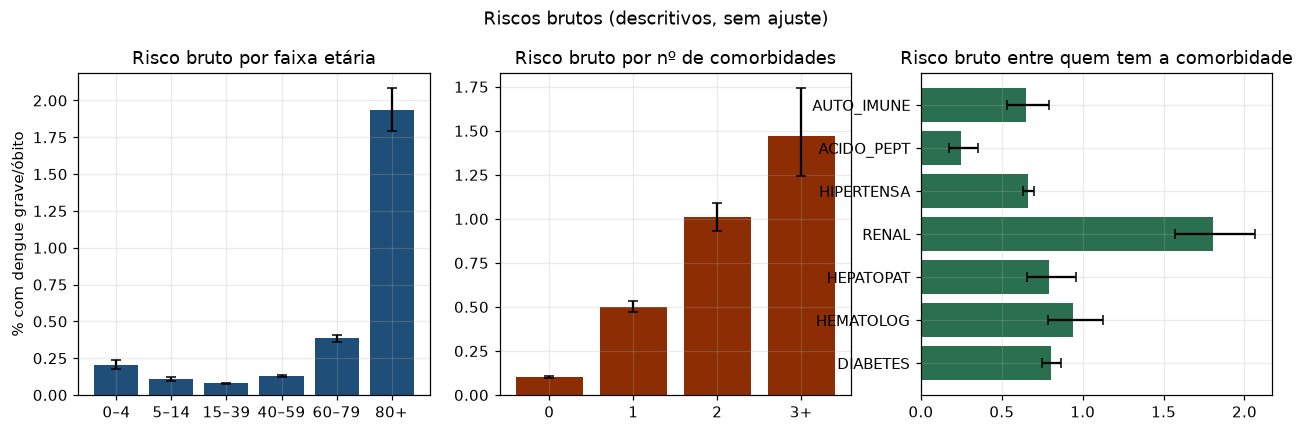

In [20]:
t1 = tabela_caracteristicas(pop, x)
print("Tabela 1 — características por desfecho (n e % da coluna):")
display(t1)
salvar_tabela(t1, "tabela1_caracteristicas")

rb = riscos_brutos(pop, x)
for nome, t in rb.items():
    salvar_tabela(t, f"risco_bruto_{nome}")

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
t = rb["por_faixa_etaria"].dropna(subset=["risco_%"])
eixos[0].bar(t["categoria"], t["risco_%"], yerr=[t["risco_%"] - t["ic95_inf_%"], t["ic95_sup_%"] - t["risco_%"]],
             color="#1f4e79", capsize=3)
eixos[0].set_title("Risco bruto por faixa etária"); eixos[0].set_ylabel("% com dengue grave/óbito")
t = rb["por_n_comorbidades"].dropna(subset=["risco_%"])
eixos[1].bar(t["categoria"], t["risco_%"], yerr=[t["risco_%"] - t["ic95_inf_%"], t["ic95_sup_%"] - t["risco_%"]],
             color="#8c2d04", capsize=3)
eixos[1].set_title("Risco bruto por nº de comorbidades")
t = rb["por_comorbidade"]; t = t[t["categoria"] == "Sim"].dropna(subset=["risco_%"])
eixos[2].barh(t["comorbidade"], t["risco_%"], xerr=[t["risco_%"] - t["ic95_inf_%"], t["ic95_sup_%"] - t["risco_%"]],
              color="#2a6f4f", capsize=3)
eixos[2].set_title("Risco bruto entre quem tem a comorbidade")
fig.suptitle("Riscos brutos (descritivos, sem ajuste)", y=1.03)
salvar_figura(fig, "riscos_brutos")

## 9. Análise de associações epidemiológicas

**Modelo explicativo E1** (objetivo principal): regressão logística **sem penalização** (para ter IC),
ajustada por idade (spline cúbico, 5 nós nos quantis da população), sexo e gestação. É uma análise de
**casos completos** (sexo M/F e nenhuma comorbidade "Ausente"), para evitar níveis esparsos; B1/M1
usam todas as linhas. O ajuste é feito sobre padrões de covariáveis agrupados (binomial agrupado),
equivalente ao ajuste linha a linha.

Nesta seção, por comorbidade: **OR bruto** (Woolf), **OR ajustado por idade, sexo e gestação** (uma
comorbidade por vez) e **OR mutuamente ajustado** (as 7 juntas, sem interações). Com milhões de linhas
quase tudo é "significativo": **interprete o tamanho do efeito e o IC, não o p-valor**. Todas as razões de
chances são **associações**, sujeitas a confundimento residual (ex.: hipertensão correlaciona com idade e
doença renal) e a viés de notificação; **não são efeitos causais**.

Casos completos para o E1: {'linhas_excluidas': 2582, 'eventos_excluidos': 6, 'linhas_analisadas': 2450626, 'eventos_analisados': 3979}
Nós do spline de idade (anos): (6.0, 20.0, 33.0, 49.0, 70.0) | idade de referência (mediana dos eventos): 55.0


,comorbidade,casos_expostos,eventos_expostos,OR_bruto,bruto_ic95_inf,bruto_ic95_sup,OR_aj_idade_sexo,aj_idade_sexo_ic95_inf,aj_idade_sexo_ic95_sup,OR_aj_mutuo,aj_mutuo_ic95_inf,aj_mutuo_ic95_sup
0,DIABETES,88772,715,5.87,5.41,6.36,3.01,2.76,3.28,1.74,1.58,1.92
1,HEMATOLOG,12610,119,6.01,5.00,7.22,4.96,4.12,5.98,2.59,2.07,3.25
2,HEPATOPAT,13085,104,5.03,4.14,6.12,4.11,3.38,5.01,1.75,1.37,2.24
3,RENAL,11189,202,11.86,10.28,13.68,7.11,6.14,8.23,4.31,3.65,5.08
4,HIPERTENSA,213241,1416,5.83,5.46,6.22,3.10,2.87,3.34,2.41,2.22,2.62
5,ACIDO_PEPT,12854,32,1.54,1.09,2.18,1.39,0.98,1.97,0.09,0.06,0.15
6,AUTO_IMUNE,14874,97,4.11,3.36,5.03,3.42,2.79,4.20,1.57,1.23,2.01


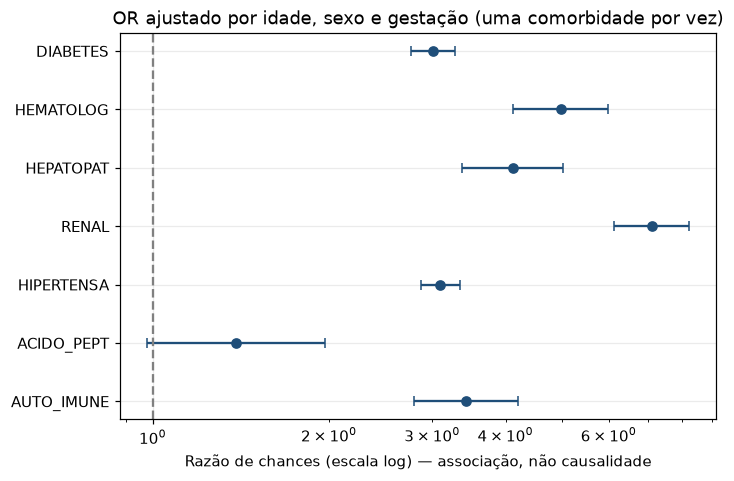

In [21]:
agg, exclusao_e1 = agregar_e1(pop, x)
nos = nos_da_idade(x["idade_anos"])
IDADE_REF = CONFIG["IDADE_REF"] or float(pop.loc[pop["y"] == 1, "idade_anos"].median())
print("Casos completos para o E1:", exclusao_e1)
print("Nós do spline de idade (anos):", nos, "| idade de referência (mediana dos eventos):", IDADE_REF)

tor = tabela_or_comorbidades(agg, nos)
colunas = ["comorbidade", "casos_expostos", "eventos_expostos", "OR_bruto", "bruto_ic95_inf", "bruto_ic95_sup",
           "OR_aj_idade_sexo", "aj_idade_sexo_ic95_inf", "aj_idade_sexo_ic95_sup",
           "OR_aj_mutuo", "aj_mutuo_ic95_inf", "aj_mutuo_ic95_sup"]
display(tor[colunas].round(2))
salvar_tabela(tor[colunas], "or_comorbidades")
grafico_floresta(tor, "comorbidade", "OR_aj_idade_sexo", "aj_idade_sexo_ic95_inf", "aj_idade_sexo_ic95_sup",
                 "OR ajustado por idade, sexo e gestação (uma comorbidade por vez)", "or_ajustado_idade_sexo")
RESULTADOS["e1_casos_completos"] = exclusao_e1

## 10. Análise de combinações de comorbidades

E1 completo: efeitos principais + **interações 2 a 2** entre comorbidades + interação
comorbidade × idade (spline) para **hipertensão e diabetes** `[ASSUMPTION]`. Só entram os pares com
**≥ 10 eventos** na célula combinada. Para cada par:

- **OR da interação** (escala multiplicativa) e seu p-valor, com correção de **Benjamini-Hochberg** (FDR 5%);
- **RERI** e **AP** (escala aditiva), com IC 95% pelo método delta, na idade de referência. RERI > 0 indica
  que a combinação acrescenta risco **além da soma** dos efeitos; o OR aproxima o RR (desfecho raro).

A **tabela de perfis** dá o risco absoluto estimado (padronizado pela população de cada faixa etária)
por perfil exato de comorbidades. Combinações de 3+ vêm da **soma dos efeitos** (sem interações de 3ª ordem).
Células com < 10 eventos não saem.

15 de 21 pares têm ≥ 10 eventos e entram no E1.


,A,B,casos,eventos,entra_no_E1
0,DIABETES,HEMATOLOG,3912,22,True
1,DIABETES,HEPATOPAT,4698,33,True
2,DIABETES,RENAL,4256,89,True
3,DIABETES,HIPERTENSA,55447,570,True
4,DIABETES,ACIDO_PEPT,3375,7,False
5,DIABETES,AUTO_IMUNE,4040,16,True
6,HEMATOLOG,HEPATOPAT,3474,10,True
7,HEMATOLOG,RENAL,3301,11,True
8,HEMATOLOG,HIPERTENSA,4568,35,True
9,HEMATOLOG,ACIDO_PEPT,3302,4,False


Razão de verossimilhança — bloco de interações entre pares: {'LR': 362.3063, 'gl': 15, 'p_valor': 0.0}
Razão de verossimilhança — bloco comorbidade × idade: {'LR': 41.6901, 'gl': 16, 'p_valor': 0.0004}


,A,B,eventos_celula,OR_interacao,ic95_inf,ic95_sup,p_valor,p_BH,RERI,RERI_ic95_inf,RERI_ic95_sup,AP,AP_ic95_inf,AP_ic95_sup
0,DIABETES,HEMATOLOG,22,0.479,0.290,0.790,0.004,0.007,2.291,-4.542,9.123,0.168,-0.250,0.586
1,DIABETES,HEPATOPAT,33,0.626,0.396,0.989,0.045,0.075,2.485,-1.888,6.857,0.261,-0.073,0.596
2,DIABETES,RENAL,89,0.936,0.681,1.287,0.683,0.772,10.472,3.480,17.463,0.544,0.393,0.695
3,DIABETES,HIPERTENSA,570,0.690,0.556,0.857,0.001,0.002,0.793,-0.093,1.679,0.146,0.002,0.290
4,DIABETES,AUTO_IMUNE,16,0.358,0.195,0.654,0.001,0.002,-1.582,-4.928,1.764,-0.287,-1.072,0.498
5,HEMATOLOG,HEPATOPAT,10,0.180,0.089,0.363,0.000,0.000,-4.952,-10.641,0.736,-0.597,-1.671,0.477
6,HEMATOLOG,RENAL,11,0.126,0.061,0.262,0.000,0.000,-7.152,-12.897,-1.407,-0.911,-2.270,0.448
7,HEMATOLOG,HIPERTENSA,35,0.392,0.257,0.598,0.000,0.000,-1.532,-5.568,2.505,-0.164,-0.655,0.327
8,HEMATOLOG,AUTO_IMUNE,14,0.659,0.345,1.259,0.207,0.311,17.470,-1.152,36.092,0.567,0.305,0.830
9,HEPATOPAT,RENAL,14,0.400,0.214,0.746,0.004,0.007,2.625,-5.621,10.870,0.198,-0.295,0.690


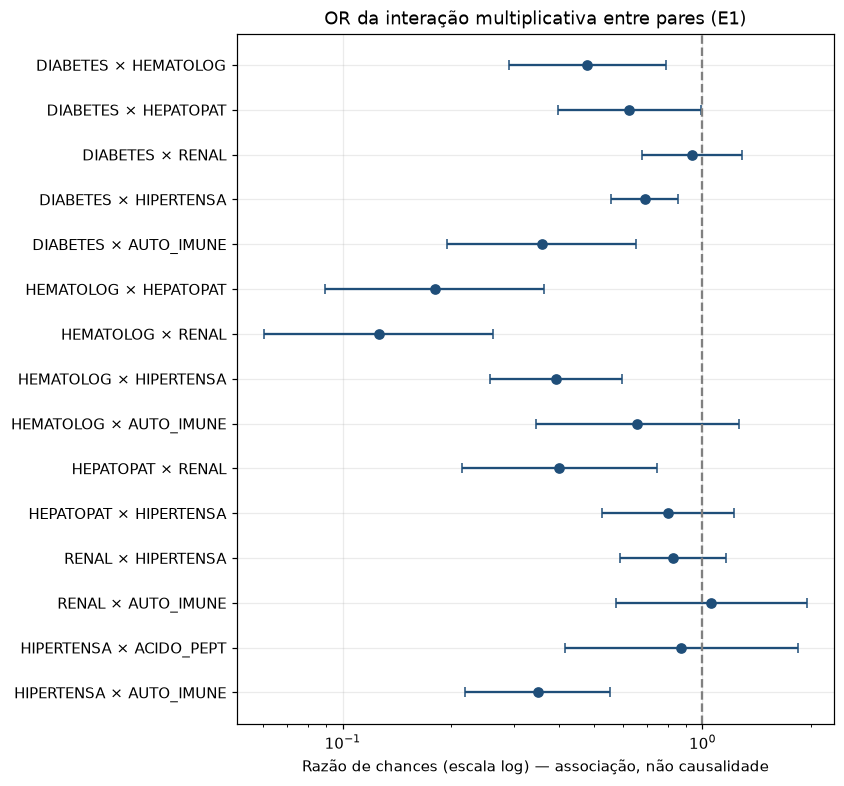

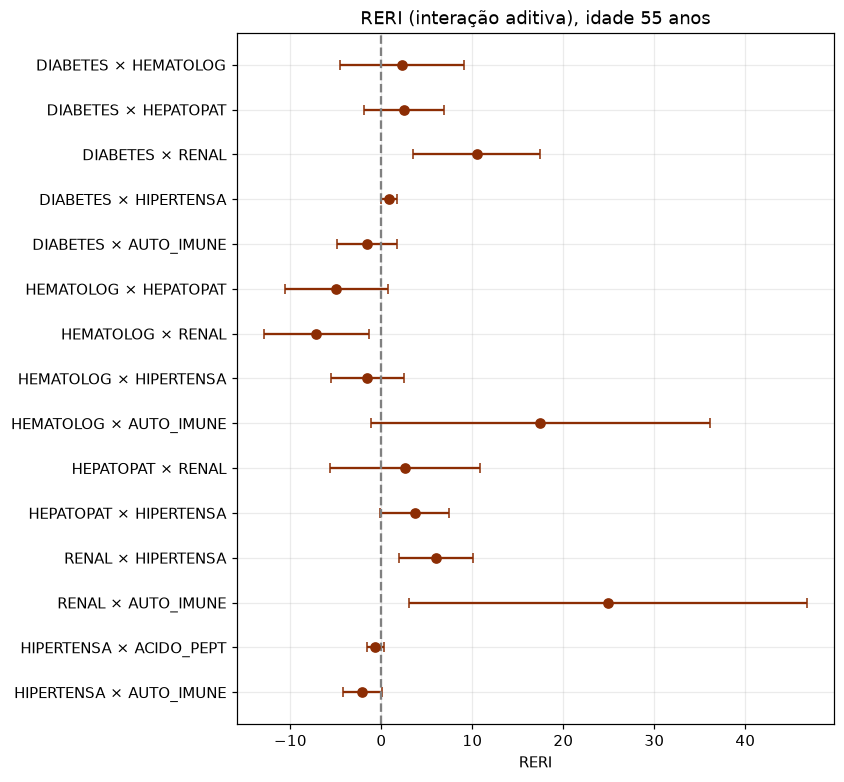

In [22]:
tabela_pares = pares_com_eventos(agg)
pares_e1 = [(r.A, r.B) for r in tabela_pares.itertuples() if r.entra_no_E1]
print(f"{len(pares_e1)} de {len(tabela_pares)} pares têm ≥ {MIN_EVENTOS_CELULA} eventos e entram no E1.")
display(tabela_pares)
salvar_tabela(tabela_pares, "pares_eventos")

m_e1 = ajustar_e1(agg, nos, pares_e1)
m_sem_pares = ajustar_e1(agg, nos, [], interacao_idade=INTERACAO_IDADE)
m_sem_idade = ajustar_e1(agg, nos, pares_e1, interacao_idade=())
lrt_pares = teste_razao_verossimilhanca(m_e1, m_sem_pares)
lrt_idade = teste_razao_verossimilhanca(m_e1, m_sem_idade)
print("Razão de verossimilhança — bloco de interações entre pares:", {k: round(v, 4) for k, v in lrt_pares.items()})
print("Razão de verossimilhança — bloco comorbidade × idade:", {k: round(v, 4) for k, v in lrt_idade.items()})

ti = tabela_interacoes(m_e1, agg, IDADE_REF)
cols_i = ["A", "B", "eventos_celula", "OR_interacao", "ic95_inf", "ic95_sup", "p_valor", "p_BH",
          "RERI", "RERI_ic95_inf", "RERI_ic95_sup", "AP", "AP_ic95_inf", "AP_ic95_sup"]
display(ti[cols_i].round(3))
salvar_tabela(ti[cols_i], "interacoes_pares_reri_ap")
if len(ti):
    ti["par"] = ti["A"] + " × " + ti["B"]
    grafico_floresta(ti, "par", "OR_interacao", "ic95_inf", "ic95_sup",
                     "OR da interação multiplicativa entre pares (E1)", "or_interacao_pares")
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(ti) + 1.4))
    yy = np.arange(len(ti))[::-1]
    ax.errorbar(ti["RERI"], yy, xerr=[ti["RERI"] - ti["RERI_ic95_inf"], ti["RERI_ic95_sup"] - ti["RERI"]],
                fmt="o", color="#8c2d04", capsize=3)
    ax.axvline(0, color="grey", ls="--"); ax.set_yticks(yy, ti["par"])
    ax.set_title(f"RERI (interação aditiva), idade {IDADE_REF:.0f} anos"); ax.set_xlabel("RERI")
    salvar_figura(fig, "reri_pares")
RESULTADOS["e1_lrt"] = {"pares": lrt_pares, "idade": lrt_idade}

Tabela de perfis (risco em %; padronizado por faixa etária; E1):


,perfil,faixa_etaria,casos_observados,eventos_observados,risco_estimado,ic95_inf,ic95_sup,razao_vs_sem_comorbidade,razao_ic95_inf,razao_ic95_sup
0,Sem comorbidades,0–4,81798,166,0.20,0.17,0.23,1.00,1.00,1.00
1,Sem comorbidades,5–14,312981,318,0.10,0.09,0.11,1.00,1.00,1.00
2,Sem comorbidades,15–39,1037101,711,0.07,0.07,0.08,1.00,1.00,1.00
3,DIABETES,15–39,6315,12,0.16,0.11,0.25,2.32,1.51,3.56
4,HEMATOLOG,15–39,2465,32,0.66,0.51,0.85,9.24,7.22,11.82
5,HEPATOPAT,15–39,2220,10,0.35,0.26,0.48,4.94,3.62,6.74
6,HIPERTENSA,15–39,19515,29,0.16,0.12,0.22,2.22,1.60,3.09
7,AUTO_IMUNE,15–39,3245,17,0.36,0.27,0.48,5.01,3.77,6.65
8,DIABETES + HIPERTENSA,15–39,2263,13,0.27,0.18,0.43,3.85,2.45,6.05
9,Sem comorbidades,40–59,536095,458,0.09,0.08,0.10,1.00,1.00,1.00


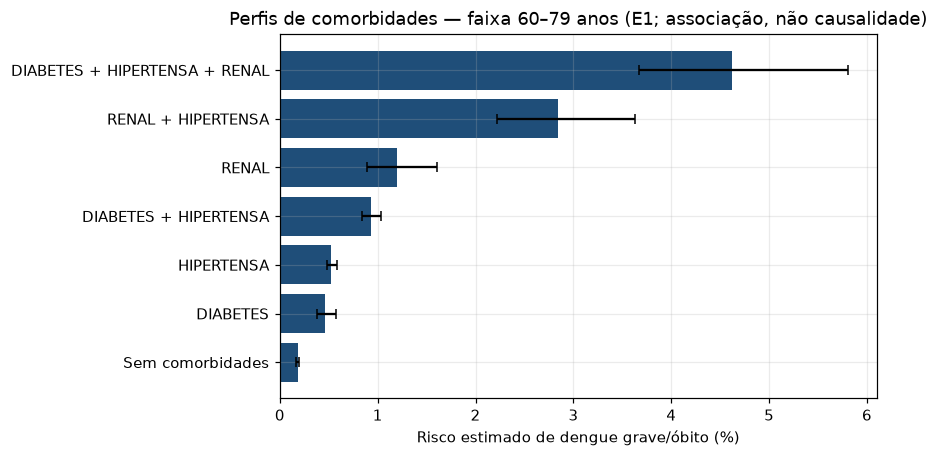

In [23]:
perfis = tabela_perfis(m_e1, agg)
pct = ["risco_estimado", "ic95_inf", "ic95_sup"]
vis = perfis.copy()
vis[pct] = (100 * vis[pct]).round(3)
print("Tabela de perfis (risco em %; padronizado por faixa etária; E1):")
display(vis.round(2))
salvar_tabela(perfis, "tabela_de_perfis")

faixa_graf = "60–79" if (perfis["faixa_etaria"] == "60–79").any() else perfis["faixa_etaria"].iloc[0]
g = perfis[perfis["faixa_etaria"] == faixa_graf].sort_values("risco_estimado")
fig, ax = plt.subplots(figsize=(7, 0.4 * len(g) + 1.5))
ax.barh(g["perfil"], 100 * g["risco_estimado"],
        xerr=[100 * (g["risco_estimado"] - g["ic95_inf"]), 100 * (g["ic95_sup"] - g["risco_estimado"])],
        color="#1f4e79", capsize=3)
ax.set_xlabel("Risco estimado de dengue grave/óbito (%)")
ax.set_title(f"Perfis de comorbidades — faixa {faixa_graf} anos (E1; associação, não causalidade)")
salvar_figura(fig, "perfis_risco")

## 11. Ajustes por idade e sexo, ranking e análise de sensibilidade

- **Heterogeneidade por idade:** como hipertensão e diabetes interagem com a idade, o "efeito" depende
  da idade. Mostramos o OR de cada comorbidade (demais ausentes) em idades de referência.
- **Ranking (FR-19):** pelo **OR do E1** na idade de referência (e **só** dele, R10: nunca por SHAP ou
  importância de árvore). Comorbidades com IC 95% sobrepostos ficam como **"sem ordem definida"**.
- **Sensibilidade (D-47):** reajusta o E1 removendo duplicatas por uma chave **mais estrita** (+ unidade
  notificadora + data de notificação) para ver se os OR mudam.

idade,5,20,40,60,80
comorbidade,,,,,
ACIDO_PEPT,0.70,0.70,0.70,0.70,0.70
AUTO_IMUNE,5.02,5.02,5.02,5.02,5.02
DIABETES,2.42,1.69,3.01,2.92,2.24
HEMATOLOG,9.30,9.30,9.30,9.30,9.30
HEPATOPAT,4.95,4.95,4.95,4.95,4.95
HIPERTENSA,1.06,1.58,2.84,2.67,3.02
RENAL,6.71,6.71,6.71,6.71,6.71


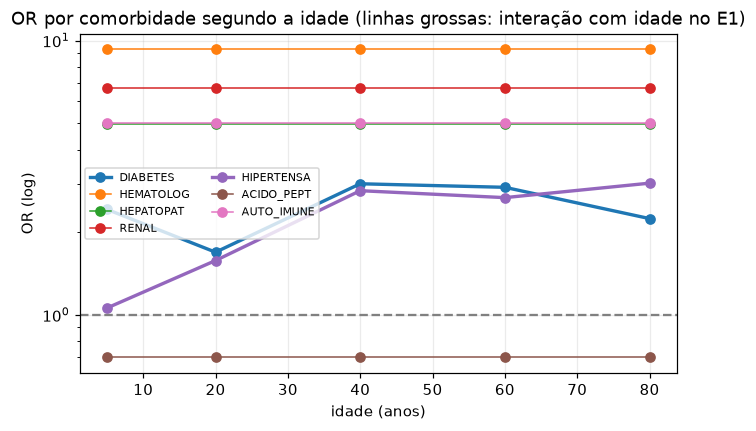

Ranking de comorbidades pelo OR do E1 na idade de referência (55 anos):


,posicao,comorbidade,OR,ic95_inf,ic95_sup,sem_ordem_definida_com
0,1,HEMATOLOG,9.30,7.25,11.91,RENAL
1,2,RENAL,6.71,5.00,9.00,"HEMATOLOG, AUTO_IMUNE, HEPATOPAT"
2,3,AUTO_IMUNE,5.02,3.78,6.68,"RENAL, HEPATOPAT, DIABETES"
3,4,HEPATOPAT,4.95,3.63,6.76,"RENAL, AUTO_IMUNE, DIABETES"
4,5,DIABETES,3.07,2.40,3.91,"AUTO_IMUNE, HEPATOPAT, HIPERTENSA"
5,6,HIPERTENSA,2.56,2.16,3.04,DIABETES
6,7,ACIDO_PEPT,0.70,0.42,1.17,


In [24]:
idades = [5, 20, 40, 60, 80]
linhas = []
for c in COMORBIDADES:
    for ida in idades:
        r = or_com_ic(m_e1, {c}, ida)
        linhas.append({"comorbidade": c, "idade": ida, "OR": r["OR"], "ic95_inf": r["ic95_inf"],
                       "ic95_sup": r["ic95_sup"]})
or_idade = pd.DataFrame(linhas)
display(or_idade.pivot(index="comorbidade", columns="idade", values="OR").round(2))
salvar_tabela(or_idade, "or_por_idade_e1")

fig, ax = plt.subplots(figsize=(7, 4))
for c in COMORBIDADES:
    d = or_idade[or_idade["comorbidade"] == c]
    ax.plot(d["idade"], d["OR"], marker="o", label=c, lw=2.2 if c in INTERACAO_IDADE else 1)
ax.axhline(1, color="grey", ls="--"); ax.set_yscale("log"); ax.legend(fontsize=7, ncol=2)
ax.set_xlabel("idade (anos)"); ax.set_ylabel("OR (log)")
ax.set_title("OR por comorbidade segundo a idade (linhas grossas: interação com idade no E1)")
salvar_figura(fig, "or_por_idade")

rank = ranking_comorbidades(m_e1, IDADE_REF)
print(f"Ranking de comorbidades pelo OR do E1 na idade de referência ({IDADE_REF:.0f} anos):")
display(rank.drop(columns=["log_or", "se"]).round(2))
salvar_tabela(rank.drop(columns=["log_or", "se"]), "ranking_comorbidades")
RESULTADOS["ranking_comorbidades"] = rank[["posicao", "comorbidade", "OR"]].round(3).to_dict("records")

In [25]:
def chave_estrita(df):
    partes = [code(df[c]).fillna("<b>") for c in
              ("ID_UNIDADE", "DT_NOTIFIC", "DT_SIN_PRI", "ID_MN_RESI", "CS_SEXO", "ANO_NASC", "NU_IDADE_N")
              if c in df.columns]
    chave = partes[0]
    for p in partes[1:]:
        chave = chave + "|" + p
    return chave


if CONFIG["SENSIBILIDADE_DUPLICATAS"] and "ID_UNIDADE" in pop.columns:
    manter = ~chave_estrita(pop).duplicated().to_numpy()
    pop_s, x_s = pop[manter].reset_index(drop=True), x[manter].reset_index(drop=True)
    agg_s, _ = agregar_e1(pop_s, x_s)
    tp_s = pares_com_eventos(agg_s)
    pares_s = [(r.A, r.B) for r in tp_s.itertuples() if r.entra_no_E1]
    m_s = ajustar_e1(agg_s, nos_da_idade(x_s["idade_anos"]), pares_s)
    base = {c: or_com_ic(m_e1, {c}, IDADE_REF) for c in COMORBIDADES}
    sens = {c: or_com_ic(m_s, {c}, IDADE_REF) for c in COMORBIDADES}
    sens_t = pd.DataFrame({"comorbidade": COMORBIDADES,
                           "OR (análise principal)": [base[c]["OR"] for c in COMORBIDADES],
                           "OR (sem duplicatas da chave estrita)": [sens[c]["OR"] for c in COMORBIDADES]})
    sens_t["variação relativa (%)"] = 100 * (sens_t.iloc[:, 2] / sens_t.iloc[:, 1] - 1)
    print(f"Chave estrita: {int((~manter).sum()):,} linhas removidas de {len(pop):,} "
          f"({100 * (~manter).mean():.1f}%), {int(pop.loc[~manter, 'y'].sum())} eventos.")
    display(sens_t.round(2))
    salvar_tabela(sens_t, "sensibilidade_duplicatas")
    del pop_s, x_s, agg_s, m_s
    gc.collect()
else:
    print("Análise de sensibilidade de duplicatas não executada (desligada ou sem ID_UNIDADE).")

Chave estrita: 22,541 linhas removidas de 2,453,208 (0.9%), 9 eventos.


,comorbidade,OR (análise principal),OR (sem duplicatas da chave estrita),variação relativa (%)
0,DIABETES,3.07,3.09,0.70
1,HEMATOLOG,9.30,9.34,0.44
2,HEPATOPAT,4.95,4.93,-0.51
3,RENAL,6.71,6.72,0.21
4,HIPERTENSA,2.56,2.56,-0.07
5,ACIDO_PEPT,0.70,0.70,0.19
6,AUTO_IMUNE,5.02,5.04,0.28


## 12. Preparação dos dados para ML

- **Unidade:** uma notificação confirmada. **Alvo:** `y` (grave ou óbito). **Features:** `X` da seção 7.
- **Prevalência natural, sem correção de desbalanceamento** (R3/D-38). Não há `class_weight`,
  `scale_pos_weight`, SMOTE nem subamostragem: corrigir o desbalanceamento não melhora AUROC/AUPRC e
  **piora a calibração** (van den Goorbergh et al., JAMIA 2022). O recall é controlado pelo **limiar**
  (F2, que pesa mais o recall, coerente com o custo maior do falso negativo — D-14/D-33) e as
  probabilidades são **calibradas depois**, em predições fora da dobra.
- **Sem vazamento:** `X` só tem a lista fechada; ano/região/unidade ficam fora; pré-processamento com
  estado dentro de `Pipeline`; early stopping só na validação interna (10% das regiões de **treino**).

In [26]:
PROIBIDOS_R3 = ("class_weight", "scale_pos_weight", "is_unbalance", "auto_class_weights", "pos_weight",
                "sample_weight")
for nome_m, grade in GRADES.items():
    for p in grade:
        assert not any(k in PROIBIDOS_R3 for k in p), f"R3: correção de desbalanceamento em {nome_m}: {p}"
assert_dev_only(pop[["ANO"]])
assert_features_permitidas(list(x.columns), FEATURES_M1)
ok_oof = ~regiao.isna().to_numpy()  # linhas com região (as demais ficam só no treino)
b2_dev = b2_flag(x)
print(f"X: {x.shape[0]:,} linhas × {x.shape[1]} features | eventos: {int(y.sum()):,} "
      f"({100 * y.mean():.3f}%) | B2 sinaliza {100 * b2_dev.mean():.1f}% da população de desenvolvimento")

X: 2,453,208 linhas × 26 features | eventos: 3,985 (0.162%) | B2 sinaliza 26.3% da população de desenvolvimento


## 13. Separação e validação dos conjuntos

| Etapa | Dados | Uso |
|---|---|---|
| Desenvolvimento | 2022–2023, todas as regiões | **Leave-one-region-out** (5 dobras): treina em 4 regiões, prediz a 5ª |
| Tuning | predições fora da dobra | hiperparâmetros pela **PR-AUC média** das 5 dobras |
| Calibração e limiar | predições fora da dobra, agrupadas | calibrador (isotônica/Platt) e limiar (máx. F2) |
| Early stopping | 10% estratificado das regiões **de treino** | nunca a região deixada de fora (R6) |
| Modelo final | 2022–2023 completo | retreino; nº de árvores = mediana dos melhores pontos (D-37) |
| **Teste congelado** | **2024** | avaliado **uma única vez**, depois do congelamento; lacre em disco (R2) |

Por que região: mede a robustez geográfica (diferenças de notificação e de sistema) e é a validação
"interna-externa"; 2024 acrescenta a validação **temporal** (outro ano epidêmico, possível mudança de
sorotipo/distribuição). A comparação é pareada: todos os modelos preveem **as mesmas linhas** nas **mesmas dobras**.

In [27]:
dobras = dobras_loro(regiao)
tab_dobras = pd.DataFrame([{"região deixada de fora": r, "casos de treino": len(tr), "casos fora da dobra": len(te),
                            "eventos fora da dobra": int(y[te].sum()),
                            "< 100 eventos": "⚠️" if y[te].sum() < CONFIG["MIN_EVENTOS_SUBGRUPO"] else ""}
                           for r, tr, te in dobras])
display(tab_dobras)
salvar_tabela(tab_dobras, "dobras_loro")
if (tab_dobras["eventos fora da dobra"] < CONFIG["MIN_EVENTOS_SUBGRUPO"]).any():
    print("⚠️ Dobra com < 100 eventos: a calibração dessa região terá IC largo (§3.8).")

,região deixada de fora,casos de treino,casos fora da dobra,eventos fora da dobra,< 100 eventos
0,Sudeste,1290756,1162452,1736,
1,Sul,1871933,581275,810,
2,Centro-Oeste,2044494,408714,736,
3,Nordeste,2225156,228052,582,
4,Norte,2380493,72715,121,


## 14. Treinamento e otimização dos modelos

**Baselines (obrigatórios, FR-04):** B0 (prevalência do treino), B1 (logística de efeitos principais) e B2
(regra do grupo B do protocolo do MS, avaliada nas seções 15, 17 e 18).

**Candidatos de M1** (mesmas linhas, dobras e semente — comparação justa):

1. **Logística elastic net** (L1+L2, `saga`): features de M1 + as 21 interações entre comorbidades.
   Só para predição; o E1 continua sem penalização para ter IC.
2. **Random Forest** (`max_samples` reduz custo e memória sem distorcer probabilidades).
3. **Gradient boosting:** XGBoost (`aucpr`, early stopping na validação interna) ou
   HistGradientBoosting se XGBoost não estiver instalado.

**Busca de hiperparâmetros:** grade **pequena e declarada** (célula de configuração; `[ASSUMPTION]`,
Q-08 pendente de aprovação), critério = PR-AUC média nas 5 dobras, com orçamento de tempo por modelo
(a 1ª configuração sempre roda) e **cache em disco** (retomável se o Colab cair). **Pendentes do spec:**
CatBoost, MLP (PyTorch) e TabFM, que dependem de pacotes/GPU ainda não aprovados (T-2.0).

In [28]:
t0 = time.time()
oof_B0 = oof_b0(y, regiao)
oof_B1 = oof_b1(x, y, regiao)
print(f"Baselines B0 e B1 nas 5 dobras: {time.time() - t0:.0f} s | PR-AUC fora da dobra: "
      f"B0 {pr_auc(y[ok_oof], oof_B0[ok_oof]):.4f} | B1 {pr_auc(y[ok_oof], oof_B1[ok_oof]):.4f}")

ASSIN = {"dados": ASSINATURA_DEV, "n": int(len(y)), "eventos": int(y.sum()), "seed": CONFIG["SEED"],
         "boosting": BOOSTING, "paciencia": CONFIG["PACIENCIA_BOOSTING"],
         "val": CONFIG["VALIDACAO_INTERNA_FRAC"], "max_iter": CONFIG["MAX_ITER_BOOSTING"]}
CANDIDATOS = ["elastic_net", "random_forest", "xgboost"]
busca = {}
for nome in CANDIDATOS:
    grade = [({**p, "max_iter": CONFIG["EN_MAX_ITER"]} if nome == "elastic_net" else p) for p in GRADES[nome]]
    busca[nome] = busca_hiperparametros(
        nome, grade, x, y, regiao, CONFIG["SEED"], CONFIG["ORCAMENTO_S"][nome],
        cache_dir=OUT_DIR / "cache", assinatura=ASSIN, paciencia=CONFIG["PACIENCIA_BOOSTING"],
        val_frac=CONFIG["VALIDACAO_INTERNA_FRAC"], max_iter=CONFIG["MAX_ITER_BOOSTING"],
        device=CONFIG["DEVICE"], n_jobs=CONFIG["N_JOBS"])
    b = busca[nome]
    print(f"\n{nome}: {b['configs_avaliadas']}/{b['configs_na_grade']} configurações em "
          f"{b['tempo_total_s']:.0f} s (orçamento {CONFIG['ORCAMENTO_S'][nome]} s)")
    display(b["tabela"].round(4))
    salvar_tabela(b["tabela"], f"busca_{nome}")

Baselines B0 e B1 nas 5 dobras: 50 s | PR-AUC fora da dobra: B0 0.0015 | B1 0.0106

elastic_net: 4/4 configurações em 0 s (orçamento 1800 s)


,config,p_C,p_l1_ratio,p_max_iter,pr_auc_media,tempo_s,do_cache
0,0,1.00,0.5,300,0.0265,713.0,True
1,1,0.10,0.5,300,0.0258,591.2,True
2,2,0.01,0.5,300,0.0195,266.1,True
3,3,0.10,0.1,300,0.0258,514.3,True



random_forest: 4/4 configurações em 0 s (orçamento 2400 s)


,config,p_n_estimators,p_min_samples_leaf,p_max_features,p_max_samples,pr_auc_media,tempo_s,do_cache
0,0,200,100,sqrt,0.25,0.0259,325.4,True
1,1,200,30,sqrt,0.25,0.0269,330.8,True
2,2,200,300,sqrt,0.25,0.0243,314.7,True
3,3,200,100,0.5,0.25,0.0243,529.2,True



xgboost: 4/4 configurações em 0 s (orçamento 1800 s)


,config,p_max_depth,p_learning_rate,p_min_child_weight,p_subsample,p_colsample_bytree,p_reg_lambda,pr_auc_media,tempo_s,do_cache
0,0,4,0.05,5,0.8,0.8,1.0,0.0269,129.7,True
1,1,3,0.05,5,0.8,0.8,1.0,0.0281,146.4,True
2,2,6,0.05,20,0.8,0.8,1.0,0.0278,128.9,True
3,3,4,0.05,50,0.8,0.8,10.0,0.0268,140.6,True


In [29]:
# Calibração (FR-08, FR-17): tipo escolhido pelo menor Brier com calibração CRUZADA POR REGIÃO,
# para as métricas de desenvolvimento não ficarem otimistas. O calibrador final usa todas as OOF.
oof_raw = {n: busca[n]["melhor"]["oof"] for n in CANDIDATOS}
cal_tipo, oof_cal = {}, {}
for n in CANDIDATOS:
    cal_tipo[n], tab_cal = escolher_calibrador(oof_raw[n], y, regiao)
    oof_cal[n] = calibrar_cruzado(oof_raw[n], y, regiao, cal_tipo[n])
    print(n, "→ calibrador:", cal_tipo[n], "|", tab_cal.round(6).to_dict("records"))

resumo = pd.DataFrame([{"modelo": n, "pr_auc_media": busca[n]["melhor"]["pr_auc_media"],
                        "brier": brier(y[ok_oof], oof_cal[n][ok_oof]), "calibrador": cal_tipo[n],
                        "config": busca[n]["melhor"]["params"]} for n in CANDIDATOS])
SELECIONADO, MOTIVO = selecionar_modelo(resumo)
print(f"\nModelo M1 selecionado: {SELECIONADO} — {MOTIVO} (regra de §3.11; sem olhar 2024)")
display(resumo.round(5))
salvar_tabela(resumo.assign(config=resumo["config"].astype(str)), "selecao_m1")
RESULTADOS["selecao_m1"] = {"modelo": SELECIONADO, "motivo": MOTIVO, "boosting": BOOSTING,
                            "params": busca[SELECIONADO]["melhor"]["params"],
                            "calibrador": cal_tipo[SELECIONADO]}

elastic_net → calibrador: isotonica | [{'calibrador': 'nenhum', 'brier_cruzado': 0.001605}, {'calibrador': 'platt', 'brier_cruzado': 0.001604}, {'calibrador': 'isotonica', 'brier_cruzado': 0.001602}]
random_forest → calibrador: isotonica | [{'calibrador': 'nenhum', 'brier_cruzado': 0.001601}, {'calibrador': 'platt', 'brier_cruzado': 0.001601}, {'calibrador': 'isotonica', 'brier_cruzado': 0.0016}]
xgboost → calibrador: isotonica | [{'calibrador': 'nenhum', 'brier_cruzado': 0.0016}, {'calibrador': 'platt', 'brier_cruzado': 0.001599}, {'calibrador': 'isotonica', 'brier_cruzado': 0.001598}]

Modelo M1 selecionado: xgboost — empate de PR-AUC (< 0,005): desempatou o menor Brier (regra de §3.11; sem olhar 2024)


,modelo,pr_auc_media,brier,calibrador,config
0,elastic_net,0.02649,0.0016,isotonica,"{'C': 1.0, 'l1_ratio': 0.5, 'max_iter': 300}"
1,random_forest,0.02690,0.0016,isotonica,"{'n_estimators': 200, 'min_samples_leaf': 30, ..."
2,xgboost,0.02811,0.0016,isotonica,"{'max_depth': 3, 'learning_rate': 0.05, 'min_c..."


## 15. Avaliação e calibração (desenvolvimento, predições fora da dobra)

Métricas **pooled** sobre as predições fora da dobra (cada paciente é previsto por um modelo que **não viu
a região dele**). As probabilidades dos candidatos usam calibração **cruzada por região**; o B1 é a
logística simples sem recalibração. Calibração: *slope* ideal = 1, intercepto (CITL) ideal = 0, O:E ideal = 1.
Estas são métricas de **desenvolvimento** (ligeiramente otimistas, pois tuning e calibração compartilham as
mesmas predições); o número que vale é o do teste de 2024.

In [30]:
def linha_metricas(nome, p, tem_cal=True):
    ok = ok_oof
    d = {"modelo": nome, "PR-AUC (pooled)": pr_auc(y[ok], p[ok]), "ROC-AUC": roc_auc(y[ok], p[ok]),
         "Brier": brier(y[ok], p[ok])}
    if tem_cal:
        c = calibracao_resumo(y[ok], p[ok])
        d.update({"slope": c["slope"], "intercepto (CITL)": c["intercepto_citl"], "O:E": c["O:E"]})
    return d


linhas = [linha_metricas("B0 (prevalência)", oof_B0, tem_cal=False), linha_metricas("B1 (logística simples)", oof_B1)]
linhas += [linha_metricas(f"{n} (calibrado)", oof_cal[n]) for n in CANDIDATOS]
for l, n in zip(linhas[2:], CANDIDATOS):
    l["PR-AUC (média das dobras)"] = busca[n]["melhor"]["pr_auc_media"]
met_dev = pd.DataFrame(linhas)
display(met_dev.round(4))
salvar_tabela(met_dev, "metricas_dev_oof")

# Limiar e comparação com a regra do MS nos MESMOS pacientes (dev, fora da dobra)
sel_raw = oof_raw[SELECIONADO]
cal_final = Calibrador(cal_tipo[SELECIONADO]).ajustar(sel_raw[ok_oof], y[ok_oof])
p_dev = cal_final.prever(np.where(np.isnan(sel_raw), 0.0, sel_raw))   # calibrador final (o do teste)
p_dev_cv = oof_cal[SELECIONADO]                                       # calibração cruzada (honesta)
LIM_F2, _ = melhor_limiar_f2(y[ok_oof], p_dev[ok_oof])
LIM_B1, _ = melhor_limiar_f2(y[ok_oof], oof_B1[ok_oof])
met_b2 = metricas_limiar(y[ok_oof], b2_dev[ok_oof])
LIM_SENS = limiar_para_sensibilidade(y[ok_oof], p_dev[ok_oof], met_b2["sensibilidade"])
LIM_FRAC = limiar_para_fracao(y[ok_oof], p_dev[ok_oof], met_b2["pct_sinalizados"])
flags_dev = {"B0 (ninguém)": np.zeros(len(y), bool), "B2 — regra do MS": b2_dev,
             "B1 no limiar F2": oof_B1 >= LIM_B1, "M1 no limiar F2": p_dev >= LIM_F2,
             "M1 com a mesma sensibilidade de B2": p_dev >= LIM_SENS,
             "M1 sinalizando a mesma fração de B2": p_dev >= LIM_FRAC}
lim_dev = pd.DataFrame([{"classificador": k, **metricas_limiar(y[ok_oof], f[ok_oof])} for k, f in flags_dev.items()])
display(lim_dev.round(4))
salvar_tabela(lim_dev, "metricas_limiar_dev")
print(f"Limiares (calibrados, só dev): F2 de M1 = {LIM_F2:.5f} | F2 de B1 = {LIM_B1:.5f} | "
      f"sensibilidade de B2 → {LIM_SENS:.5f} | fração de B2 → {LIM_FRAC:.5f}")
RESULTADOS["dev"] = {"limiar_f2_m1": LIM_F2, "limiar_f2_b1": LIM_B1, "limiar_sens_b2": LIM_SENS,
                     "limiar_frac_b2": LIM_FRAC, "metricas_oof": met_dev.round(5).to_dict("records")}

,modelo,PR-AUC (pooled),ROC-AUC,Brier,slope,intercepto (CITL),O:E,PR-AUC (média das dobras)
0,B0 (prevalência),0.0015,0.4629,0.0016,NaN,NaN,NaN,NaN
1,B1 (logística simples),0.0106,0.7072,0.0016,0.9534,-0.0588,0.9433,NaN
2,elastic_net (calibrado),0.0238,0.8226,0.0016,0.9952,-0.0651,0.9379,0.0265
3,random_forest (calibrado),0.0246,0.8309,0.0016,0.9901,-0.0577,0.9448,0.0269
4,xgboost (calibrado),0.0272,0.8424,0.0016,1.0001,-0.0620,0.9408,0.0281


C:\Users\GABRIEL\AppData\Local\Temp\ipykernel_1988\3505686236.py:129: RuntimeWarning: invalid value encountered in divide
  f2 = np.where(tp > 0, 5 * vpp * sens / (4 * vpp + sens), 0.0)


,classificador,TP,FP,FN,TN,sensibilidade,especificidade,VPP,VPN,acuracia,F1,F2,pct_sinalizados
0,B0 (ninguém),0,0,3985,2449223,0.0000,1.0000,NaN,0.9984,0.9984,0.0000,0.0000,0.0000
1,B2 — regra do MS,2727,643071,1258,1806152,0.6843,0.7374,0.0042,0.9993,0.7374,0.0084,0.0206,0.2632
2,B1 no limiar F2,631,32316,3354,2416907,0.1583,0.9868,0.0192,0.9986,0.9855,0.0342,0.0645,0.0134
3,M1 no limiar F2,798,16804,3187,2432419,0.2003,0.9931,0.0453,0.9987,0.9919,0.0739,0.1190,0.0072
4,M1 com a mesma sensibilidade de B2,2770,369735,1215,2079488,0.6951,0.8490,0.0074,0.9994,0.8488,0.0147,0.0357,0.1518
5,M1 sinalizando a mesma fração de B2,3152,612230,833,1836993,0.7910,0.7500,0.0051,0.9995,0.7501,0.0102,0.0250,0.2508


Limiares (calibrados, só dev): F2 de M1 = 0.02583 | F2 de B1 = 0.01192 | sensibilidade de B2 → 0.00238 | fração de B2 → 0.00128


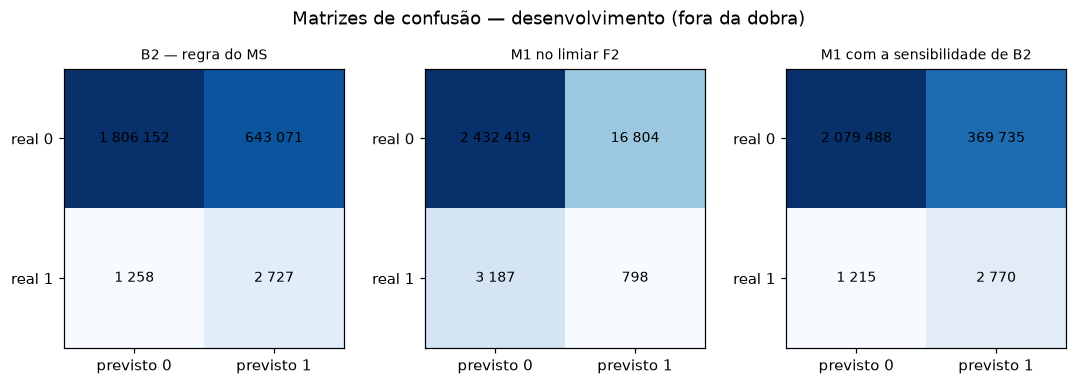

,região,casos,eventos,prevalência_%,PR-AUC M1,PR-AUC B1,ROC-AUC M1,slope M1
0,Sudeste,1162452,1736,0.1493,0.0281,0.0098,0.8602,1.1009
1,Sul,581275,810,0.1393,0.0299,0.0161,0.8542,1.0254
2,Centro-Oeste,408714,736,0.1801,0.0273,0.0152,0.8517,0.9513
3,Nordeste,228052,582,0.2552,0.0219,0.0078,0.8208,0.8174
4,Norte,72715,121,0.1664,0.0236,0.0113,0.8434,1.0031


,região,casos,eventos,prevalência_%,PR-AUC M1,PR-AUC B1,ROC-AUC M1,slope M1
0,Sudeste,1162452,1736,0.149339,0.028147,0.009814,0.860155,1.100863
1,Sul,581275,810,0.139349,0.029924,0.016053,0.854212,1.025431
2,Centro-Oeste,408714,736,0.180077,0.027327,0.015182,0.851747,0.951287
3,Nordeste,228052,582,0.255205,0.021932,0.007760,0.820846,0.817431
4,Norte,72715,121,0.166403,0.023624,0.011348,0.843421,1.003075


In [31]:
# Matrizes de confusão (dev) e por região (robustez geográfica)
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (nome, f) in zip(eixos, [("B2 — regra do MS", flags_dev["B2 — regra do MS"]),
                                 ("M1 no limiar F2", flags_dev["M1 no limiar F2"]),
                                 ("M1 com a sensibilidade de B2", flags_dev["M1 com a mesma sensibilidade de B2"])]):
    m = metricas_limiar(y[ok_oof], f[ok_oof])
    mat = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    ax.imshow(np.log10(mat + 1), cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mat[i, j]:,}".replace(",", " "), ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1], ["previsto 0", "previsto 1"]); ax.set_yticks([0, 1], ["real 0", "real 1"])
    ax.set_title(nome, fontsize=9); ax.grid(False)
fig.suptitle("Matrizes de confusão — desenvolvimento (fora da dobra)", y=1.04)
salvar_figura(fig, "matrizes_confusao_dev")

reg_linhas = []
for r, tr, te in dobras:
    ev = int(y[te].sum())
    d = {"região": r, "casos": len(te), "eventos": ev, "prevalência_%": 100 * y[te].mean(),
         "PR-AUC M1": pr_auc(y[te], p_dev_cv[te]), "PR-AUC B1": pr_auc(y[te], oof_B1[te]),
         "ROC-AUC M1": roc_auc(y[te], p_dev_cv[te])}
    if ev >= CONFIG["MIN_EVENTOS_SUBGRUPO"]:
        d["slope M1"] = calibracao_resumo(y[te], p_dev_cv[te])["slope"]
    else:
        d["aviso"] = "< 100 eventos: IC largo"
    reg_linhas.append(d)
por_regiao = pd.DataFrame(reg_linhas)
display(por_regiao.round(4))
salvar_tabela(por_regiao, "metricas_por_regiao_dev")

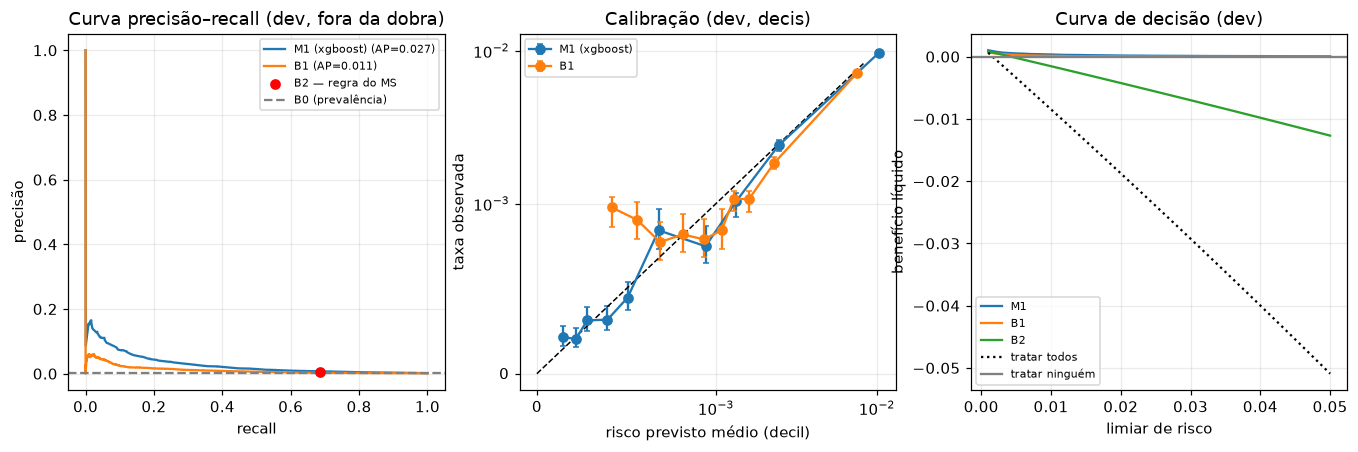

In [32]:
from sklearn.metrics import precision_recall_curve

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
for nome, p in [(f"M1 ({SELECIONADO})", p_dev_cv), ("B1", oof_B1)]:
    pr, rc, _ = precision_recall_curve(y[ok_oof], p[ok_oof])
    eixos[0].plot(rc, pr, label=f"{nome} (AP={pr_auc(y[ok_oof], p[ok_oof]):.3f})")
m2 = metricas_limiar(y[ok_oof], b2_dev[ok_oof])
eixos[0].scatter([m2["sensibilidade"]], [m2["VPP"]], color="red", zorder=5, label="B2 — regra do MS")
eixos[0].axhline(y[ok_oof].mean(), color="grey", ls="--", label="B0 (prevalência)")
eixos[0].set_xlabel("recall"); eixos[0].set_ylabel("precisão"); eixos[0].legend(fontsize=7)
eixos[0].set_title("Curva precisão–recall (dev, fora da dobra)")

for nome, p in [(f"M1 ({SELECIONADO})", p_dev_cv), ("B1", oof_B1)]:
    cc = curva_calibracao(y[ok_oof], p[ok_oof])
    eixos[1].errorbar(cc["p_medio"], cc["taxa_observada"],
                      yerr=[cc["taxa_observada"] - cc["ic95_inf"], cc["ic95_sup"] - cc["taxa_observada"]],
                      marker="o", capsize=2, label=nome)
lim = max(cc["p_medio"].max(), cc["taxa_observada"].max()) * 1.1
eixos[1].plot([0, lim], [0, lim], "k--", lw=1)
eixos[1].set_xscale("symlog", linthresh=1e-3); eixos[1].set_yscale("symlog", linthresh=1e-3)
eixos[1].set_xlabel("risco previsto médio (decil)"); eixos[1].set_ylabel("taxa observada")
eixos[1].set_title("Calibração (dev, decis)"); eixos[1].legend(fontsize=7)

lims = np.linspace(*CONFIG["DCA_LIMIARES"][:2], CONFIG["DCA_LIMIARES"][2])
dca_dev = {"M1": curva_decisao(y[ok_oof], p=p_dev_cv[ok_oof], limiares=lims),
           "B1": curva_decisao(y[ok_oof], p=oof_B1[ok_oof], limiares=lims),
           "B2": curva_decisao(y[ok_oof], flag=b2_dev[ok_oof], limiares=lims)}
for k, d in dca_dev.items():
    eixos[2].plot(d["limiar"], d["net_benefit"], label=k)
eixos[2].plot(lims, net_benefit_todos(y[ok_oof].mean(), lims), "k:", label="tratar todos")
eixos[2].axhline(0, color="grey", label="tratar ninguém")
eixos[2].set_xlabel("limiar de risco"); eixos[2].set_ylabel("benefício líquido")
eixos[2].set_title("Curva de decisão (dev)"); eixos[2].legend(fontsize=7)
salvar_figura(fig, "avaliacao_dev_pr_calibracao_dca")

## 16. Interpretabilidade e congelamento

**Três coisas diferentes (não confundir):**

| Conceito | Ferramenta | O que diz | O que **não** diz |
|---|---|---|---|
| **Associação estatística** | OR do E1 (seções 9–11) | quanto, em média e ajustado por idade/sexo, o risco difere entre quem tem e quem não tem a condição | que a condição *causa* o desfecho (confundimento residual, viés de notificação) |
| **Importância preditiva** | SHAP / permutação do M1 | quanto cada variável contribui **para a saída do modelo** | associação ajustada nem causa; com variáveis correlacionadas a atribuição é instável |
| **Causalidade** | — | **nada neste notebook a estima** | — |

SHAP explica o **modelo**, não o mundo. Abaixo: importância global (e interações) do melhor modelo de
**árvore**, numa subamostra estratificada **do desenvolvimento**, e a comparação com o ranking pelo OR
(que continua sendo a única fonte do ranking de comorbidades, R10).

Depois, o **congelamento**: retreino em todo o desenvolvimento, serialização com SHA-256 e metadados
(FR-12). **Daqui em diante nada é escolhido pelo teste (R1/R2).**

In [33]:
import joblib
from scipy.stats import spearmanr

dev_meta = pop[["ANO"]]
n_iter_mediano = int(np.median(busca[SELECIONADO]["melhor"]["melhor_iter"]))
kw_modelo = dict(paciencia=CONFIG["PACIENCIA_BOOSTING"], val_frac=CONFIG["VALIDACAO_INTERNA_FRAC"],
                 max_iter=CONFIG["MAX_ITER_BOOSTING"], device=CONFIG["DEVICE"], n_jobs=CONFIG["N_JOBS"])
t0 = time.time()
M1_FINAL = ajustar_final(SELECIONADO, busca[SELECIONADO]["melhor"]["params"], x, y, CONFIG["SEED"],
                         n_iter_mediano, x_meta=dev_meta, **kw_modelo)
B1_FINAL = ModeloB1().ajustar(x, y)
print(f"Retreino final de M1 ({SELECIONADO}) e B1 em todo o desenvolvimento: {time.time() - t0:.0f} s "
      f"| nº de árvores/épocas = mediana dos melhores pontos das dobras: {n_iter_mediano}")

# Melhor modelo de árvore para o SHAP (o selecionado, se for de árvore)
arvores = [n for n in ("xgboost", "random_forest") if n in busca]
nome_arvore = SELECIONADO if SELECIONADO in arvores else max(arvores, key=lambda n: busca[n]["melhor"]["pr_auc_media"])
if nome_arvore == SELECIONADO:
    M_ARVORE = M1_FINAL
else:
    M_ARVORE = ajustar_final(nome_arvore, busca[nome_arvore]["melhor"]["params"], x, y, CONFIG["SEED"],
                             int(np.median(busca[nome_arvore]["melhor"]["melhor_iter"])), x_meta=dev_meta,
                             **kw_modelo)
print("Modelo de árvore usado na interpretabilidade:", nome_arvore)


def amostra_estratificada(y_, n, seed):
    rng = np.random.default_rng(seed)
    idx = []
    for classe in (0, 1):
        pos = np.flatnonzero(y_ == classe)
        k = min(len(pos), max(1, int(round(n * len(pos) / len(y_)))))
        idx.append(rng.choice(pos, size=k, replace=False))
    return np.sort(np.concatenate(idx))

Retreino final de M1 (xgboost) e B1 em todo o desenvolvimento: 31 s | nº de árvores/épocas = mediana dos melhores pontos das dobras: 323
Modelo de árvore usado na interpretabilidade: xgboost


c:\Users\GABRIEL\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


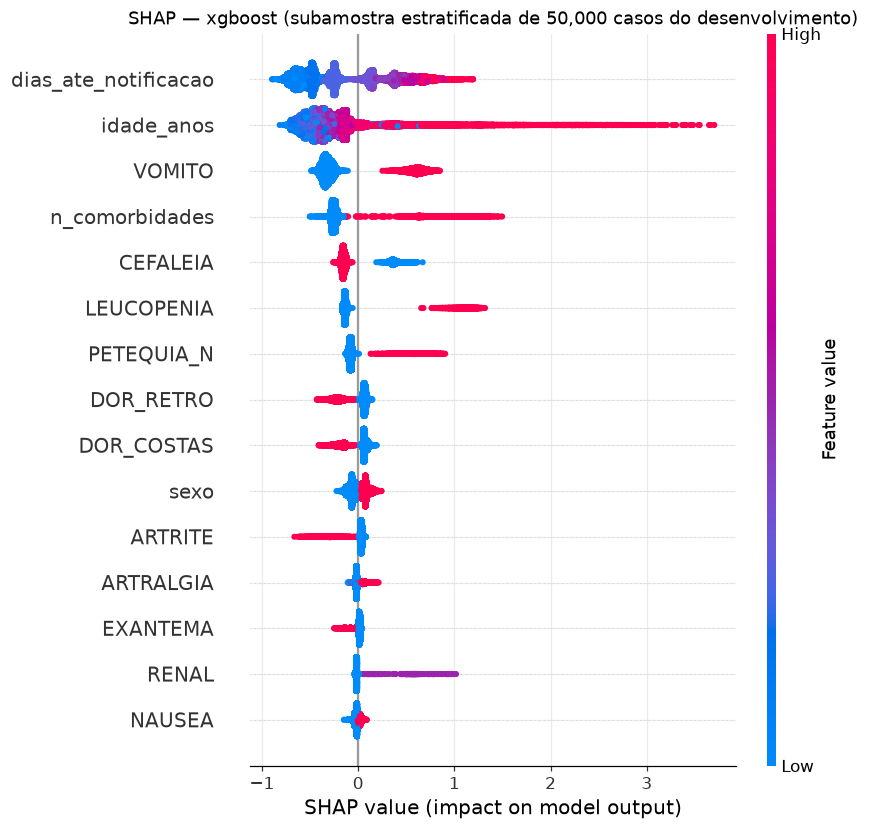

Importância preditiva ( SHAP (|valor| médio, em log-odds) ):


,feature,mean_abs_shap
0,dias_ate_notificacao,0.46113
1,idade_anos,0.40059
2,VOMITO,0.39160
3,n_comorbidades,0.30942
4,CEFALEIA,0.19871
5,LEUCOPENIA,0.18453
6,PETEQUIA_N,0.11928
7,DOR_RETRO,0.11417
8,DOR_COSTAS,0.10740
9,sexo,0.08031


Maiores interações SHAP entre pares (subamostra de 3,000 linhas):


,A,B,mean_abs_interacao
24,idade_anos,dias_ate_notificacao,0.09197
14,idade_anos,VOMITO,0.08147
0,idade_anos,sexo,0.06262
279,VOMITO,dias_ate_notificacao,0.04747
271,VOMITO,DOR_COSTAS,0.03708
270,VOMITO,NAUSEA,0.02689
48,sexo,dias_ate_notificacao,0.02641
219,n_comorbidades,dias_ate_notificacao,0.02295
241,MIALGIA,ARTRALGIA,0.02184
9,idade_anos,n_comorbidades,0.02116


,comorbidade,OR,mean_abs_shap,posição_OR,posição_importância
0,HEMATOLOG,9.2952,0.0177,1.0,2.0
1,RENAL,6.7072,0.0215,2.0,1.0
2,AUTO_IMUNE,5.0239,0.0111,3.0,5.0
3,HEPATOPAT,4.9546,0.0119,4.0,3.0
4,DIABETES,3.0661,0.0068,5.0,7.0
5,HIPERTENSA,2.5590,0.0115,6.0,4.0
6,ACIDO_PEPT,0.7006,0.0100,7.0,6.0


Correlação de postos (Spearman) entre OR e importância preditiva: 0.71. Diferenças são esperadas: respondem a perguntas diferentes (associação ajustada × contribuição ao modelo).


,comorbidade,OR,mean_abs_shap,posição_OR,posição_importância
0,HEMATOLOG,9.295240,0.017748,1.0,2.0
1,RENAL,6.707186,0.021468,2.0,1.0
2,AUTO_IMUNE,5.023907,0.011085,3.0,5.0
3,HEPATOPAT,4.954611,0.011862,4.0,3.0
4,DIABETES,3.066058,0.006836,5.0,7.0
5,HIPERTENSA,2.558972,0.011539,6.0,4.0
6,ACIDO_PEPT,0.700611,0.009975,7.0,6.0


In [34]:
try:
    import shap
except ImportError:
    shap = None

n_shap = CONFIG["SHAP_AMOSTRA"] if nome_arvore == "xgboost" else min(CONFIG["SHAP_AMOSTRA"], 5_000)
idx_s = amostra_estratificada(y, n_shap, CONFIG["SEED"])
Xs = matriz_arvore(x.iloc[idx_s], dias_nan=-1.0 if nome_arvore == "random_forest" else None)
imp = None
if shap is not None:
    expl = shap.TreeExplainer(M_ARVORE.motor_)
    sv = expl.shap_values(Xs)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, -1]
    imp = pd.DataFrame({"feature": Xs.columns, "mean_abs_shap": np.abs(sv).mean(axis=0)})
    metodo_imp = "SHAP (|valor| médio, em log-odds)"
    fig = plt.figure(figsize=(8, 5))
    shap.summary_plot(sv, Xs, show=False, max_display=15)
    plt.title(f"SHAP — {nome_arvore} (subamostra estratificada de {len(idx_s):,} casos do desenvolvimento)")
    salvar_figura(plt.gcf(), "shap_resumo")
else:  # alternativa: importância por permutação (queda de PR-AUC), na mesma subamostra
    rng = np.random.default_rng(CONFIG["SEED"])
    xa, ya = x.iloc[idx_s].reset_index(drop=True), y[idx_s]
    base = pr_auc(ya, M_ARVORE.prever(xa))
    linhas = []
    for c in x.columns:
        perda = []
        for _ in range(3):
            xp = xa.copy()
            xp[c] = xp[c].sample(frac=1, random_state=int(rng.integers(1e9))).reset_index(drop=True)  # mantém o dtype
            perda.append(base - pr_auc(ya, M_ARVORE.prever(xp)))
        linhas.append({"feature": c, "mean_abs_shap": float(np.mean(perda))})
    imp = pd.DataFrame(linhas)
    metodo_imp = "permutação (queda de PR-AUC) — SHAP não instalado"
imp = imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
print("Importância preditiva (", metodo_imp, "):")
display(imp.head(15).round(5))
salvar_tabela(imp, "importancia_preditiva")

# Interações SHAP (FR-13, SHOULD): só XGBoost, subamostra menor por custo O(n·F²)
if shap is not None and nome_arvore == "xgboost":
    k = min(CONFIG["SHAP_INTERACAO_AMOSTRA"], len(Xs))
    iv = np.abs(expl.shap_interaction_values(Xs.iloc[:k]))
    F = len(Xs.columns)
    pares_iv = [{"A": Xs.columns[i], "B": Xs.columns[j], "mean_abs_interacao": iv[:, i, j].mean() * 2}
                for i in range(F) for j in range(i + 1, F)]
    tab_iv = pd.DataFrame(pares_iv).sort_values("mean_abs_interacao", ascending=False).head(10)
    print(f"Maiores interações SHAP entre pares (subamostra de {k:,} linhas):")
    display(tab_iv.round(5))
    salvar_tabela(tab_iv, "shap_interacoes")

# Importância preditiva ≠ associação: comparação (só descritiva) com o ranking pelo OR do E1
comp = rank[["comorbidade", "OR"]].merge(imp.rename(columns={"feature": "comorbidade"}), on="comorbidade")
comp["posição_OR"] = comp["OR"].rank(ascending=False)
comp["posição_importância"] = comp["mean_abs_shap"].rank(ascending=False)
rho = spearmanr(comp["posição_OR"], comp["posição_importância"])[0] if len(comp) > 2 else np.nan
display(comp.round(4))
print(f"Correlação de postos (Spearman) entre OR e importância preditiva: {rho:.2f}. "
      "Diferenças são esperadas: respondem a perguntas diferentes (associação ajustada × contribuição ao modelo).")
salvar_tabela(comp, "or_vs_importancia")

In [35]:
import subprocess as _sp

try:
    COMMIT = _sp.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=BASE, timeout=10).stdout.strip() or None
except Exception:
    COMMIT = None

BUNDLE = {"m1": M1_FINAL, "calibrador": cal_final, "limiar_f2": LIM_F2, "limiar_sens_b2": LIM_SENS,
          "limiar_frac_b2": LIM_FRAC, "b1": B1_FINAL, "limiar_b1_f2": LIM_B1, "modelo": SELECIONADO,
          "features": FEATURES_M1, "prevalencia_dev": float(y.mean())}
caminho_bundle = OUT_DIR / "artefatos" / "m1_congelado.joblib"
joblib.dump(BUNDLE, caminho_bundle)
SHA_BUNDLE = sha256_file(caminho_bundle)
META = {"congelado_em_utc": pd.Timestamp.now("UTC").isoformat(timespec="seconds"), "sha256_modelo": SHA_BUNDLE,
        "commit_git": COMMIT, "seed": CONFIG["SEED"], "ambiente": AMBIENTE, "assinatura_dados_dev": ASSINATURA_DEV,
        "config": json.loads(json.dumps(CONFIG, default=list)), "grades": GRADES, "selecao": RESULTADOS["selecao_m1"],
        "metricas_validacao": RESULTADOS["dev"],
        "e1": {"rhs": m_e1.rhs, "nos": list(nos), "pares": [list(p) for p in pares_e1],
               "coeficientes": {k: float(v) for k, v in m_e1.beta.items()}}}
(OUT_DIR / "artefatos" / "m1_congelado_metadados.json").write_text(
    json.dumps(META, indent=2, ensure_ascii=False, default=str), "utf-8")
print("Modelo congelado:", caminho_bundle.name, "| SHA-256:", SHA_BUNDLE[:20], "…")
print("Limiares congelados:", {k: round(BUNDLE[k], 6) for k in ("limiar_f2", "limiar_sens_b2", "limiar_frac_b2", "limiar_b1_f2")})

Modelo congelado: m1_congelado.joblib | SHA-256: 6286d444d050279727db …
Limiares congelados: {'limiar_f2': 0.025828, 'limiar_sens_b2': 0.002375, 'limiar_frac_b2': 0.001279, 'limiar_b1_f2': 0.011924}


### Avaliação única no teste (2024)

**Lacre (R2):** antes de ler 2024 grava-se `LACRE_TESTE_2024.json` com o SHA-256 do modelo congelado.
Se uma execução anterior **terminou**, esta célula **falha**. (Se uma execução for interrompida antes de
gravar os resultados, o lacre fica `em_andamento` e o número de tentativas interrompidas é registrado.)
Apagar o lacre à mão invalida a afirmação de "uso único" e **deve ser declarado** no relatório.

Tudo o que depende de 2024 é calculado **dentro de uma única função**, que carrega o modelo **do disco** (o
que foi congelado) e guarda só agregados. As seções 17 e 18 apenas apresentam o resultado.

In [36]:
LACRE = OUT_DIR / "LACRE_TESTE_2024.json"


def abrir_lacre(sha):
    estado = {"tentativas_interrompidas": 0}
    if LACRE.exists():
        estado = json.loads(LACRE.read_text("utf-8"))
        if estado.get("status") == "concluido":
            raise RuntimeError(
                "R2 violada: o teste de 2024 já foi avaliado (lacre concluído em "
                f"{estado.get('concluido_em')}). Usar o teste mais de uma vez torna o resultado otimista. "
                "Apagar o lacre invalida a afirmação de uso único e deve ser declarado no relatório.")
        estado["tentativas_interrompidas"] = estado.get("tentativas_interrompidas", 0) + 1
    estado.update(status="em_andamento", iniciado_em=pd.Timestamp.now("UTC").isoformat(timespec="seconds"),
                  sha256_modelo_congelado=sha)
    LACRE.write_text(json.dumps(estado, indent=2), "utf-8")
    return estado


def fechar_lacre(estado, sha_resultados):
    estado.update(status="concluido", concluido_em=pd.Timestamp.now("UTC").isoformat(timespec="seconds"),
                  sha256_resultados=sha_resultados)
    LACRE.write_text(json.dumps(estado, indent=2), "utf-8")


def _suprimir(df, col_n, minimo=CONFIG["MIN_CELULA"]):
    d = df.copy()
    d[col_n] = d[col_n].where(d[col_n] >= minimo, np.nan)
    return d


def avaliar_teste_uma_vez():
    B = CONFIG["BOOT"]
    sd = CONFIG["SEED"]
    b = joblib.load(caminho_bundle)
    assert sha256_file(caminho_bundle) == SHA_BUNDLE, "O modelo em disco não é o que foi congelado."
    garantir_dados([CONFIG["ANO_TESTE"]])
    raw24 = ler_ano(CONFIG["ANO_TESTE"])
    dominios24 = checar_dominios_alvo(raw24, CONFIG["ANO_TESTE"])  # check bloqueante também em 2024
    pop24 = montar_populacao(raw24, CONFIG["ANO_TESTE"])
    del raw24
    gc.collect()
    x24, y24 = montar_features(pop24), pop24["y"].to_numpy()
    assert_features_permitidas(list(x24.columns), FEATURES_M1)

    # --- predições do que foi congelado (nada é reajustado aqui)
    p_m1 = b["calibrador"].prever(b["m1"].prever(x24))
    p_b1 = b["b1"].prever(x24)
    p_b0 = np.full(len(y24), b["prevalencia_dev"])
    f_b2 = b2_flag(x24)
    flags = {"b2": f_b2, "m1_f2": p_m1 >= b["limiar_f2"], "m1_sens": p_m1 >= b["limiar_sens_b2"],
             "m1_frac": p_m1 >= b["limiar_frac_b2"], "b1_f2": p_b1 >= b["limiar_b1_f2"]}

    res = {"n": int(len(y24)), "eventos": int(y24.sum()), "prevalencia": float(y24.mean()),
           "dominios": dominios24}
    # --- métricas pontuais (exatas)
    scores = {"m1": p_m1, "b1": p_b1, "b0": p_b0}
    res["discriminacao"] = {k: {"pr_auc": pr_auc(y24, v), "roc_auc": roc_auc(y24, v), "brier": brier(y24, v)}
                            for k, v in scores.items()}
    res["calibracao"] = {"m1": calibracao_resumo(y24, p_m1), "b1": calibracao_resumo(y24, p_b1)}
    res["limiar"] = {k: metricas_limiar(y24, f) for k, f in flags.items()}
    res["limiar"]["b0"] = metricas_limiar(y24, np.zeros(len(y24), bool))

    # --- bootstrap pareado (mesmas reamostras para todos os modelos)
    tab = agregar(y24, scores, flags)
    bt = bootstrap_metricas(tab, B=B, seed=sd)
    ic = {k: ic95(v) for k, v in bt.items()}
    res["ic95"] = {k: list(v) for k, v in ic.items()}
    dif = {"PR-AUC M1 − B1": bt["pr_auc[m1]"] - bt["pr_auc[b1]"],
           "PR-AUC M1 − B0": bt["pr_auc[m1]"] - bt["pr_auc[b0]"],
           "ROC-AUC M1 − B1": bt["roc_auc[m1]"] - bt["roc_auc[b1]"],
           "Brier M1 − B1": bt["brier[m1]"] - bt["brier[b1]"],
           "F2-limiar: sensibilidade M1 − B2": bt["sensibilidade[m1_f2]"] - bt["sensibilidade[b2]"],
           "F2-limiar: VPP M1 − B2": bt["VPP[m1_f2]"] - bt["VPP[b2]"],
           "mesma sensibilidade: VPP M1 − B2": bt["VPP[m1_sens]"] - bt["VPP[b2]"],
           "mesma sensibilidade: especificidade M1 − B2": bt["especificidade[m1_sens]"] - bt["especificidade[b2]"],
           "mesma sensibilidade: % sinalizados M1 − B2": bt["pct_sinalizados[m1_sens]"] - bt["pct_sinalizados[b2]"],
           "mesma fração sinalizada: sensibilidade M1 − B2": bt["sensibilidade[m1_frac]"] - bt["sensibilidade[b2]"]}
    pont = {"PR-AUC M1 − B1": res["discriminacao"]["m1"]["pr_auc"] - res["discriminacao"]["b1"]["pr_auc"],
            "PR-AUC M1 − B0": res["discriminacao"]["m1"]["pr_auc"] - res["discriminacao"]["b0"]["pr_auc"],
            "ROC-AUC M1 − B1": res["discriminacao"]["m1"]["roc_auc"] - res["discriminacao"]["b1"]["roc_auc"],
            "Brier M1 − B1": res["discriminacao"]["m1"]["brier"] - res["discriminacao"]["b1"]["brier"],
            "F2-limiar: sensibilidade M1 − B2": res["limiar"]["m1_f2"]["sensibilidade"] - res["limiar"]["b2"]["sensibilidade"],
            "F2-limiar: VPP M1 − B2": res["limiar"]["m1_f2"]["VPP"] - res["limiar"]["b2"]["VPP"],
            "mesma sensibilidade: VPP M1 − B2": res["limiar"]["m1_sens"]["VPP"] - res["limiar"]["b2"]["VPP"],
            "mesma sensibilidade: especificidade M1 − B2": res["limiar"]["m1_sens"]["especificidade"] - res["limiar"]["b2"]["especificidade"],
            "mesma sensibilidade: % sinalizados M1 − B2": res["limiar"]["m1_sens"]["pct_sinalizados"] - res["limiar"]["b2"]["pct_sinalizados"],
            "mesma fração sinalizada: sensibilidade M1 − B2": res["limiar"]["m1_frac"]["sensibilidade"] - res["limiar"]["b2"]["sensibilidade"]}
    res["diferencas"] = {k: {"estimativa": float(pont[k]), "ic95_inf": ic95(v)[0], "ic95_sup": ic95(v)[1]}
                         for k, v in dif.items()}
    res["nri"] = {}
    for rot, col in (("M1 no limiar F2", "f_m1_f2"), ("M1 com a sensibilidade de B2", "f_m1_sens"),
                     ("M1 com a fração sinalizada de B2", "f_m1_frac")):
        p0, am = nri_bootstrap(tab, col, "f_b2", B=B, seed=sd)
        res["nri"][rot] = {"NRI": p0, "ic95_inf": ic95(am)[0], "ic95_sup": ic95(am)[1]}

    # --- reclassificação B2 × M1 (contagens; células < 10 suprimidas)
    cr = pd.DataFrame({"y": y24, "B2": f_b2, "M1": flags["m1_f2"]}).groupby(["y", "B2", "M1"]).size().rename("n").reset_index()
    res["reclassificacao"] = _suprimir(cr, "n").to_dict("records")

    # --- subgrupos (D-13, D-48): PR-AUC com IC, recall no limiar F2 de M1 e de B2
    raca = code(pop24["CS_RACA"]).fillna("branco").map(
        {"1": "branca", "2": "preta", "3": "amarela", "4": "parda", "5": "indígena", "9": "ignorada"}).fillna("outra/branco")
    grupos = [("faixa etária", pop24["faixa_etaria"].astype("string")), ("sexo", x24["sexo"].astype("string")),
              ("gestante", pop24["gestante"].map({True: "sim", False: "não"})), ("região", pop24["regiao"].astype("string")),
              ("raça/cor", raca)]
    sub = []
    for gnome, serie in grupos:
        for cat in sorted(serie.dropna().unique(), key=str):
            m = (serie == cat).to_numpy()
            ev = int(y24[m].sum())
            if m.sum() < CONFIG["MIN_CELULA"] or ev < 2:
                sub.append({"grupo": gnome, "categoria": cat, "casos": int(m.sum()), "eventos": ev if ev >= CONFIG["MIN_CELULA"] else np.nan,
                            "aviso": "poucos eventos: sem métricas"})
                continue
            tab_s = agregar(y24[m], {"m1": p_m1[m]})
            bt_s = bootstrap_metricas(tab_s, B=CONFIG["BOOT_SUBGRUPO"], seed=sd)
            lo, hi = ic95(bt_s["pr_auc[m1]"])
            fl = flags["m1_f2"][m]
            linha = {"grupo": gnome, "categoria": cat, "casos": int(m.sum()), "eventos": ev if ev >= CONFIG["MIN_CELULA"] else np.nan,
                     "prevalência_%": 100 * y24[m].mean(), "PR-AUC M1": pr_auc(y24[m], p_m1[m]),
                     "ic95_inf": lo, "ic95_sup": hi, "recall M1 (F2)": float((fl & (y24[m] == 1)).sum() / ev),
                     "recall B2": float((f_b2[m] & (y24[m] == 1)).sum() / ev)}
            if ev >= CONFIG["MIN_EVENTOS_SUBGRUPO"]:
                linha["slope M1"] = calibracao_resumo(y24[m], p_m1[m])["slope"]
            else:
                linha["aviso"] = "< 100 eventos: IC largo, sem conclusões"
            sub.append(linha)
    res["subgrupos"] = sub

    # --- utilidade clínica (curva de decisão) e calibração
    lims = np.linspace(*CONFIG["DCA_LIMIARES"][:2], CONFIG["DCA_LIMIARES"][2])
    res["dca"] = {"limiar": lims.tolist(), "M1": curva_decisao(y24, p=p_m1, limiares=lims)["net_benefit"].tolist(),
                  "B1": curva_decisao(y24, p=p_b1, limiares=lims)["net_benefit"].tolist(),
                  "B2": curva_decisao(y24, flag=f_b2, limiares=lims)["net_benefit"].tolist(),
                  "todos": net_benefit_todos(float(y24.mean()), lims).tolist()}
    pf = {}
    for rot, f in (("M1 F2", flags["m1_f2"]),):
        pf[rot] = float(metricas_limiar(y24, f)["sensibilidade"])
    res["calibracao_curva"] = {k: curva_calibracao(y24, v).to_dict("list") for k, v in (("M1", p_m1), ("B1", p_b1))}
    res["pr_curva_pontos"] = {"M1": [res["limiar"]["m1_f2"]["sensibilidade"], res["limiar"]["m1_f2"]["VPP"]],
                              "B2": [res["limiar"]["b2"]["sensibilidade"], res["limiar"]["b2"]["VPP"]]}

    # --- E1 em 2024: checagem de calibração (casos completos)
    ok24 = completos_para_e1(pop24, x24).to_numpy()
    d24 = pd.DataFrame({"idade": x24["idade_anos"].round(2), "sexo_M": (x24["sexo"] == "M").astype(int),
                        "gestante": x24["gestante"].astype(int),
                        **{c: (x24[c] == "Sim").astype(int) for c in COMORBIDADES}})[ok24]
    p_e1 = prever_e1(m_e1, d24)
    res["e1_2024"] = {"casos": int(ok24.sum()), "calibracao": calibracao_resumo(y24[ok24], p_e1),
                      "pr_auc": pr_auc(y24[ok24], p_e1), "roc_auc": roc_auc(y24[ok24], p_e1),
                      "curva": curva_calibracao(y24[ok24], p_e1).to_dict("list")}

    # --- análise de erros (agregada): falsos negativos × verdadeiros positivos no limiar F2
    fn = (~flags["m1_f2"]) & (y24 == 1)
    tp_ = flags["m1_f2"] & (y24 == 1)
    n_com = x24["n_comorbidades"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
    ordem_fn = np.flatnonzero(fn)[np.argsort(p_m1[fn])[:100]]  # os 100 FN de menor risco previsto
    mask100 = np.zeros(len(y24), bool)
    mask100[ordem_fn] = True
    erros = []
    for rot, serie in (("faixa etária", pop24["faixa_etaria"].astype("string")), ("nº de comorbidades", n_com.astype("string")),
                       ("região", pop24["regiao"].astype("string"))):
        for cat in sorted(serie.dropna().unique(), key=str):
            m = (serie == cat).to_numpy()
            erros.append({"variável": rot, "categoria": cat, "FN": int((fn & m).sum()), "VP": int((tp_ & m).sum()),
                          "100 FN de menor risco previsto": int((mask100 & m).sum())})
    res["erros"] = _suprimir(_suprimir(_suprimir(pd.DataFrame(erros), "FN"), "VP"), "100 FN de menor risco previsto").to_dict("records")
    res["erros_resumo"] = {"FN": int(fn.sum()), "VP": int(tp_.sum()),
                           "atraso_mediano_FN": float(np.nanmedian(x24.loc[fn, "dias_ate_notificacao"])) if fn.any() else np.nan,
                           "atraso_mediano_VP": float(np.nanmedian(x24.loc[tp_, "dias_ate_notificacao"])) if tp_.any() else np.nan}
    res["conferencia_profiling_2024"] = {"casos_esperado": 5_331_745, "casos_obtido": res["n"],
                                         "eventos_esperado": 11_338, "eventos_obtido": res["eventos"]}
    return res

In [37]:
estado_lacre = abrir_lacre(SHA_BUNDLE)
TESTE = avaliar_teste_uma_vez()          # se falhar aqui, o lacre fica 'em_andamento' (não 'concluido')
arq_res = OUT_DIR / "tabelas" / "teste_2024_resultados.json"
arq_res.write_text(json.dumps(TESTE, indent=2, ensure_ascii=False, default=float), "utf-8")
fechar_lacre(estado_lacre, sha256_file(arq_res))
RESULTADOS["teste"] = {k: TESTE[k] for k in ("n", "eventos", "prevalencia", "discriminacao", "calibracao")}
print("Avaliação do teste de 2024 CONCLUÍDA e lacrada. Resultados nas seções 17 e 18.")
print("Lacre:", LACRE.name, "→", json.loads(LACRE.read_text("utf-8"))["status"])

Avaliação do teste de 2024 CONCLUÍDA e lacrada. Resultados nas seções 17 e 18.
Lacre: LACRE_TESTE_2024.json → concluido


## 17. Comparação com a estratificação do Ministério da Saúde

**B2** = "alto risco" se o caso cumprir **qualquer** critério do grupo B do protocolo do MS (6ª ed., 2024)
que exista na ficha `[ASSUMPTION]`: idade < 24 meses ou > 65 anos; gestante; ≥ 1 das 7 comorbidades;
prova do laço positiva ou petéquias. **Não cobre** DPOC, asma, obesidade, outras cardiopatias nem risco
social (não existem na ficha): a regra real é mais ampla que a avaliada aqui. É uma regra **binária**, então
a comparação é no **limiar** (sensibilidade, especificidade, VPP, VPN, % sinalizados), não em AUC.

Comparamos nos **mesmos pacientes e desfechos**, em duas condições: (i) desenvolvimento, fora da dobra
(seção 15, com limiares só do desenvolvimento); (ii) **teste 2024**, com limiares **congelados**. M1 é
avaliado em três pontos de operação: o limiar do F2, a **mesma sensibilidade** de B2 e a **mesma fração
sinalizada** de B2 (limiares derivados só do desenvolvimento).

In [38]:
def ic_txt(chave, fmt="{:.3f}"):
    lo, hi = TESTE["ic95"][chave]
    return f"[{fmt.format(lo)}–{fmt.format(hi)}]"


rotulos = {"b0": "B0 (ninguém)", "b2": "B2 — regra do MS", "b1_f2": "B1 no limiar F2", "m1_f2": "M1 no limiar F2",
           "m1_sens": "M1 com a sensibilidade de B2 (dev)", "m1_frac": "M1 com a fração sinalizada de B2 (dev)"}
linhas = []
for k, rot in rotulos.items():
    m = TESTE["limiar"][k]
    linha = {"classificador": rot, "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"]}
    for met, chave in (("sensibilidade", "sensibilidade"), ("especificidade", "especificidade"), ("VPP", "VPP"),
                       ("VPN", "VPN"), ("% sinalizados", "pct_sinalizados")):
        linha[met] = m[chave]
        if f"{chave}[{k}]" in TESTE["ic95"]:
            linha[f"{met} IC95%"] = ic_txt(f"{chave}[{k}]", "{:.4f}")
    linha["F2"] = m["F2"]
    linhas.append(linha)
comp_ms = pd.DataFrame(linhas)
print(f"Teste 2024: {TESTE['n']:,} casos, {TESTE['eventos']:,} eventos ({100 * TESTE['prevalencia']:.3f}%). "
      "Limiares congelados no desenvolvimento.")
display(comp_ms.round(4))
salvar_tabela(comp_ms, "comparacao_ms_teste")

print("\nMesmos pacientes, desenvolvimento (fora da dobra) — para comparar com o teste:")
display(lim_dev.round(4))

Teste 2024: 5,331,745 casos, 11,338 eventos (0.213%). Limiares congelados no desenvolvimento.


,classificador,TP,FP,FN,TN,sensibilidade,especificidade,VPP,VPN,% sinalizados,F2,sensibilidade IC95%,especificidade IC95%,VPP IC95%,VPN IC95%,% sinalizados IC95%
0,B0 (ninguém),0,0,11338,5320407,0.0000,1.0000,NaN,0.9979,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN
1,B2 — regra do MS,7484,1406597,3854,3913810,0.6601,0.7356,0.0053,0.9990,0.2652,0.0256,[0.6519–0.6693],[0.7352–0.7360],[0.0052–0.0054],[0.9990–0.9990],[0.2649–0.2656]
2,B1 no limiar F2,2081,70874,9257,5249533,0.1835,0.9867,0.0285,0.9982,0.0137,0.0879,[0.1764–0.1904],[0.9866–0.9868],[0.0274–0.0296],[0.9982–0.9983],[0.0136–0.0138]
3,M1 no limiar F2,2329,41575,9009,5278832,0.2054,0.9922,0.0530,0.9983,0.0082,0.1305,[0.1982–0.2125],[0.9921–0.9923],[0.0512–0.0549],[0.9983–0.9983],[0.0082–0.0083]
4,M1 com a sensibilidade de B2 (dev),7485,776499,3853,4543908,0.6602,0.8541,0.0095,0.9992,0.1470,0.0451,[0.6511–0.6684],[0.8537–0.8543],[0.0094–0.0097],[0.9991–0.9992],[0.1468–0.1474]
5,M1 com a fração sinalizada de B2 (dev),8569,1266797,2769,4053610,0.7558,0.7619,0.0067,0.9993,0.2392,0.0324,[0.7481–0.7639],[0.7615–0.7623],[0.0067–0.0068],[0.9993–0.9993],[0.2388–0.2396]



Mesmos pacientes, desenvolvimento (fora da dobra) — para comparar com o teste:


,classificador,TP,FP,FN,TN,sensibilidade,especificidade,VPP,VPN,acuracia,F1,F2,pct_sinalizados
0,B0 (ninguém),0,0,3985,2449223,0.0000,1.0000,NaN,0.9984,0.9984,0.0000,0.0000,0.0000
1,B2 — regra do MS,2727,643071,1258,1806152,0.6843,0.7374,0.0042,0.9993,0.7374,0.0084,0.0206,0.2632
2,B1 no limiar F2,631,32316,3354,2416907,0.1583,0.9868,0.0192,0.9986,0.9855,0.0342,0.0645,0.0134
3,M1 no limiar F2,798,16804,3187,2432419,0.2003,0.9931,0.0453,0.9987,0.9919,0.0739,0.1190,0.0072
4,M1 com a mesma sensibilidade de B2,2770,369735,1215,2079488,0.6951,0.8490,0.0074,0.9994,0.8488,0.0147,0.0357,0.1518
5,M1 sinalizando a mesma fração de B2,3152,612230,833,1836993,0.7910,0.7500,0.0051,0.9995,0.7501,0.0102,0.0250,0.2508


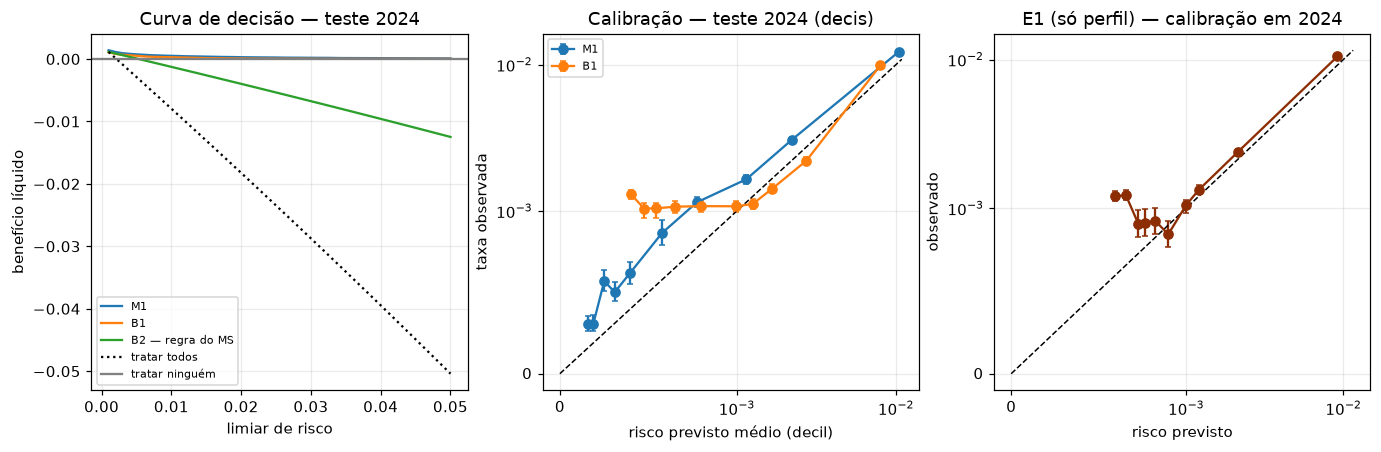

Discriminação e calibração — teste 2024 (IC 95% por bootstrap estratificado):


,modelo,pr_auc,roc_auc,brier,pr_auc IC95%,roc_auc IC95%,brier IC95%
0,m1,0.032192,0.833571,0.002085,[0.0301–0.0343],[0.8295–0.8377],[0.0021–0.0021]
1,b1,0.015835,0.716098,0.002108,[0.0149–0.0169],[0.7101–0.7221],[0.0021–0.0021]
2,b0,0.002127,0.500000,0.002122,[0.0021–0.0021],[0.5000–0.5000],[0.0021–0.0021]


,modelo,slope,slope_ic95,intercepto_citl,intercepto_ic95,O:E
0,m1,0.924987,"(0.914124, 0.935849)",0.263545,"(0.244903, 0.282188)",1.293873
1,b1,0.938152,"(0.922639, 0.953664)",0.194491,"(0.176007, 0.212975)",1.2129


E1 em 2024 (5,325,490 casos completos): slope 0.955, intercepto 0.171, O:E 1.184, ROC-AUC 0.733

Subgrupos no teste (idade, sexo, gestação, região, raça/cor). Aviso = poucos eventos → IC largo:


,grupo,categoria,casos,eventos,prevalência_%,PR-AUC M1,ic95_inf,ic95_sup,recall M1 (F2),recall B2,slope M1,aviso
0,faixa etária,0–4,163839,259.0,0.1581,0.0104,0.0073,0.0191,0.0888,0.7490,0.8131,NaN
1,faixa etária,15–39,2274560,2647.0,0.1164,0.0084,0.0076,0.0096,0.0295,0.3007,0.9042,NaN
2,faixa etária,40–59,1457762,2380.0,0.1633,0.0126,0.0111,0.0143,0.0550,0.4878,0.9418,NaN
3,faixa etária,5–14,641272,536.0,0.0836,0.0063,0.0046,0.0106,0.0336,0.2313,0.8427,NaN
4,faixa etária,60–79,699861,3313.0,0.4734,0.0340,0.0315,0.0370,0.2264,0.9073,0.9434,NaN
5,faixa etária,80+,94451,2203.0,2.3324,0.0826,0.0763,0.0890,0.6033,1.0000,0.8842,NaN
6,sexo,F,2909965,6046.0,0.2078,0.0261,0.0241,0.0285,0.1717,0.6383,0.8936,NaN
7,sexo,I,6196,NaN,0.1130,0.0605,0.0197,0.1843,0.4286,0.7143,NaN,"< 100 eventos: IC largo, sem conclusões"
8,sexo,M,2415584,5285.0,0.2188,0.0391,0.0367,0.0419,0.2437,0.6850,0.9570,NaN
9,gestante,não,5291699,11236.0,0.2123,0.0325,0.0306,0.0345,0.2069,0.6570,0.9263,NaN


,grupo,categoria,casos,eventos,prevalência_%,PR-AUC M1,ic95_inf,ic95_sup,recall M1 (F2),recall B2,slope M1,aviso
0,faixa etária,0–4,163839,259.0,0.158082,0.010362,0.007274,0.019064,0.088803,0.749035,0.813092,NaN
1,faixa etária,15–39,2274560,2647.0,0.116374,0.008391,0.007555,0.009600,0.029467,0.300718,0.904172,NaN
2,faixa etária,40–59,1457762,2380.0,0.163264,0.012601,0.011083,0.014339,0.055042,0.487815,0.941836,NaN
3,faixa etária,5–14,641272,536.0,0.083584,0.006343,0.004638,0.010600,0.033582,0.231343,0.842653,NaN
4,faixa etária,60–79,699861,3313.0,0.473380,0.034007,0.031487,0.037028,0.226381,0.907335,0.943385,NaN
5,faixa etária,80+,94451,2203.0,2.332426,0.082645,0.076259,0.089047,0.603268,1.000000,0.884154,NaN
6,sexo,F,2909965,6046.0,0.207769,0.026092,0.024119,0.028495,0.171684,0.638273,0.893627,NaN
7,sexo,I,6196,NaN,0.112976,0.060529,0.019712,0.184330,0.428571,0.714286,NaN,"< 100 eventos: IC largo, sem conclusões"
8,sexo,M,2415584,5285.0,0.218788,0.039116,0.036670,0.041887,0.243709,0.684957,0.957012,NaN
9,gestante,não,5291699,11236.0,0.212333,0.032462,0.030570,0.034520,0.206924,0.656995,0.926330,NaN


In [39]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
d = TESTE["dca"]
eixos[0].plot(d["limiar"], d["M1"], label="M1"); eixos[0].plot(d["limiar"], d["B1"], label="B1")
eixos[0].plot(d["limiar"], d["B2"], label="B2 — regra do MS"); eixos[0].plot(d["limiar"], d["todos"], "k:", label="tratar todos")
eixos[0].axhline(0, color="grey", label="tratar ninguém")
eixos[0].set_xlabel("limiar de risco"); eixos[0].set_ylabel("benefício líquido")
eixos[0].set_title("Curva de decisão — teste 2024"); eixos[0].legend(fontsize=7)

for k, rot in (("M1", "M1"), ("B1", "B1")):
    cc = pd.DataFrame(TESTE["calibracao_curva"][k])
    eixos[1].errorbar(cc["p_medio"], cc["taxa_observada"],
                      yerr=[cc["taxa_observada"] - cc["ic95_inf"], cc["ic95_sup"] - cc["taxa_observada"]],
                      marker="o", capsize=2, label=rot)
lim = max(cc["p_medio"].max(), cc["taxa_observada"].max()) * 1.1
eixos[1].plot([0, lim], [0, lim], "k--", lw=1)
eixos[1].set_xscale("symlog", linthresh=1e-3); eixos[1].set_yscale("symlog", linthresh=1e-3)
eixos[1].set_xlabel("risco previsto médio (decil)"); eixos[1].set_ylabel("taxa observada")
eixos[1].set_title("Calibração — teste 2024 (decis)"); eixos[1].legend(fontsize=7)

ce = pd.DataFrame(TESTE["e1_2024"]["curva"])
eixos[2].errorbar(ce["p_medio"], ce["taxa_observada"],
                  yerr=[ce["taxa_observada"] - ce["ic95_inf"], ce["ic95_sup"] - ce["taxa_observada"]],
                  marker="o", capsize=2, color="#8c2d04")
lim = max(ce["p_medio"].max(), ce["taxa_observada"].max()) * 1.1
eixos[2].plot([0, lim], [0, lim], "k--", lw=1)
eixos[2].set_xscale("symlog", linthresh=1e-3); eixos[2].set_yscale("symlog", linthresh=1e-3)
eixos[2].set_title("E1 (só perfil) — calibração em 2024"); eixos[2].set_xlabel("risco previsto"); eixos[2].set_ylabel("observado")
salvar_figura(fig, "teste_dca_calibracao")

disc = pd.DataFrame(TESTE["discriminacao"]).T.rename_axis("modelo").reset_index()
for k in ("pr_auc", "roc_auc", "brier"):
    disc[f"{k} IC95%"] = [ic_txt(f"{k}[{m}]", "{:.4f}") for m in disc["modelo"]]
cal = pd.DataFrame(TESTE["calibracao"]).T.rename_axis("modelo").reset_index()
print("Discriminação e calibração — teste 2024 (IC 95% por bootstrap estratificado):")
display(disc)
display(cal)
e1 = TESTE["e1_2024"]
print(f"E1 em 2024 ({e1['casos']:,} casos completos): slope {e1['calibracao']['slope']:.3f}, "
      f"intercepto {e1['calibracao']['intercepto_citl']:.3f}, O:E {e1['calibracao']['O:E']:.3f}, "
      f"ROC-AUC {e1['roc_auc']:.3f}")
salvar_tabela(disc, "teste_discriminacao"); salvar_tabela(cal, "teste_calibracao")

sub = pd.DataFrame(TESTE["subgrupos"])
print("\nSubgrupos no teste (idade, sexo, gestação, região, raça/cor). Aviso = poucos eventos → IC largo:")
display(sub.round(4))
salvar_tabela(sub, "teste_subgrupos")

## 18. Avaliação do valor incremental

Pergunta: **o ML acrescenta algo** além (a) de um modelo simples de perfil (B1) e (b) da regra do MS (B2)?

- **vs B1:** diferença **pareada** de PR-AUC/ROC-AUC/Brier (mesmas reamostras; IC 95% bootstrap).
- **vs B2:** diferenças de VPP, especificidade e % sinalizados **na mesma sensibilidade**, e de sensibilidade na
  **mesma fração sinalizada**; **NRI categórico** (quanto M1 reclassifica corretamente pacientes que B2 classifica).
- **Utilidade clínica:** curva de decisão (benefício líquido).
- **Critérios de sucesso do spec (SC-01 a SC-04, `[ASSUMPTION]`):** abaixo, em tabela. Resultado
  negativo (M1 não supera B1/B2) é **resultado válido** e é reportado como tal.

In [40]:
dif = pd.DataFrame(TESTE["diferencas"]).T.rename_axis("contraste").reset_index()
dif["IC95% exclui 0?"] = np.where((dif["ic95_inf"] > 0) | (dif["ic95_sup"] < 0), "sim", "não")
print("Diferenças pareadas no teste 2024 (M1 − comparador):")
display(dif.round(4))
salvar_tabela(dif, "teste_diferencas_pareadas")

nri = pd.DataFrame(TESTE["nri"]).T.rename_axis("M1 versus B2").reset_index()
print("NRI categórico (M1 como modelo novo, B2 como regra antiga); > 0 = reclassificação líquida a favor de M1:")
display(nri.round(4))
salvar_tabela(nri, "teste_nri")

rc = pd.DataFrame(TESTE["reclassificacao"])
rc["B2"] = rc["B2"].map({True: "alto risco", False: "baixo risco"})
rc["M1 (F2)"] = rc.pop("M1").map({True: "alto risco", False: "baixo risco"})
rc["desfecho"] = rc.pop("y").map({1: "evento (grave/óbito)", 0: "sem evento"})
print("Reclassificação B2 × M1 (contagens; células < 10 suprimidas):")
display(rc[["desfecho", "B2", "M1 (F2)", "n"]])
salvar_tabela(rc[["desfecho", "B2", "M1 (F2)", "n"]], "teste_reclassificacao")

# Critérios de sucesso (spec; [ASSUMPTION]) — avaliados, não impostos
d = TESTE["diferencas"]
m1, b2 = TESTE["limiar"]["m1_f2"], TESTE["limiar"]["b2"]
sc = pd.DataFrame([
    {"critério": "SC-01: PR-AUC de M1 > B0, IC95% da diferença sem 0",
     "resultado": f"Δ = {d['PR-AUC M1 − B0']['estimativa']:.4f} "
                  f"[{d['PR-AUC M1 − B0']['ic95_inf']:.4f}; {d['PR-AUC M1 − B0']['ic95_sup']:.4f}]",
     "atendido": bool(d["PR-AUC M1 − B0"]["ic95_inf"] > 0)},
    {"critério": "SC-02: no limiar F2, recall de M1 ≥ recall de B2 com precisão maior",
     "resultado": f"recall {m1['sensibilidade']:.3f} vs {b2['sensibilidade']:.3f}; "
                  f"precisão {m1['VPP']:.4f} vs {b2['VPP']:.4f}",
     "atendido": bool(m1["sensibilidade"] >= b2["sensibilidade"] and m1["VPP"] > b2["VPP"])},
    {"critério": "SC-03: calibration slope de M1 entre 0,8 e 1,2",
     "resultado": f"slope = {TESTE['calibracao']['m1']['slope']:.3f}",
     "atendido": bool(0.8 <= TESTE["calibracao"]["m1"]["slope"] <= 1.2)},
    {"critério": "SC-04: ΔPR-AUC (M1 − B1) reportada com IC (qualquer sinal)",
     "resultado": f"Δ = {d['PR-AUC M1 − B1']['estimativa']:.4f} "
                  f"[{d['PR-AUC M1 − B1']['ic95_inf']:.4f}; {d['PR-AUC M1 − B1']['ic95_sup']:.4f}]",
     "atendido": True}])
display(sc)
salvar_tabela(sc, "teste_criterios_sucesso")
RESULTADOS["criterios_sucesso"] = sc.to_dict("records")

Diferenças pareadas no teste 2024 (M1 − comparador):


,contraste,estimativa,ic95_inf,ic95_sup,IC95% exclui 0?
0,PR-AUC M1 − B1,0.0164,0.0149,0.0179,sim
1,PR-AUC M1 − B0,0.0301,0.0280,0.0322,sim
2,ROC-AUC M1 − B1,0.1175,0.1127,0.1227,sim
3,Brier M1 − B1,-0.0000,-0.0000,-0.0000,sim
4,F2-limiar: sensibilidade M1 − B2,-0.4547,-0.4638,-0.4459,sim
5,F2-limiar: VPP M1 − B2,0.0478,0.0460,0.0496,sim
6,mesma sensibilidade: VPP M1 − B2,0.0043,0.0041,0.0044,sim
7,mesma sensibilidade: especificidade M1 − B2,0.1184,0.1181,0.1188,sim
8,mesma sensibilidade: % sinalizados M1 − B2,-0.1182,-0.1185,-0.1178,sim
9,mesma fração sinalizada: sensibilidade M1 − B2,0.0957,0.0876,0.1031,sim


NRI categórico (M1 como modelo novo, B2 como regra antiga); > 0 = reclassificação líquida a favor de M1:


,M1 versus B2,NRI,ic95_inf,ic95_sup
0,M1 no limiar F2,-0.1981,-0.2071,-0.1894
1,M1 com a sensibilidade de B2,0.1185,0.1110,0.1260
2,M1 com a fração sinalizada de B2,0.1220,0.1139,0.1294


Reclassificação B2 × M1 (contagens; células < 10 suprimidas):


,desfecho,B2,M1 (F2),n
0,sem evento,baixo risco,baixo risco,3913305
1,sem evento,baixo risco,alto risco,505
2,sem evento,alto risco,baixo risco,1365527
3,sem evento,alto risco,alto risco,41070
4,evento (grave/óbito),baixo risco,baixo risco,3841
5,evento (grave/óbito),baixo risco,alto risco,13
6,evento (grave/óbito),alto risco,baixo risco,5168
7,evento (grave/óbito),alto risco,alto risco,2316


,critério,resultado,atendido
0,"SC-01: PR-AUC de M1 > B0, IC95% da diferença s...",Δ = 0.0301 [0.0280; 0.0322],True
1,"SC-02: no limiar F2, recall de M1 ≥ recall de ...",recall 0.205 vs 0.660; precisão 0.0530 vs 0.0053,False
2,"SC-03: calibration slope de M1 entre 0,8 e 1,2",slope = 0.925,True
3,SC-04: ΔPR-AUC (M1 − B1) reportada com IC (qua...,Δ = 0.0164 [0.0149; 0.0179],True


## 19. Discussão, limitações e conclusões

A célula seguinte **gera o resumo a partir dos números efetivamente calculados** nesta execução (nada é
escrito de memória). O texto interpretativo é condicional ao que os ICs permitem afirmar.

In [41]:
d = TESTE["diferencas"]
dis = TESTE["discriminacao"]
linhas = [
    f"**População:** desenvolvimento {RESULTADOS['populacao_dev']['casos']:,} casos "
    f"({RESULTADOS['populacao_dev']['eventos']:,} eventos, {100 * RESULTADOS['populacao_dev']['prevalencia']:.2f}%); "
    f"teste 2024 {TESTE['n']:,} casos ({TESTE['eventos']:,} eventos, {100 * TESTE['prevalencia']:.2f}%).",
    f"**Modelo M1 selecionado no desenvolvimento:** {SELECIONADO} ({MOTIVO}); calibração {cal_tipo[SELECIONADO]}.",
    f"**Teste 2024 — PR-AUC:** M1 {dis['m1']['pr_auc']:.4f} {ic_txt('pr_auc[m1]', '{:.4f}')}, "
    f"B1 {dis['b1']['pr_auc']:.4f}, B0 {dis['b0']['pr_auc']:.4f} (= prevalência). "
    f"ΔPR-AUC M1 − B1 = {d['PR-AUC M1 − B1']['estimativa']:.4f} "
    f"[{d['PR-AUC M1 − B1']['ic95_inf']:.4f}; {d['PR-AUC M1 − B1']['ic95_sup']:.4f}].",
]
if d["PR-AUC M1 − B1"]["ic95_inf"] > 0:
    linhas.append("→ O IC da diferença **exclui 0 a favor de M1**: há evidência de ganho de discriminação sobre a logística de perfil.")
elif d["PR-AUC M1 − B1"]["ic95_sup"] < 0:
    linhas.append("→ O IC da diferença **exclui 0 a favor de B1**: M1 foi pior que a logística simples (resultado válido).")
else:
    linhas.append("→ O IC da diferença **inclui 0**: não há evidência de que M1 supere a logística simples de perfil.")
s_m1, s_b2 = TESTE["limiar"]["m1_f2"], TESTE["limiar"]["b2"]
linhas.append(f"**M1 (limiar F2) × regra do MS (B2):** sensibilidade {s_m1['sensibilidade']:.3f} × {s_b2['sensibilidade']:.3f}; "
              f"VPP {s_m1['VPP']:.4f} × {s_b2['VPP']:.4f}; % sinalizados {100 * s_m1['pct_sinalizados']:.1f}% × "
              f"{100 * s_b2['pct_sinalizados']:.1f}%.")
dv = d["mesma sensibilidade: % sinalizados M1 − B2"]
linhas.append(f"**Na mesma sensibilidade de B2**, M1 sinaliza {100 * dv['estimativa']:+.1f} p.p. de pacientes "
              f"(IC95% {100 * dv['ic95_inf']:+.1f} a {100 * dv['ic95_sup']:+.1f}); negativo = menos pacientes para a mesma captura.")
linhas.append(f"**Calibração em 2024:** slope de M1 = {TESTE['calibracao']['m1']['slope']:.2f}, "
              f"O:E = {TESTE['calibracao']['m1']['O:E']:.2f} (ideal 1); a diferença de prevalência entre desenvolvimento e "
              "teste é um indício de deriva temporal.")
print("\n".join("- " + l for l in linhas))
RESULTADOS["resumo_texto"] = linhas

- **População:** desenvolvimento 2,453,208 casos (3,985 eventos, 0.16%); teste 2024 5,331,745 casos (11,338 eventos, 0.21%).
- **Modelo M1 selecionado no desenvolvimento:** xgboost (empate de PR-AUC (< 0,005): desempatou o menor Brier); calibração isotonica.
- **Teste 2024 — PR-AUC:** M1 0.0322 [0.0301–0.0343], B1 0.0158, B0 0.0021 (= prevalência). ΔPR-AUC M1 − B1 = 0.0164 [0.0149; 0.0179].
- → O IC da diferença **exclui 0 a favor de M1**: há evidência de ganho de discriminação sobre a logística de perfil.
- **M1 (limiar F2) × regra do MS (B2):** sensibilidade 0.205 × 0.660; VPP 0.0530 × 0.0053; % sinalizados 0.8% × 26.5%.
- **Na mesma sensibilidade de B2**, M1 sinaliza -11.8 p.p. de pacientes (IC95% -11.9 a -11.8); negativo = menos pacientes para a mesma captura.
- **Calibração em 2024:** slope de M1 = 0.92, O:E = 1.29 (ideal 1); a diferença de prevalência entre desenvolvimento e teste é um indício de deriva temporal.


### Limitações (a serem discutidas no relatório)

- **Notificação e subnotificação:** o SINAN registra casos notificados/confirmados; casos leves são subnotificados e
  a notificação varia por UF e ano. O Espírito Santo usa outro sistema desde 2020 (provável sub-representação).
- **Rótulo:** `CLASSI_FIN` e `EVOLUCAO` vêm do encerramento pela vigilância (critério clínico-epidemiológico,
  variação de qualidade entre UFs). Óbitos são investigados, o que pode deixar suas fichas mais completas; o check de
  completude (seção 7) não mostrou vazamento por "Ausente", mas **outros** vieses de investigação são possíveis.
- **Alvo estrito:** "grave ou óbito pelo agravo" é mais estrito que o "casos graves" do MS (alarme + grave) e que o
  alvo do pré-projeto (hospitalização/alarme), por ser circular com a conduta (hospitalização) e intermediário (alarme).
- **Comorbidades só as 7 da ficha:** asma, DPOC, obesidade e outras cardiopatias (citadas no protocolo) **não existem**
  na ficha; "Não" pode significar "não investigado". `LEUCOPENIA` "Não" pode significar "hemograma não feito".
- **Duplicidades:** sem identificador pessoal, a chave composta marca 17–42% como duplicada (implausível); não removemos
  e testamos sensibilidade com chave estrita. Notificações duplicadas podem cair em treino e validação.
- **Região e tempo:** poucos eventos no Norte (dobra e subgrupo); 2024 foi um ano epidêmico com prevalência maior que
  2022–23 (deriva); a regra B2 é uma **aproximação** do protocolo (só critérios disponíveis na ficha).
- **Associação ≠ causalidade;** OR são ajustados só por idade, sexo e gestação (confundimento residual: condição
  socioeconômica, acesso, sorotipo, hábitos de busca por atendimento). OR ≈ RR só porque o desfecho é raro.
- **Pendências do spec:** CatBoost, MLP e TabFM não foram treinados; a grade de hiperparâmetros é uma **proposta
  (Q-08)**; não há MLflow/Optuna; revisão por profissional de saúde (FR-21) ainda não feita; ICs de calibração
  de subgrupos pequenos são largos.
- **Uso:** o modelo **não substitui** avaliação clínica nem protocolos; não é ferramenta clínica validada.

In [42]:
# Exportação final: só agregados (R7). Manifesto da execução para reprodutibilidade (NFR-02).
RESULTADOS["ambiente"] = AMBIENTE
RESULTADOS["commit_git"] = COMMIT
RESULTADOS["sha256_modelo_congelado"] = SHA_BUNDLE
RESULTADOS["seed"] = CONFIG["SEED"]
RESULTADOS["fumaca"] = SMOKE
(OUT_DIR / "resultados.json").write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=float), "utf-8")
print("Arquivos exportados em", OUT_DIR)
for pasta in ("tabelas", "figuras", "artefatos"):
    print(f"  {pasta}/: {len(list((OUT_DIR / pasta).glob('*')))} arquivos")
if SMOKE:
    print("\n*** EXECUÇÃO DE FUMAÇA: números sem valor científico se os dados forem sintéticos. ***")

Arquivos exportados em c:\Users\GABRIEL\Pictures\dengue-comorbidity-risk-main-20261105T051209Z-1-001\dengue-comorbidity-risk-main\reports\modelo_risco_dengue
  tabelas/: 43 arquivos
  figuras/: 10 arquivos
  artefatos/: 4 arquivos
